In [1]:
import torch
import torchvision
from torch import nn, optim
from torch.nn import functional as F
import matplotlib.pyplot as plt
from pylab import rcParams
import numpy as np
import os
from sklearn.pipeline import Pipeline
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

# Set up plotting parameters
rcParams['figure.figsize'] = 8, 8
plt.ion()  # Interactive plotting

print("✅ All libraries imported successfully!")
print(f"PyTorch version: {torch.__version__}")
print(f"Using device: {'CUDA' if torch.cuda.is_available() else 'CPU'}")


✅ All libraries imported successfully!
PyTorch version: 2.15.0+cu132
Using device: CUDA


In [2]:
# Training configuration
BATCH_SIZE = 128        # How many data points to process at once
EPOCHS = 100           # How many times to see the entire dataset
LOG_INTERVAL = 50      # How often to print progress updates

# Model architecture
INPUT_DIM = 28 * 28    # Our data has 2 dimensions (x, y coordinates)
NOISE_DIM = 128        # Dimension of noise input to generator
HIDDEN_DIM = 2048      # Size of hidden layers in our neural networks

# GAN-specific hyperparameters
LR_G = 8e-4           # Learning rate for Generator
LR_D = 2e-4           # Learning rate for Discriminator
BETA1 = 0.5           # Beta1 for Adam optimizer

# Visualization settings
SAVE_PLT_INTERVAL = 5   # How often to save plots (every 5 epochs)

# Set up device (use GPU if available, otherwise CPU)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

print(f"Batch size: {BATCH_SIZE}")
print(f"Epochs: {EPOCHS}")
print(f"Hidden dimension: {HIDDEN_DIM}")
print(f"Generator learning rate: {LR_G}")
print(f"Discriminator learning rate: {LR_D}")
print(f"Device: {device}")


Batch size: 128
Epochs: 100
Hidden dimension: 2048
Generator learning rate: 0.0008
Discriminator learning rate: 0.0002
Device: cuda


In [3]:
train_data = torchvision.datasets.MNIST(
    root='data/',
    train=True,
    download=True,
    transform=torchvision.transforms.Compose([torchvision.transforms.ToTensor(), torch.flatten])
)
test_data = torchvision.datasets.MNIST(
    root='data/',
    train=False,
    download=True,
    transform=torchvision.transforms.Compose([torchvision.transforms.ToTensor(), torch.flatten])
)

print(f"Training data shape: {train_data.data.shape}")
print(f"Test data shape: {test_data.data.shape}")

Training data shape: torch.Size([60000, 28, 28])
Test data shape: torch.Size([10000, 28, 28])


In [4]:
# Set up data loaders
# pin_memory=True speeds up data transfer to GPU (if available)
kwargs = {'num_workers': 4, 'pin_memory': True} if device.type == 'cuda' else {}

train_loader = torch.utils.data.DataLoader(
    train_data,
    batch_size=BATCH_SIZE,
    shuffle=True,
    **kwargs
)

test_loader = torch.utils.data.DataLoader(
    test_data,
    batch_size=BATCH_SIZE,
    shuffle=True,
    **kwargs
)

print(f"Batch size: {BATCH_SIZE}")
print(f"Training batches: {len(train_loader)}")
print(f"Test batches: {len(test_loader)}")

Batch size: 128
Training batches: 469
Test batches: 79


In [5]:
class Generator(nn.Module):
    """
    Generator network that creates fake data from random noise.
    
    The Generator takes random noise as input and transforms it into
    data that should look like our real moon-shaped data.
    """
    
    def __init__(self, noise_dim, output_dim, hidden_dim):
        super().__init__()
        
        # Build the neural network layers
        self.net = nn.Sequential(
            # Input layer: noise -> hidden
            nn.Linear(noise_dim, hidden_dim),
            nn.ReLU(),
            
            # Hidden layers
            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU(),
            
            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU(),
            
            # Output layer: hidden -> data
            nn.Linear(hidden_dim, output_dim),
            # No activation on output - we want raw coordinates
        )
    
    def forward(self, noise):
        """
        Transform noise into fake data.
        
        Args:
            noise: Random noise tensor of shape (batch_size, noise_dim)
        
        Returns:
            fake_data: Generated data of shape (batch_size, output_dim)
        """
        return self.net(noise)


In [6]:
class Discriminator(nn.Module):
    """
    Discriminator network that distinguishes between real and fake data.
    
    The Discriminator takes data (real or fake) as input and outputs
    a probability that the data is real (closer to 1) or fake (closer to 0).
    """
    
    def __init__(self, input_dim, hidden_dim):
        super().__init__()
        
        # Build the neural network layers
        self.net = nn.Sequential(
            # Input layer: data -> hidden
            nn.Linear(input_dim, hidden_dim),
            nn.LeakyReLU(0.2),  # LeakyReLU helps with gradient flow
            
            nn.Linear(hidden_dim, hidden_dim),
            nn.LeakyReLU(0.2),

            nn.Linear(hidden_dim, hidden_dim),
            nn.LeakyReLU(0.2),
            
            # Output layer: hidden -> probability
            nn.Linear(hidden_dim, 1),
            nn.Sigmoid()  # Output probability between 0 and 1
        )
    
    def forward(self, data):
        """
        Classify data as real or fake.
        
        Args:
            data: Input data tensor of shape (batch_size, input_dim)
        
        Returns:
            probability: Probability that data is real (0-1)
        """
        return self.net(data)


In [7]:
# Initialize models
generator = Generator(NOISE_DIM, INPUT_DIM, HIDDEN_DIM)
discriminator = Discriminator(INPUT_DIM, HIDDEN_DIM)

# Move models to device and ensure correct dtype
generator = generator.to(device).float()
discriminator = discriminator.to(device).float()

# Set up optimizers for both networks
# We use different optimizers for Generator and Discriminator
optimizer_G = torch.optim.Adam(generator.parameters(), lr=LR_G, betas=(BETA1, 0.999))
optimizer_D = torch.optim.Adam(discriminator.parameters(), lr=LR_D, betas=(BETA1, 0.999))

# Loss function for GAN training
criterion = nn.BCELoss()  # Binary Cross Entropy Loss

print(f"Generator parameters: {sum(p.numel() for p in generator.parameters()):,}")
print(f"Discriminator parameters: {sum(p.numel() for p in discriminator.parameters()):,}")
print(f"Generator learning rate: {LR_G}")
print(f"Discriminator learning rate: {LR_D}")
print(f"Models moved to device: {device}")
print(f"Models dtype: {next(generator.parameters()).dtype}")

# Let's see what our models look like
print("\nGenerator architecture:")
print(generator)
print("\nDiscriminator architecture:")
print(discriminator)


Generator parameters: 10,263,312
Discriminator parameters: 10,002,433
Generator learning rate: 0.0008
Discriminator learning rate: 0.0002
Models moved to device: cuda
Models dtype: torch.float32

Generator architecture:
Generator(
  (net): Sequential(
    (0): Linear(in_features=128, out_features=2048, bias=True)
    (1): ReLU()
    (2): Linear(in_features=2048, out_features=2048, bias=True)
    (3): ReLU()
    (4): Linear(in_features=2048, out_features=2048, bias=True)
    (5): ReLU()
    (6): Linear(in_features=2048, out_features=784, bias=True)
  )
)

Discriminator architecture:
Discriminator(
  (net): Sequential(
    (0): Linear(in_features=784, out_features=2048, bias=True)
    (1): LeakyReLU(negative_slope=0.2)
    (2): Linear(in_features=2048, out_features=2048, bias=True)
    (3): LeakyReLU(negative_slope=0.2)
    (4): Linear(in_features=2048, out_features=2048, bias=True)
    (5): LeakyReLU(negative_slope=0.2)
    (6): Linear(in_features=2048, out_features=1, bias=True)
    (7

In [8]:
# Complete visualization function with validation support
def visualize_training_progress_complete(epoch, train_d_losses, train_g_losses, val_d_losses=None, val_g_losses=None):
    """
    Complete visualization function for GAN training progress with validation support.
    
    Args:
        epoch: Current epoch number
        train_d_losses: List of discriminator training losses
        train_g_losses: List of generator training losses
        val_d_losses: List of discriminator validation losses (optional)
        val_g_losses: List of generator validation losses (optional)
    """
    # Generate samples
    fake_samples = generate_samples(train_data.shape[0])
    
    # Create visualization with 2x3 subplots
    plt.figure(figsize=(18, 10))
    
    # Original training data
    plt.subplot(2, 3, 1)
    plt.scatter(train_data[:, 0], train_data[:, 1], c='blue', s=1, alpha=0.6)
    plt.title('Real Training Data\\n(Moons + Circles)')
    plt.xlabel('X coordinate')
    plt.ylabel('Y coordinate')
    plt.xlim(-2, 3)
    plt.ylim(-1, 1.5)
    plt.grid(True, alpha=0.3)
    
    # Generated samples
    plt.subplot(2, 3, 2)
    plt.scatter(fake_samples[:, 0], fake_samples[:, 1], c='red', s=1, alpha=0.6)
    plt.title(f'Generated Samples (Epoch {epoch})')
    plt.xlabel('X coordinate')
    plt.ylabel('Y coordinate')
    plt.xlim(-2, 3)
    plt.ylim(-1, 1.5)
    plt.grid(True, alpha=0.3)
    
    # Overlay comparison
    plt.subplot(2, 3, 3)
    plt.scatter(train_data[:2000, 0], train_data[:2000, 1], c='blue', s=1, alpha=0.3, label='Real')
    plt.scatter(fake_samples[:, 0], fake_samples[:, 1], c='red', s=1, alpha=0.3, label='Generated')
    plt.title('Comparison (Real vs Generated)')
    plt.xlabel('X coordinate')
    plt.ylabel('Y coordinate')
    plt.xlim(-2, 3)
    plt.ylim(-1, 1.5)
    plt.legend()
    plt.grid(True, alpha=0.3)
    
    # Skip first 5 epochs for loss plotting (due to big magnitude)
    skip_epochs = 5
    if len(train_d_losses) > skip_epochs:
        # Discriminator losses (skip first 5 epochs)
        plt.subplot(2, 3, 4)
        epochs_range = range(skip_epochs + 1, len(train_d_losses) + 1)
        plt.plot(epochs_range, train_d_losses[skip_epochs:], 'b-', label='Train D Loss', linewidth=2)
        if val_d_losses and len(val_d_losses) > skip_epochs:
            plt.plot(epochs_range, val_d_losses[skip_epochs:], 'b--', label='Val D Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Discriminator Loss')
        plt.title(f'Discriminator Training Progress\\n(Skipping first {skip_epochs} epochs)')
        plt.legend()
        plt.grid(True, alpha=0.3)
        
        # Generator losses (skip first 5 epochs)
        plt.subplot(2, 3, 5)
        plt.plot(epochs_range, train_g_losses[skip_epochs:], 'r-', label='Train G Loss', linewidth=2)
        if val_g_losses and len(val_g_losses) > skip_epochs:
            plt.plot(epochs_range, val_g_losses[skip_epochs:], 'r--', label='Val G Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Generator Loss')
        plt.title(f'Generator Training Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
        
        # Combined loss plot (skip first 5 epochs)
        plt.subplot(2, 3, 6)
        plt.plot(epochs_range, train_d_losses[skip_epochs:], 'b-', label='Train D Loss', linewidth=2)
        plt.plot(epochs_range, train_g_losses[skip_epochs:], 'r-', label='Train G Loss', linewidth=2)
        if val_d_losses and val_g_losses and len(val_d_losses) > skip_epochs and len(val_g_losses) > skip_epochs:
            plt.plot(epochs_range, val_d_losses[skip_epochs:], 'b--', label='Val D Loss', linewidth=2)
            plt.plot(epochs_range, val_g_losses[skip_epochs:], 'r--', label='Val G Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Loss')
        plt.title(f'Combined Training Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
    else:
        # If we don't have enough epochs yet, show all
        plt.subplot(2, 3, 4)
        epochs_range = range(1, len(train_d_losses) + 1)
        plt.plot(epochs_range, train_d_losses, 'b-', label='Train D Loss', linewidth=2)
        if val_d_losses and len(val_d_losses) > 0:
            plt.plot(epochs_range, val_d_losses, 'b--', label='Val D Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Discriminator Loss')
        plt.title('Discriminator Training Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
        
        plt.subplot(2, 3, 5)
        plt.plot(epochs_range, train_g_losses, 'r-', label='Train G Loss', linewidth=2)
        if val_g_losses and len(val_g_losses) > 0:
            plt.plot(epochs_range, val_g_losses, 'r--', label='Val G Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Generator Loss')
        plt.title('Generator Training Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
        
        plt.subplot(2, 3, 6)
        plt.plot(epochs_range, train_d_losses, 'b-', label='Train D Loss', linewidth=2)
        plt.plot(epochs_range, train_g_losses, 'r-', label='Train G Loss', linewidth=2)
        if val_d_losses and val_g_losses and len(val_d_losses) > 0 and len(val_g_losses) > 0:
            plt.plot(epochs_range, val_d_losses, 'b--', label='Val D Loss', linewidth=2)
            plt.plot(epochs_range, val_g_losses, 'r--', label='Val G Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Loss')
        plt.title('Combined Training Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.show()


In [9]:
# Ensure train_discriminator function is defined (in case cells weren't executed in order)
def train_discriminator(real_data, batch_size):
    """
    Train the Discriminator to distinguish between real and fake data.
    
    Args:
        real_data: Batch of real data from our dataset
        batch_size: Size of the batch
    
    Returns:
        d_loss: Discriminator loss for this batch
    """
    # Clear gradients
    optimizer_D.zero_grad()
    
    # Ensure data is on correct device and dtype
    real_data = real_data.to(device).float()
    
    # Train on real data
    # Create labels for real data (all should be 1)
    real_labels = torch.ones(batch_size, 1, dtype=torch.float32).to(device)
    
    # Get discriminator predictions on real data
    real_output = discriminator(real_data)
    
    # Compute loss for real data (we want high probability)
    real_loss = criterion(real_output, real_labels)
    
    # Train on fake data
    # Generate fake data using the generator
    noise = torch.randn(batch_size, NOISE_DIM, device=device, dtype=torch.float32)
    fake_data = generator(noise)
    
    # Create labels for fake data (all should be 0)
    fake_labels = torch.zeros(batch_size, 1, device=device, dtype=torch.float32)
    
    # Get discriminator predictions on fake data
    fake_output = discriminator(fake_data.detach())  # detach() prevents gradients flowing to generator
    
    # Compute loss for fake data (we want low probability)
    fake_loss = criterion(fake_output, fake_labels)
    
    # Total discriminator loss
    d_loss = real_loss + fake_loss
    
    # Backpropagate and update discriminator
    d_loss.backward()
    optimizer_D.step()
    
    return d_loss.item()

def evaluate_discriminator(real_data, batch_size):
    """
    Evaluate the Discriminator on validation data (no training).
    
    Args:
        real_data: Batch of real data from our dataset
        batch_size: Size of the batch
    
    Returns:
        d_loss: Discriminator loss for this batch
    """
    with torch.no_grad():
        # Ensure data is on correct device and dtype
        real_data = real_data.to(device).float()
        
        # Evaluate on real data
        real_labels = torch.ones(batch_size, 1, device=device, dtype=torch.float32)
        real_output = discriminator(real_data)
        real_loss = criterion(real_output, real_labels)
        
        # Evaluate on fake data
        noise = torch.randn(batch_size, NOISE_DIM, device=device, dtype=torch.float32)
        fake_data = generator(noise)
        fake_labels = torch.zeros(batch_size, 1, device=device, dtype=torch.float32)
        fake_output = discriminator(fake_data)
        fake_loss = criterion(fake_output, fake_labels)
        
        # Total discriminator loss
        d_loss = real_loss + fake_loss
        
    return d_loss.item()

In [10]:
def train_generator(batch_size):
    """
    Train the Generator to create data that fools the Discriminator.
    
    Args:
        batch_size: Size of the batch
    
    Returns:
        g_loss: Generator loss for this batch
    """
    # Clear gradients
    optimizer_G.zero_grad()
    
    # Generate fake data
    noise = torch.randn(batch_size, NOISE_DIM, device=device, dtype=torch.float32)
    fake_data = generator(noise)
    
    # Create labels for fake data (we want discriminator to think it's real)
    fake_labels = torch.ones(batch_size, 1, device=device, dtype=torch.float32)
    
    # Get discriminator predictions on fake data
    fake_output = discriminator(fake_data)
    
    # Compute generator loss (we want discriminator to output high probability)
    g_loss = criterion(fake_output, fake_labels)
    
    # Backpropagate and update generator
    g_loss.backward()
    optimizer_G.step()
    
    return g_loss.item()

def evaluate_generator(batch_size):
    """
    Evaluate the Generator on validation data (no training).
    
    Args:
        batch_size: Size of the batch
    
    Returns:
        g_loss: Generator loss for this batch
    """
    with torch.no_grad():
        # Generate fake data
        noise = torch.randn(batch_size, NOISE_DIM, device=device, dtype=torch.float32)
        fake_data = generator(noise)
        
        # Create labels for fake data (we want discriminator to think it's real)
        fake_labels = torch.ones(batch_size, 1, device=device, dtype=torch.float32)
        
        # Get discriminator predictions on fake data
        fake_output = discriminator(fake_data)
        
        # Compute generator loss (we want discriminator to output high probability)
        g_loss = criterion(fake_output, fake_labels)
        
    return g_loss.item()


In [11]:
def train_epoch_with_validation(epoch):
    """
    Train both Generator and Discriminator for one epoch with validation.
    
    Args:
        epoch: Current epoch number
    
    Returns:
        avg_d_loss: Average discriminator training loss for this epoch
        avg_g_loss: Average generator training loss for this epoch
        val_d_loss: Average discriminator validation loss
        val_g_loss: Average generator validation loss
    """
    # Set models to training mode
    generator.train()
    discriminator.train()
    
    # Track losses
    d_losses = []
    g_losses = []
    
    for batch_idx, (data, labels) in enumerate(train_loader):
        batch_size = data.size(0)
        data = data.to(device)
        
        # Train Discriminator
        d_loss = train_discriminator(data, batch_size)
        d_losses.append(d_loss)

        # Train Generator
        g_loss = train_generator(batch_size)
        g_losses.append(g_loss)
        
        # Print progress
        if batch_idx % LOG_INTERVAL == 0:
            print('Epoch: {} [{}/{} ({:.0f}%)]\tD_loss: {:.6f}\tG_loss: {:.6f}'.format(
                epoch, batch_idx * len(data), len(train_loader.dataset),
                100. * batch_idx / len(train_loader), d_loss, g_loss))
    
    # Calculate average training losses
    avg_d_loss = sum(d_losses) / len(d_losses)
    avg_g_loss = sum(g_losses) / len(g_losses)
    
    # Evaluate on validation set
    generator.eval()
    discriminator.eval()
    
    val_d_losses = []
    val_g_losses = []
    
    for batch_idx, (data, labels) in enumerate(test_loader):
        batch_size = data.size(0)
        
        # Evaluate Discriminator
        val_d_loss = evaluate_discriminator(data, batch_size)
        val_d_losses.append(val_d_loss)
        
        # Evaluate Generator
        val_g_loss = evaluate_generator(batch_size)
        val_g_losses.append(val_g_loss)
    
    # Calculate average validation losses
    val_d_loss = sum(val_d_losses) / len(val_d_losses)
    val_g_loss = sum(val_g_losses) / len(val_g_losses)
    
    print('====> Epoch: {} Train D_loss: {:.4f}, Train G_loss: {:.4f}'.format(
        epoch, avg_d_loss, avg_g_loss))
    print('====> Epoch: {} Val D_loss: {:.4f}, Val G_loss: {:.4f}'.format(
        epoch, val_d_loss, val_g_loss))
    
    return avg_d_loss, avg_g_loss, val_d_loss, val_g_loss


In [12]:
def generate_samples(num_samples=1000):
    """
    Generate fake samples using the current Generator.
    
    Args:
        num_samples: Number of samples to generate
    
    Returns:
        fake_samples: Generated data as numpy array
    """
    generator.eval()  # Set to evaluation mode
    
    with torch.no_grad():  # Don't compute gradients
        # Generate random noise with correct device and dtype
        noise = torch.randn(num_samples, NOISE_DIM, device=device, dtype=torch.float32)
        
        # Generate fake data
        fake_samples = generator(noise)
        
        # Convert to numpy for visualization
        fake_samples = fake_samples.cpu().numpy()
    
    return fake_samples


def pca_fit(data):
    pipeline = Pipeline([
        ('scaling', StandardScaler()),
        ('pca', PCA(n_components=2))
    ])
    pipeline.fit(data)

    return pipeline

In [13]:
# Simplified visualization function without validation
def visualize_training_progress(epoch, train_d_losses, train_g_losses, val_d_losses, val_g_losses):
    """
    Visualize the current state of our GAN training with loss plots.
    
    Args:
        epoch: Current epoch number
        train_d_losses: List of discriminator training losses
        train_g_losses: List of generator training losses
        save_plot: Whether to save the plot to disk
    """
    # Generate samples
    generated_samples = generate_samples(2000)
    
    # Create visualization with 2x3 subplots
    plt.figure(figsize=(18, 10))

    train_data_reshaped = np.reshape(train_data.data[:2000], [2000, INPUT_DIM])
    data_transformed = pca_fit(train_data_reshaped).transform(train_data_reshaped)
    x_transformed = pca_fit(generated_samples).transform(generated_samples)

    # Original training data
    plt.subplot(2, 3, 1)
    plt.scatter(data_transformed[:, 0], data_transformed[:, 1], c='blue', s=1, alpha=0.6)
    plt.title('Original Training Data')
    plt.xlabel('X coordinate')
    plt.ylabel('Y coordinate')
    plt.grid(True, alpha=0.3)

    # Generated samples
    plt.subplot(2, 3, 2)
    plt.scatter(x_transformed[:, 0], x_transformed[:, 1], c='red', s=1, alpha=0.6)
    plt.title('Generated Samples')
    plt.xlabel('X coordinate')
    plt.ylabel('Y coordinate')
    plt.grid(True, alpha=0.3)

    # Overlay comparison
    plt.subplot(2, 3, 3)
    plt.scatter(data_transformed[:, 0], data_transformed[:, 1], c='blue', s=1, alpha=0.3, label='Original')
    plt.scatter(x_transformed[:, 0], x_transformed[:, 1], c='red', s=1, alpha=0.3, label='Generated')
    plt.title('Overlay Comparison')
    plt.xlabel('X coordinate')
    plt.ylabel('Y coordinate')
    plt.legend()
    plt.grid(True, alpha=0.3)
    
    # Skip first 5 epochs for loss plotting (due to big magnitude)
    skip_epochs = 5
    if len(train_d_losses) > skip_epochs:
        # Discriminator losses (skip first 5 epochs)
        plt.subplot(2, 3, 4)
        epochs_range = range(skip_epochs + 1, len(train_d_losses) + 1)
        plt.plot(epochs_range, train_d_losses[skip_epochs:], 'b-', label='Train D Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Discriminator Loss')
        plt.title(f'Discriminator Training Progress\n(Skipping first {skip_epochs} epochs)')
        plt.legend()
        plt.grid(True, alpha=0.3)
        
        # Generator losses (skip first 5 epochs)
        plt.subplot(2, 3, 5)
        plt.plot(epochs_range, train_g_losses[skip_epochs:], 'r-', label='Train G Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Generator Loss')
        plt.title(f'Generator Training Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
        
        # Combined loss plot (skip first 5 epochs)
        plt.subplot(2, 3, 6)
        plt.plot(epochs_range, train_d_losses[skip_epochs:], 'b-', label='Train D Loss', linewidth=2)
        plt.plot(epochs_range, train_g_losses[skip_epochs:], 'r-', label='Train G Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Loss')
        plt.title(f'Combined Training Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
    else:
        # If we don't have enough epochs yet, show all
        plt.subplot(2, 3, 4)
        epochs_range = range(1, len(train_d_losses) + 1)
        plt.plot(epochs_range, train_d_losses, 'b-', label='Train D Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Discriminator Loss')
        plt.title('Discriminator Training Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
        
        plt.subplot(2, 3, 5)
        plt.plot(epochs_range, train_g_losses, 'r-', label='Train G Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Generator Loss')
        plt.title('Generator Training Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
        
        plt.subplot(2, 3, 6)
        plt.plot(epochs_range, train_d_losses, 'b-', label='Train D Loss', linewidth=2)
        plt.plot(epochs_range, train_g_losses, 'r-', label='Train G Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Loss')
        plt.title('Combined Training Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
    
    plt.tight_layout()
    
    plt.show()

    plt.figure(figsize=(20, 10))

    for i in range(20):
        plt.subplot(4, 5,  i + 1)
        plt.imshow(np.reshape(generated_samples[i], [28, 28]).squeeze(), cmap="gray")
        plt.axis("off")

    plt.tight_layout()
    plt.show()


🎯 Starting GAN training...
📊 Initial state (before training):

📊 Epoch 1/100
----------------------------------------
Epoch: 1 [0/60000 (0%)]	D_loss: 1.377045	G_loss: 0.702674
Epoch: 1 [6400/60000 (11%)]	D_loss: 1.402791	G_loss: 0.784970
Epoch: 1 [12800/60000 (21%)]	D_loss: 1.367018	G_loss: 0.714744
Epoch: 1 [19200/60000 (32%)]	D_loss: 1.409324	G_loss: 0.692805
Epoch: 1 [25600/60000 (43%)]	D_loss: 1.388899	G_loss: 0.769250
Epoch: 1 [32000/60000 (53%)]	D_loss: 1.346228	G_loss: 0.773596
Epoch: 1 [38400/60000 (64%)]	D_loss: 1.359142	G_loss: 0.905672
Epoch: 1 [44800/60000 (75%)]	D_loss: 0.581991	G_loss: 1.769088
Epoch: 1 [51200/60000 (85%)]	D_loss: 0.542140	G_loss: 7.740699
Epoch: 1 [57600/60000 (96%)]	D_loss: 0.304820	G_loss: 7.016811
====> Epoch: 1 Train D_loss: 1.1404, Train G_loss: 2.0499
====> Epoch: 1 Val D_loss: 2.9537, Val G_loss: 0.3962
📈 Epoch 1 Summary:
   Train D Loss: 1.1404, Val D Loss: 2.9537
   Train G Loss: 2.0499, Val G Loss: 0.3962

📊 Epoch 2/100
------------------------

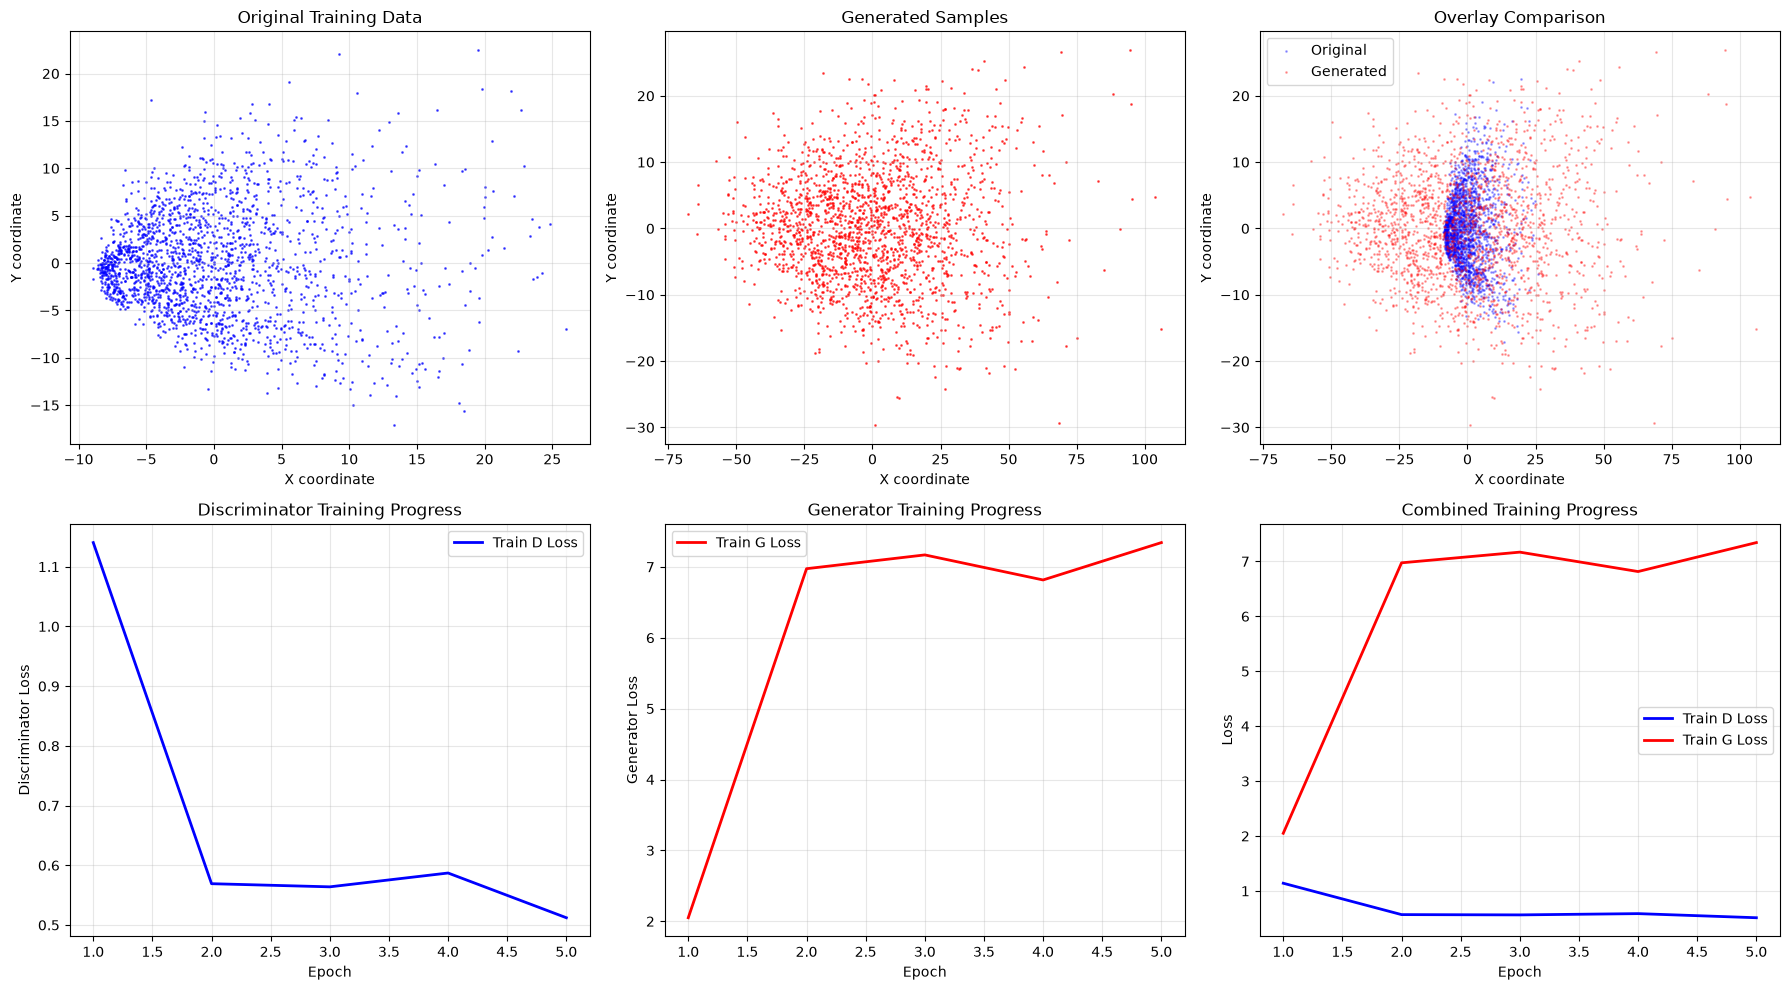

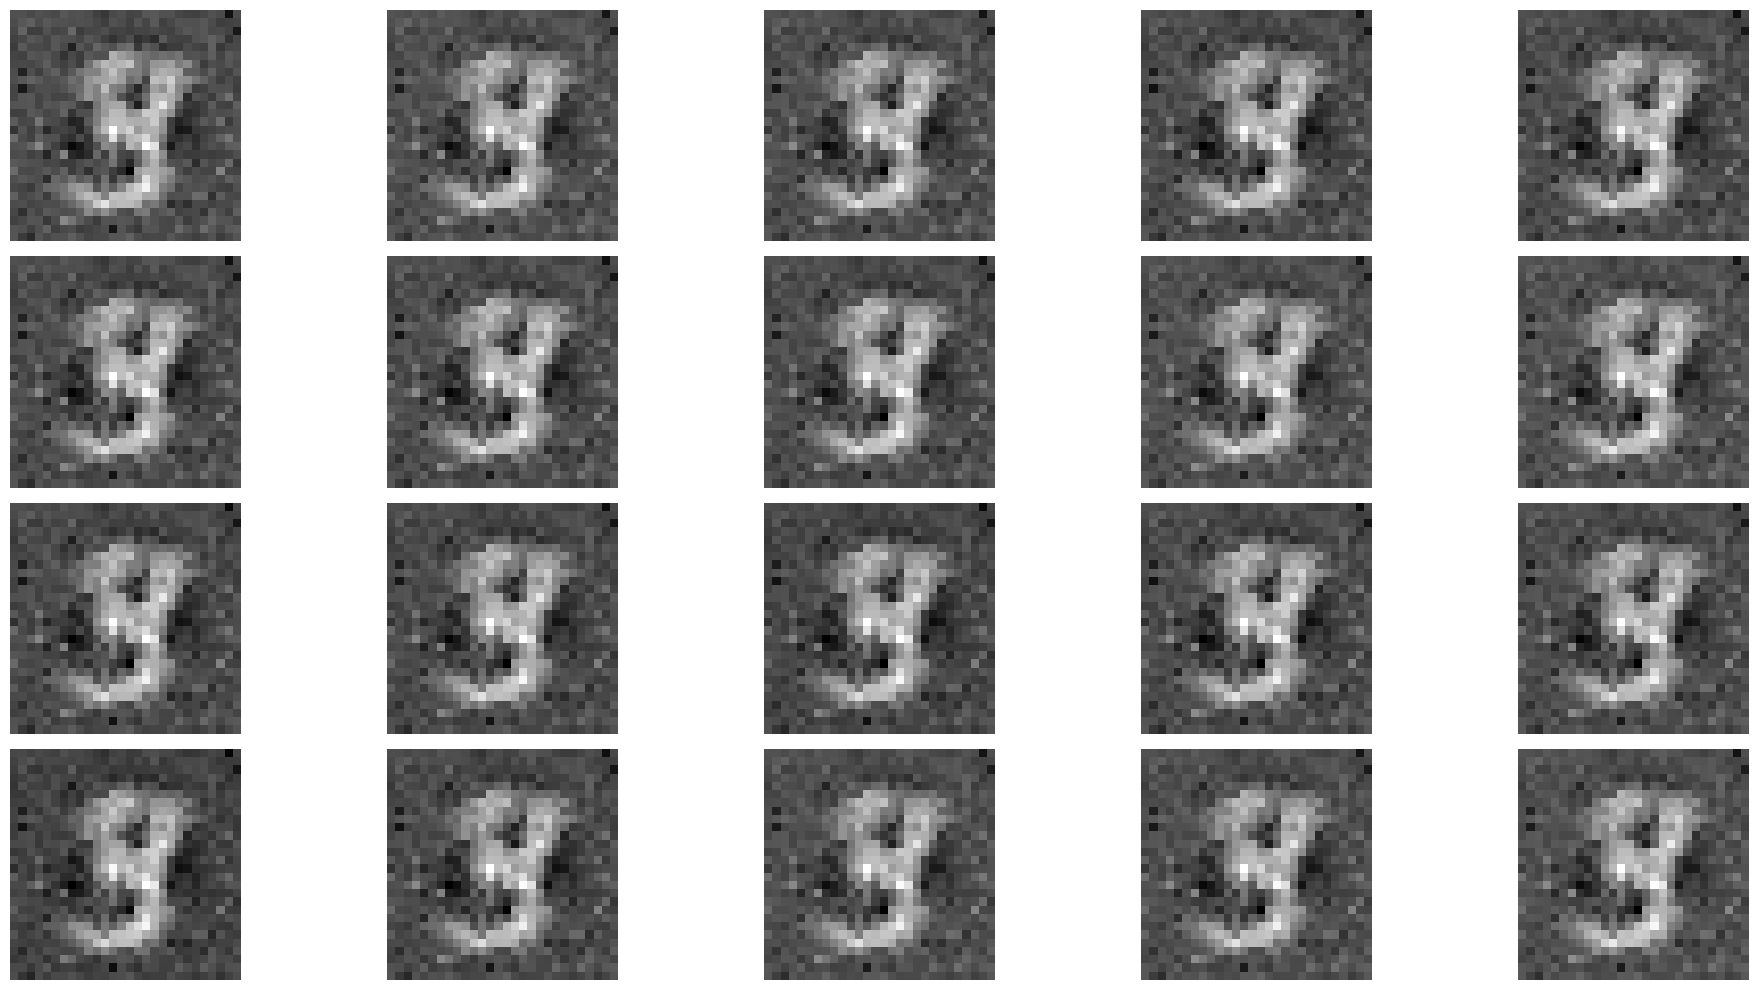

📈 Epoch 5 Summary:
   Train D Loss: 0.5122, Val D Loss: 0.2860
   Train G Loss: 7.3423, Val G Loss: 2.4907

📊 Epoch 6/100
----------------------------------------
Epoch: 6 [0/60000 (0%)]	D_loss: 0.299007	G_loss: 10.044245
Epoch: 6 [6400/60000 (11%)]	D_loss: 0.188074	G_loss: 4.176939
Epoch: 6 [12800/60000 (21%)]	D_loss: 0.371130	G_loss: 5.877928
Epoch: 6 [19200/60000 (32%)]	D_loss: 0.319642	G_loss: 4.636099
Epoch: 6 [25600/60000 (43%)]	D_loss: 0.215655	G_loss: 4.722563
Epoch: 6 [32000/60000 (53%)]	D_loss: 0.179855	G_loss: 5.603372
Epoch: 6 [38400/60000 (64%)]	D_loss: 0.260618	G_loss: 4.823739
Epoch: 6 [44800/60000 (75%)]	D_loss: 2.265161	G_loss: 15.160323
Epoch: 6 [51200/60000 (85%)]	D_loss: 0.362273	G_loss: 6.415126
Epoch: 6 [57600/60000 (96%)]	D_loss: 0.289875	G_loss: 8.164299
====> Epoch: 6 Train D_loss: 0.4898, Train G_loss: 6.9760
====> Epoch: 6 Val D_loss: 0.2804, Val G_loss: 5.4725
📈 Epoch 6 Summary:
   Train D Loss: 0.4898, Val D Loss: 0.2804
   Train G Loss: 6.9760, Val G Loss:

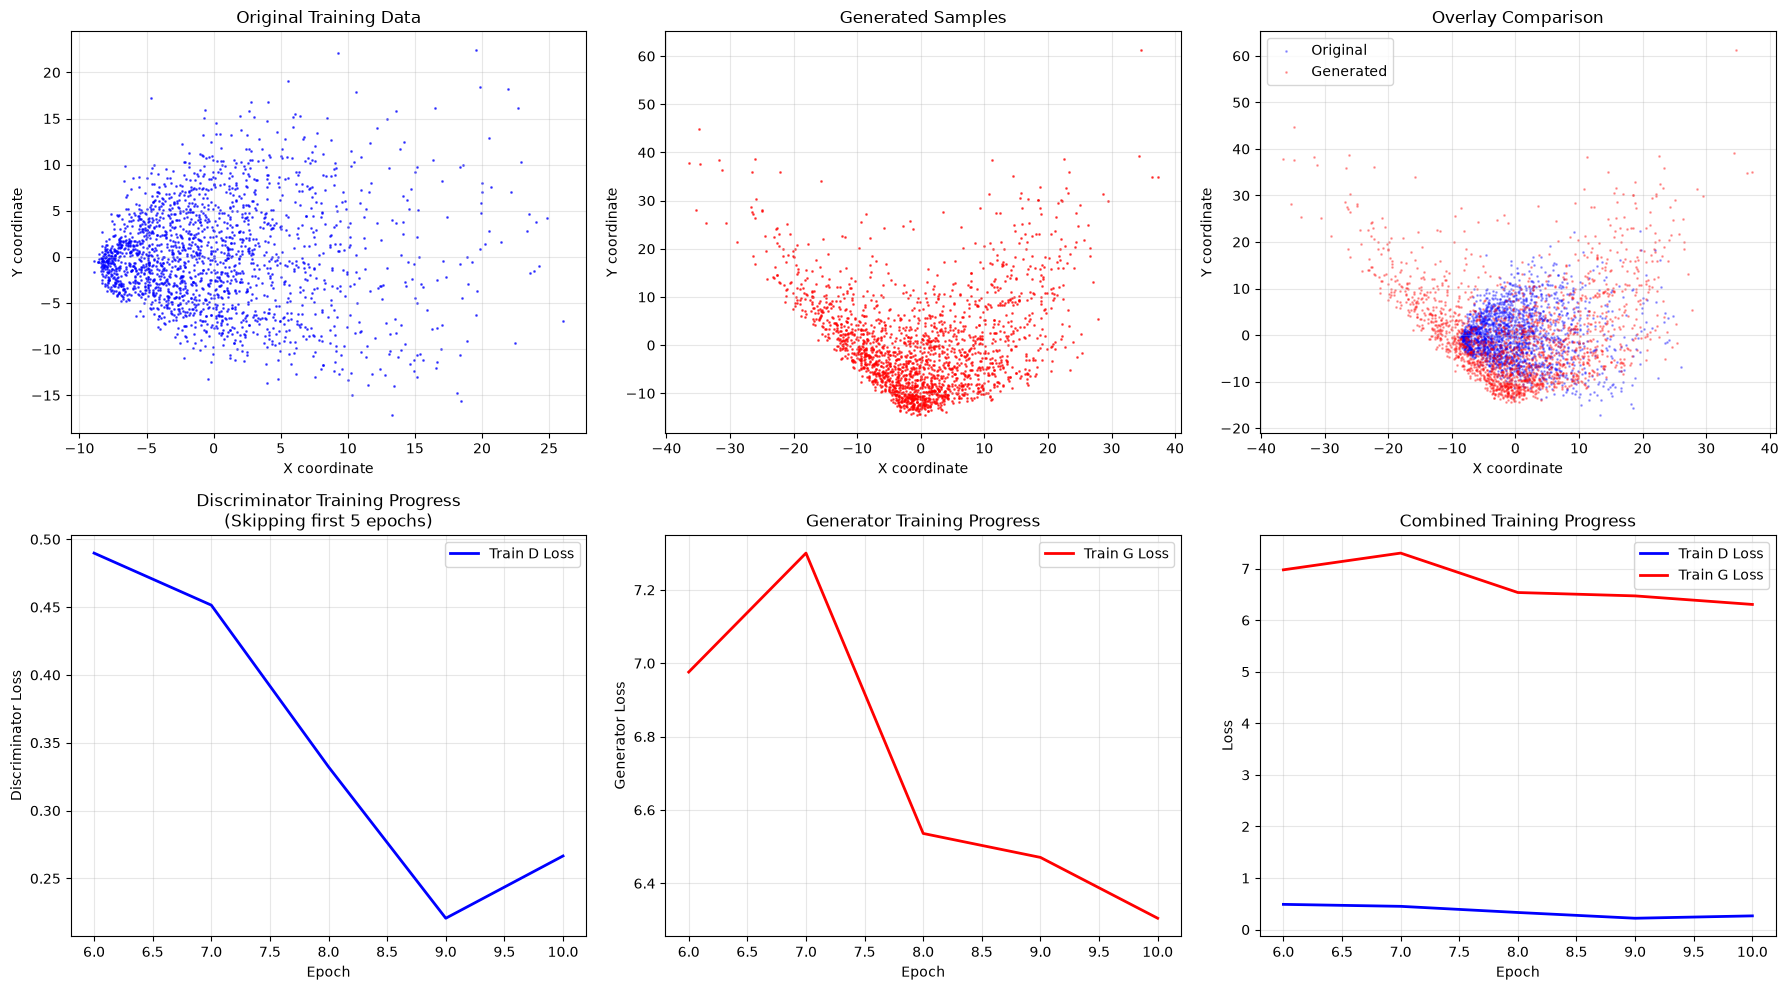

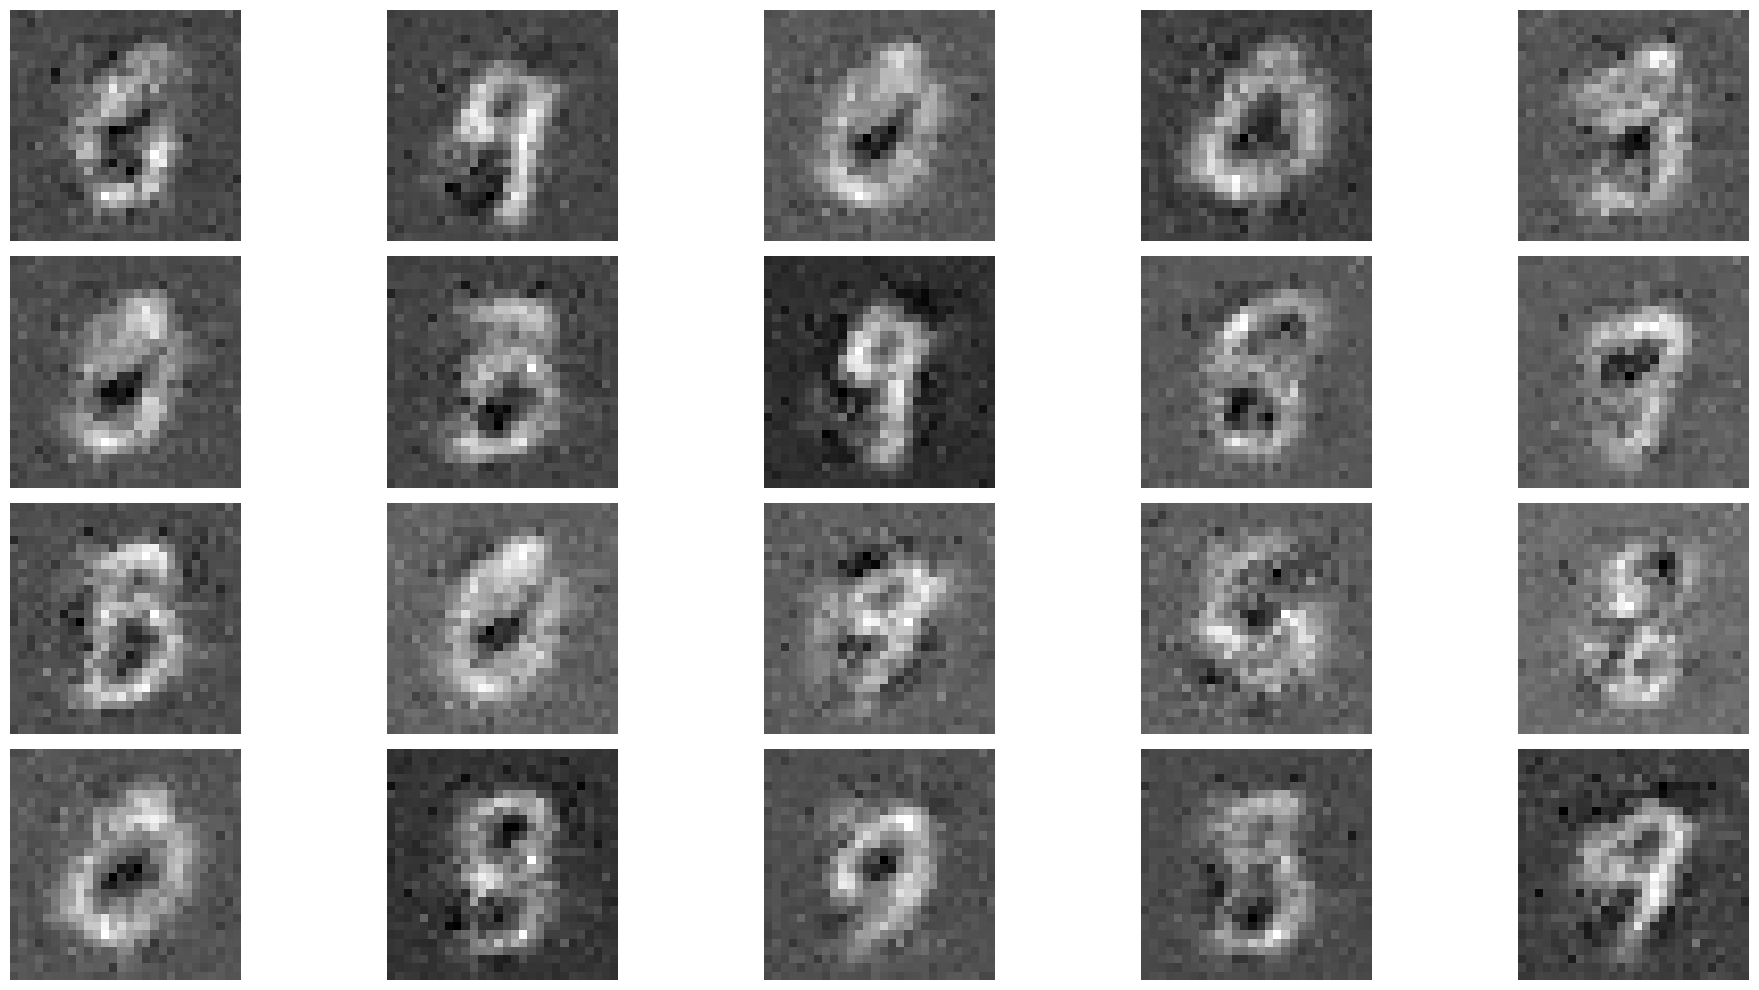

📈 Epoch 10 Summary:
   Train D Loss: 0.2666, Val D Loss: 0.1733
   Train G Loss: 6.3048, Val G Loss: 6.1750

📊 Epoch 11/100
----------------------------------------
Epoch: 11 [0/60000 (0%)]	D_loss: 0.129269	G_loss: 6.643046
Epoch: 11 [6400/60000 (11%)]	D_loss: 0.206994	G_loss: 3.721722
Epoch: 11 [12800/60000 (21%)]	D_loss: 0.146166	G_loss: 5.184144
Epoch: 11 [19200/60000 (32%)]	D_loss: 0.091198	G_loss: 5.211215
Epoch: 11 [25600/60000 (43%)]	D_loss: 0.500169	G_loss: 6.078442
Epoch: 11 [32000/60000 (53%)]	D_loss: 0.098096	G_loss: 4.157376
Epoch: 11 [38400/60000 (64%)]	D_loss: 0.067804	G_loss: 6.395983
Epoch: 11 [44800/60000 (75%)]	D_loss: 0.792858	G_loss: 16.549257
Epoch: 11 [51200/60000 (85%)]	D_loss: 0.142558	G_loss: 4.997303
Epoch: 11 [57600/60000 (96%)]	D_loss: 0.053522	G_loss: 6.063195
====> Epoch: 11 Train D_loss: 0.2406, Train G_loss: 5.7916
====> Epoch: 11 Val D_loss: 0.1537, Val G_loss: 4.1032
📈 Epoch 11 Summary:
   Train D Loss: 0.2406, Val D Loss: 0.1537
   Train G Loss: 5.791

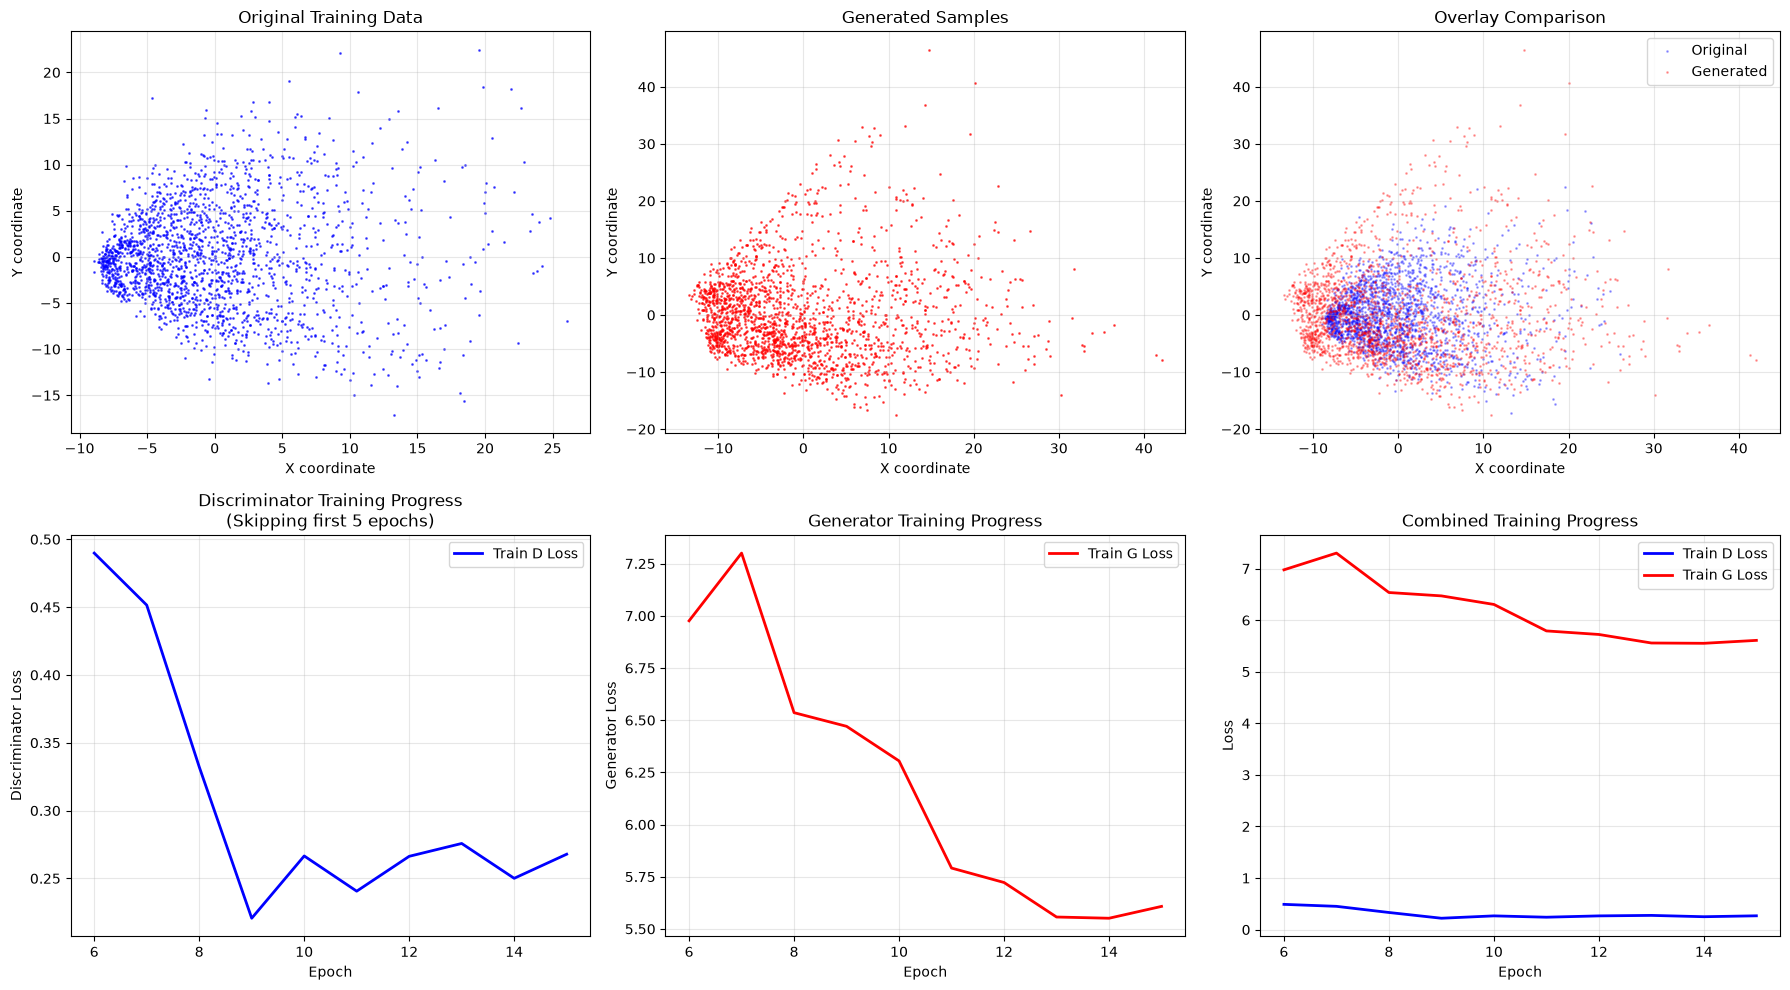

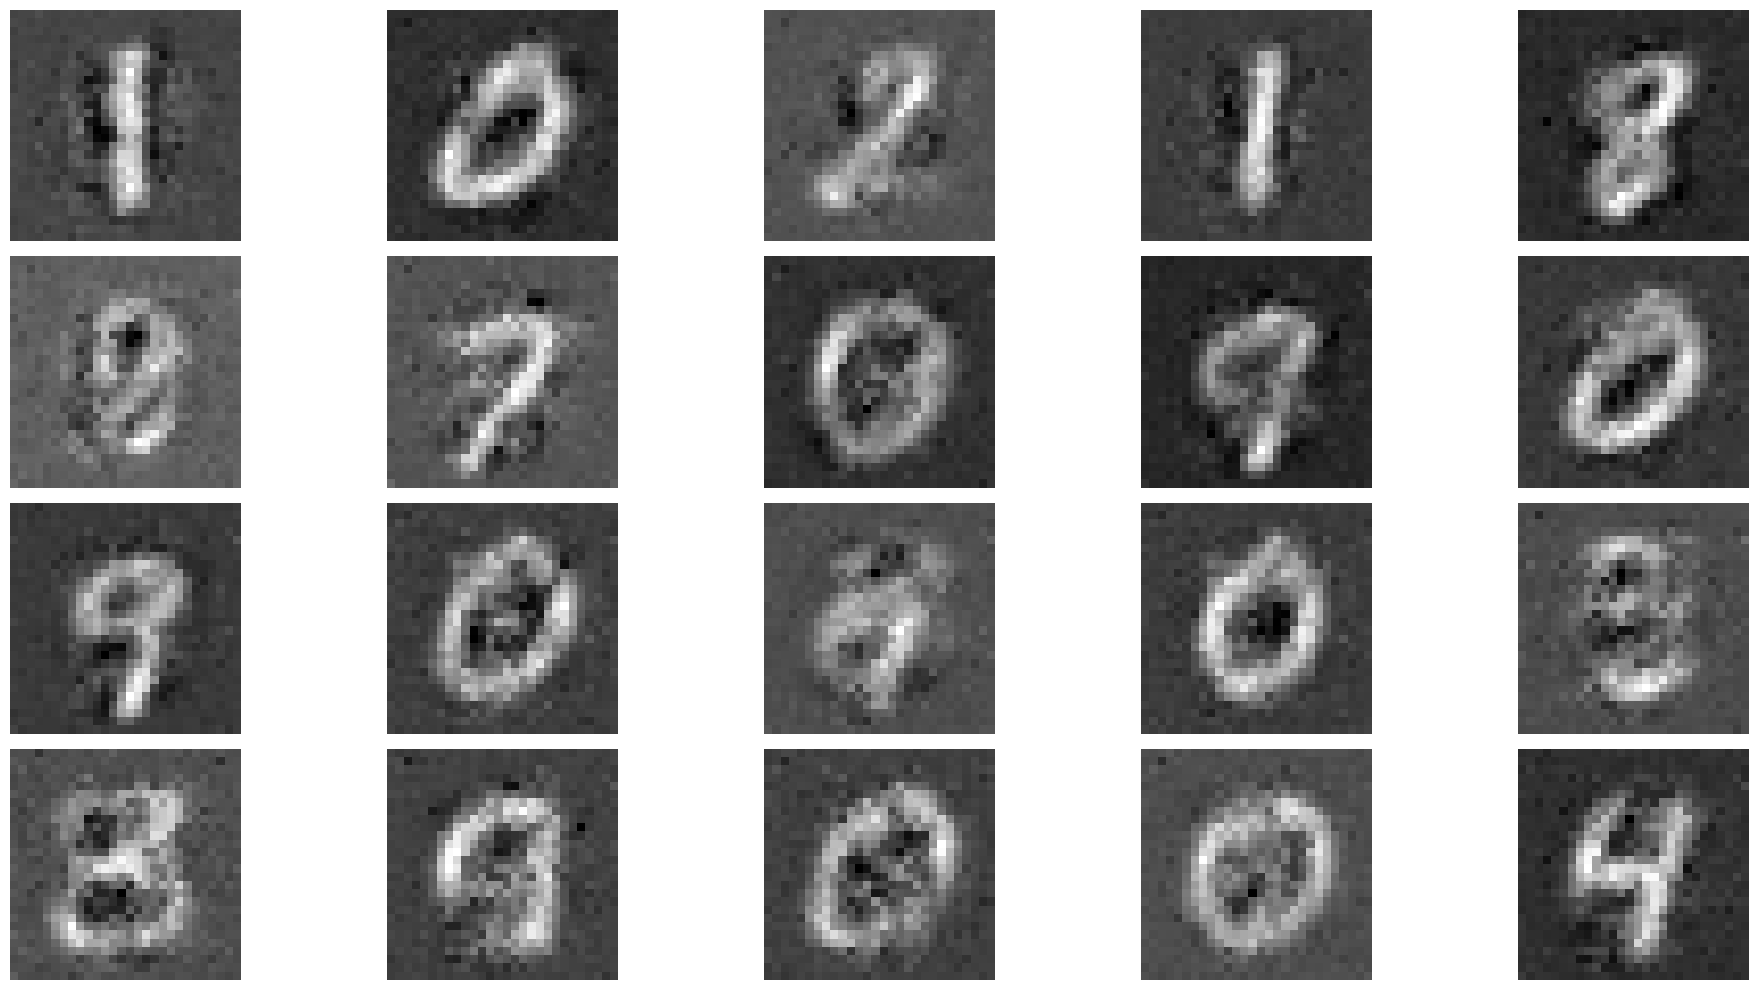

📈 Epoch 15 Summary:
   Train D Loss: 0.2678, Val D Loss: 0.1766
   Train G Loss: 5.6080, Val G Loss: 4.1144

📊 Epoch 16/100
----------------------------------------
Epoch: 16 [0/60000 (0%)]	D_loss: 0.187103	G_loss: 5.351532
Epoch: 16 [6400/60000 (11%)]	D_loss: 0.254608	G_loss: 6.523878
Epoch: 16 [12800/60000 (21%)]	D_loss: 0.161399	G_loss: 4.804424
Epoch: 16 [19200/60000 (32%)]	D_loss: 0.299480	G_loss: 7.887021
Epoch: 16 [25600/60000 (43%)]	D_loss: 0.158482	G_loss: 5.421311
Epoch: 16 [32000/60000 (53%)]	D_loss: 0.097235	G_loss: 5.554201
Epoch: 16 [38400/60000 (64%)]	D_loss: 0.266749	G_loss: 4.517669
Epoch: 16 [44800/60000 (75%)]	D_loss: 0.024859	G_loss: 8.066309
Epoch: 16 [51200/60000 (85%)]	D_loss: 0.413596	G_loss: 5.573887
Epoch: 16 [57600/60000 (96%)]	D_loss: 0.080367	G_loss: 5.589936
====> Epoch: 16 Train D_loss: 0.2555, Train G_loss: 5.6646
====> Epoch: 16 Val D_loss: 0.4824, Val G_loss: 8.1814
📈 Epoch 16 Summary:
   Train D Loss: 0.2555, Val D Loss: 0.4824
   Train G Loss: 5.6646

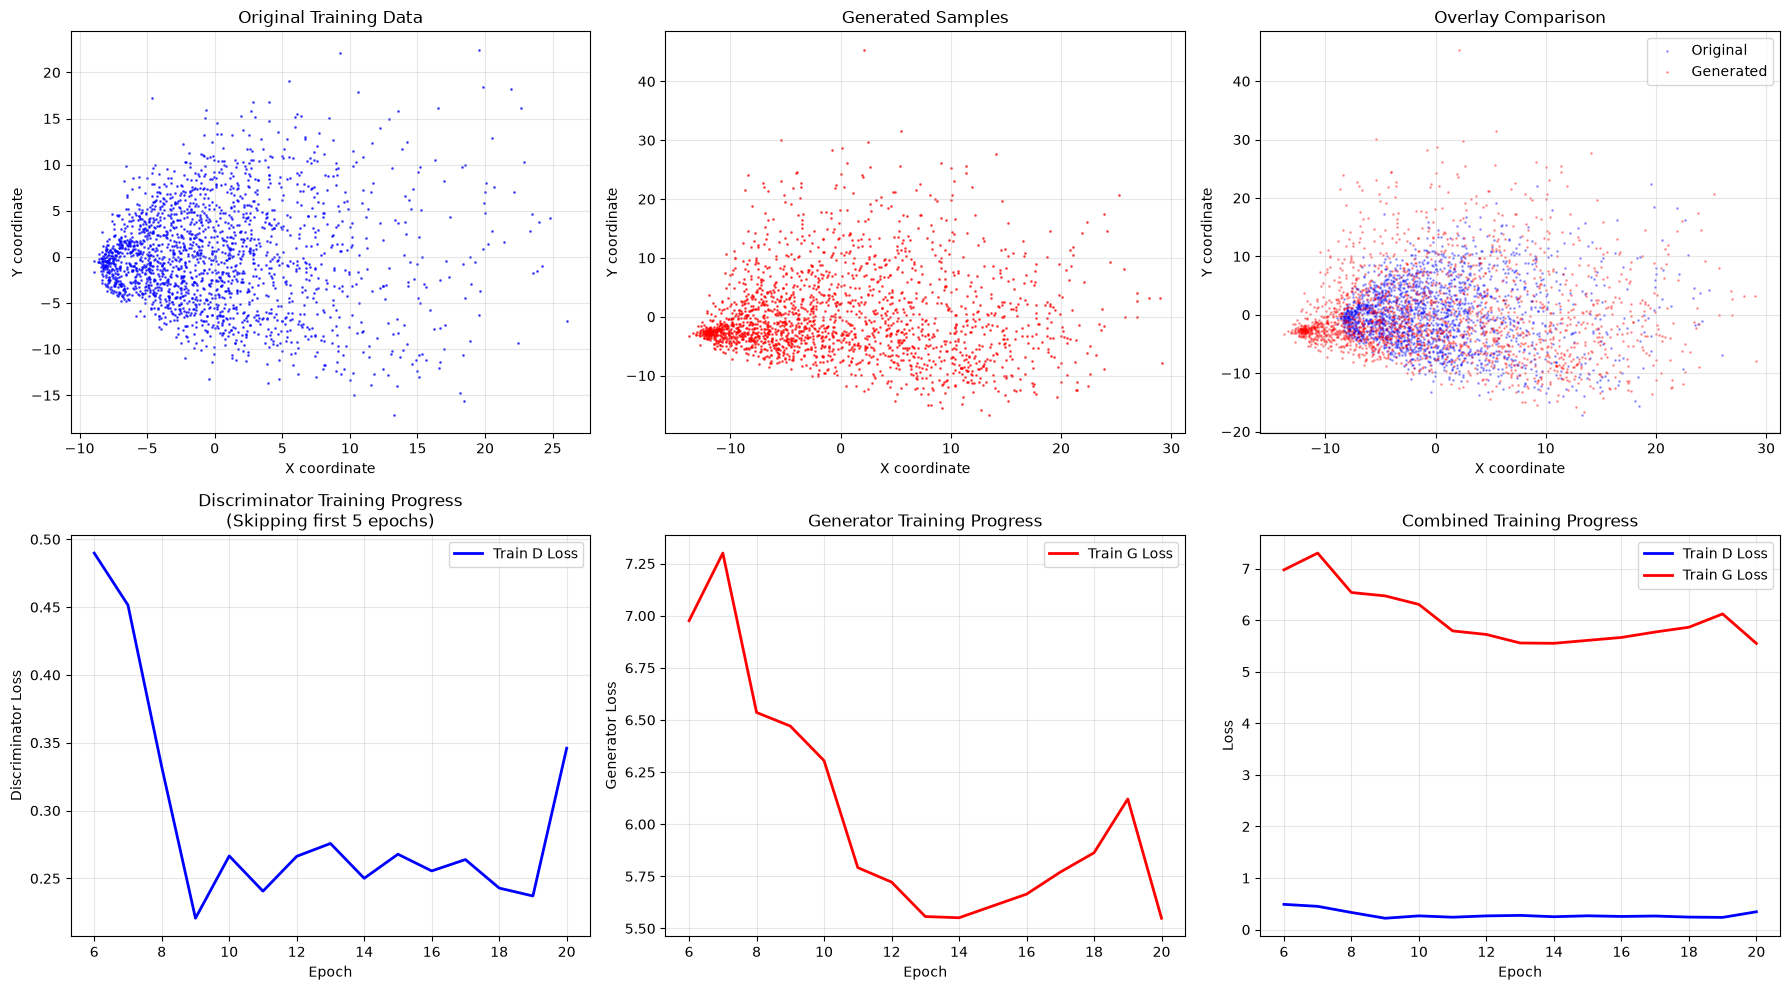

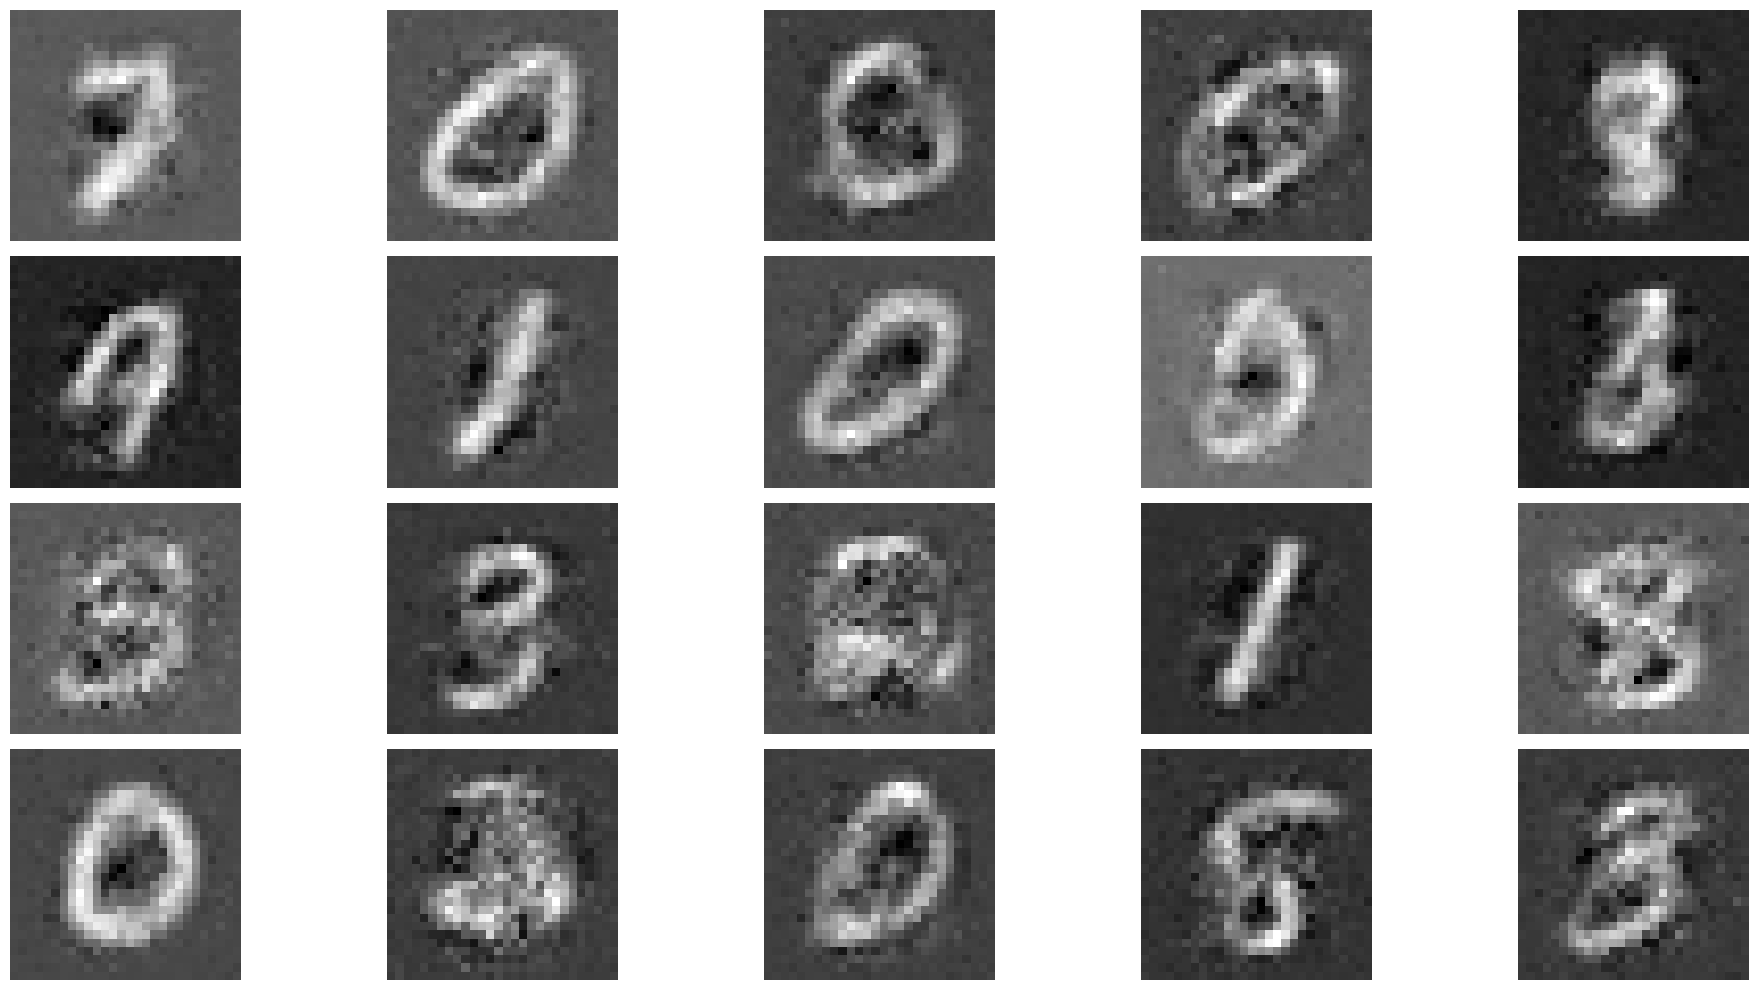

📈 Epoch 20 Summary:
   Train D Loss: 0.3460, Val D Loss: 0.1423
   Train G Loss: 5.5490, Val G Loss: 3.8411

📊 Epoch 21/100
----------------------------------------
Epoch: 21 [0/60000 (0%)]	D_loss: 0.106687	G_loss: 4.348904
Epoch: 21 [6400/60000 (11%)]	D_loss: 0.093383	G_loss: 4.175414
Epoch: 21 [12800/60000 (21%)]	D_loss: 0.392894	G_loss: 3.147634
Epoch: 21 [19200/60000 (32%)]	D_loss: 0.167914	G_loss: 5.102695
Epoch: 21 [25600/60000 (43%)]	D_loss: 0.146904	G_loss: 7.219673
Epoch: 21 [32000/60000 (53%)]	D_loss: 0.193490	G_loss: 4.766842
Epoch: 21 [38400/60000 (64%)]	D_loss: 0.102261	G_loss: 6.243354
Epoch: 21 [44800/60000 (75%)]	D_loss: 0.040306	G_loss: 6.875638
Epoch: 21 [51200/60000 (85%)]	D_loss: 0.191067	G_loss: 4.894927
Epoch: 21 [57600/60000 (96%)]	D_loss: 0.235253	G_loss: 5.260361
====> Epoch: 21 Train D_loss: 0.2276, Train G_loss: 5.8639
====> Epoch: 21 Val D_loss: 0.1256, Val G_loss: 5.4508
📈 Epoch 21 Summary:
   Train D Loss: 0.2276, Val D Loss: 0.1256
   Train G Loss: 5.8639

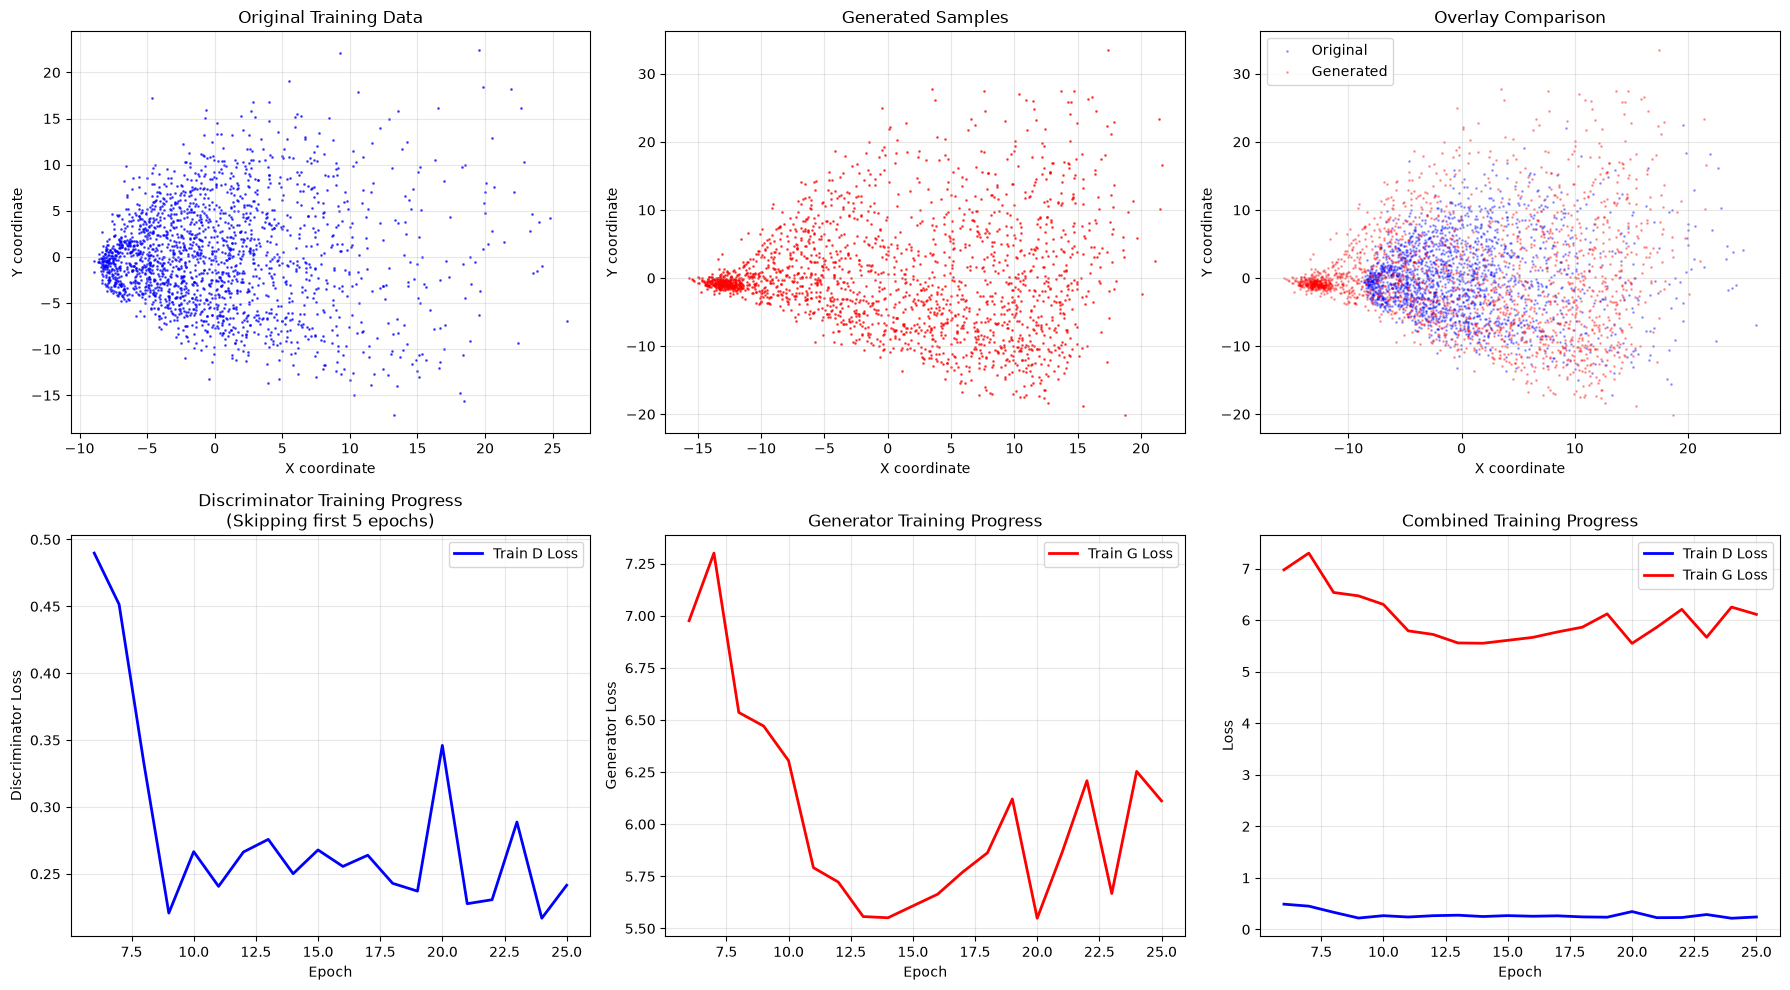

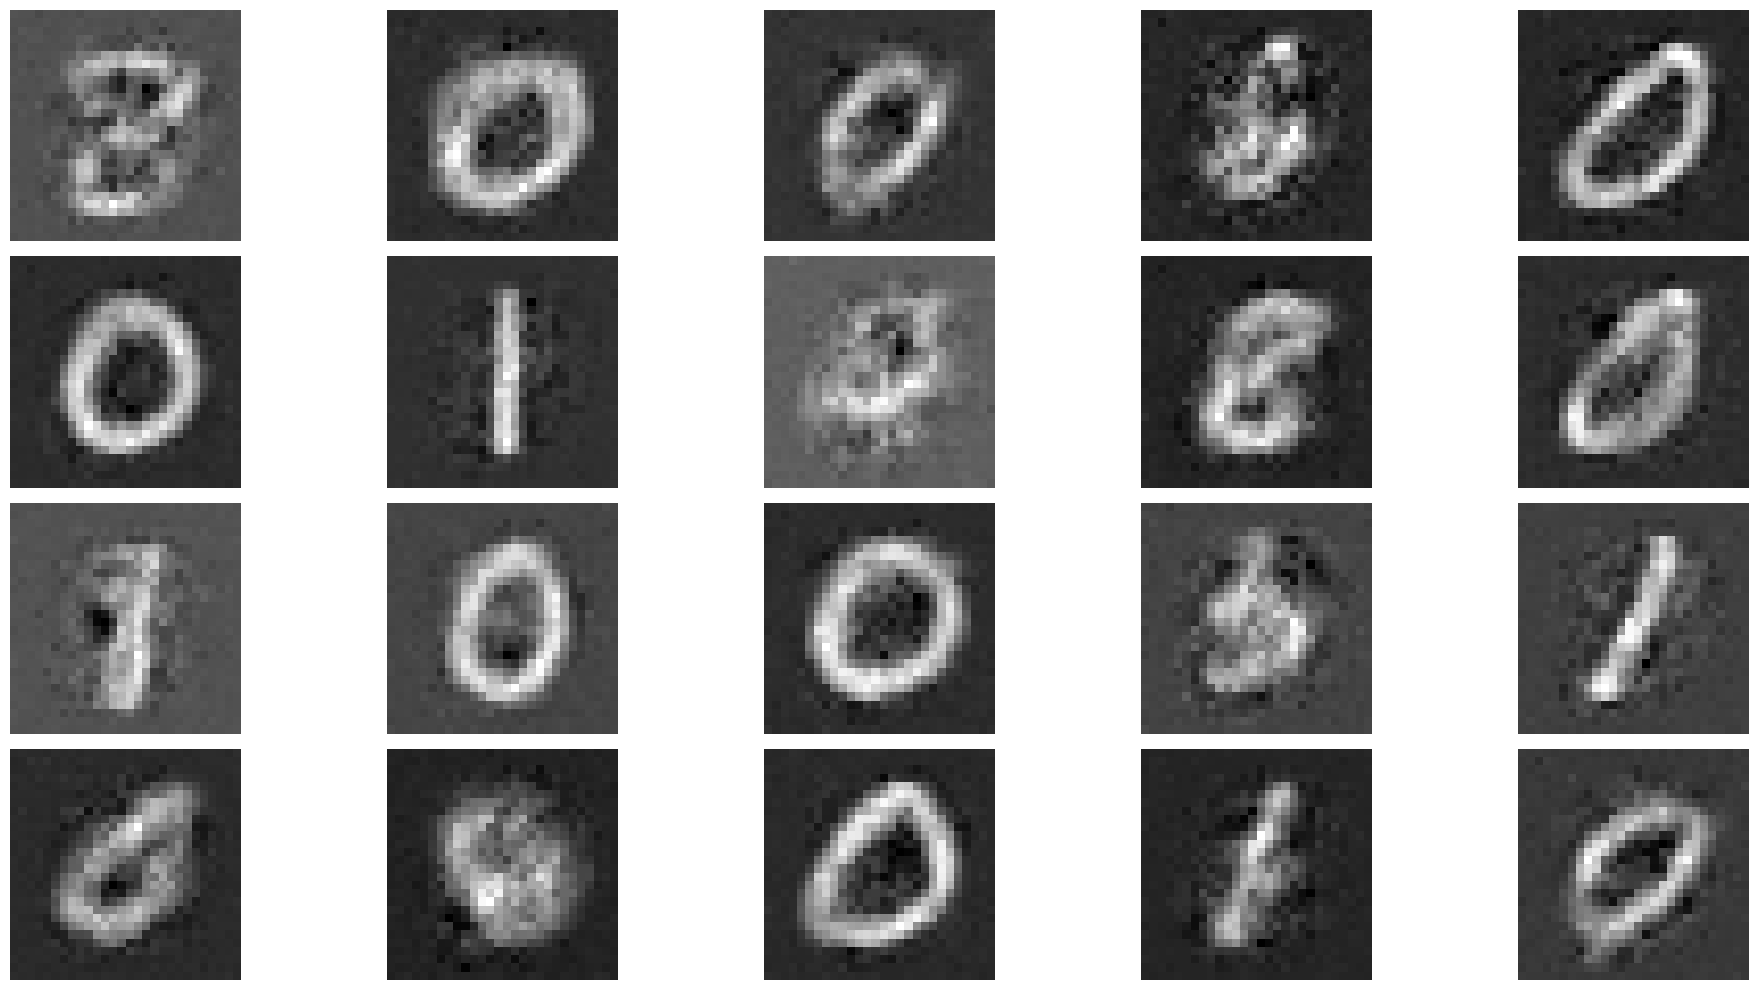

📈 Epoch 25 Summary:
   Train D Loss: 0.2414, Val D Loss: 0.2117
   Train G Loss: 6.1118, Val G Loss: 8.2430

📊 Epoch 26/100
----------------------------------------
Epoch: 26 [0/60000 (0%)]	D_loss: 0.091856	G_loss: 7.711061
Epoch: 26 [6400/60000 (11%)]	D_loss: 0.187703	G_loss: 5.489187
Epoch: 26 [12800/60000 (21%)]	D_loss: 0.447320	G_loss: 6.840692
Epoch: 26 [19200/60000 (32%)]	D_loss: 0.174853	G_loss: 5.763882
Epoch: 26 [25600/60000 (43%)]	D_loss: 0.477995	G_loss: 10.889701
Epoch: 26 [32000/60000 (53%)]	D_loss: 0.258136	G_loss: 5.444225
Epoch: 26 [38400/60000 (64%)]	D_loss: 0.338186	G_loss: 3.713065
Epoch: 26 [44800/60000 (75%)]	D_loss: 0.279399	G_loss: 3.753671
Epoch: 26 [51200/60000 (85%)]	D_loss: 0.128975	G_loss: 3.941442
Epoch: 26 [57600/60000 (96%)]	D_loss: 0.216679	G_loss: 4.608487
====> Epoch: 26 Train D_loss: 0.3100, Train G_loss: 5.7688
====> Epoch: 26 Val D_loss: 0.4450, Val G_loss: 2.8814
📈 Epoch 26 Summary:
   Train D Loss: 0.3100, Val D Loss: 0.4450
   Train G Loss: 5.768

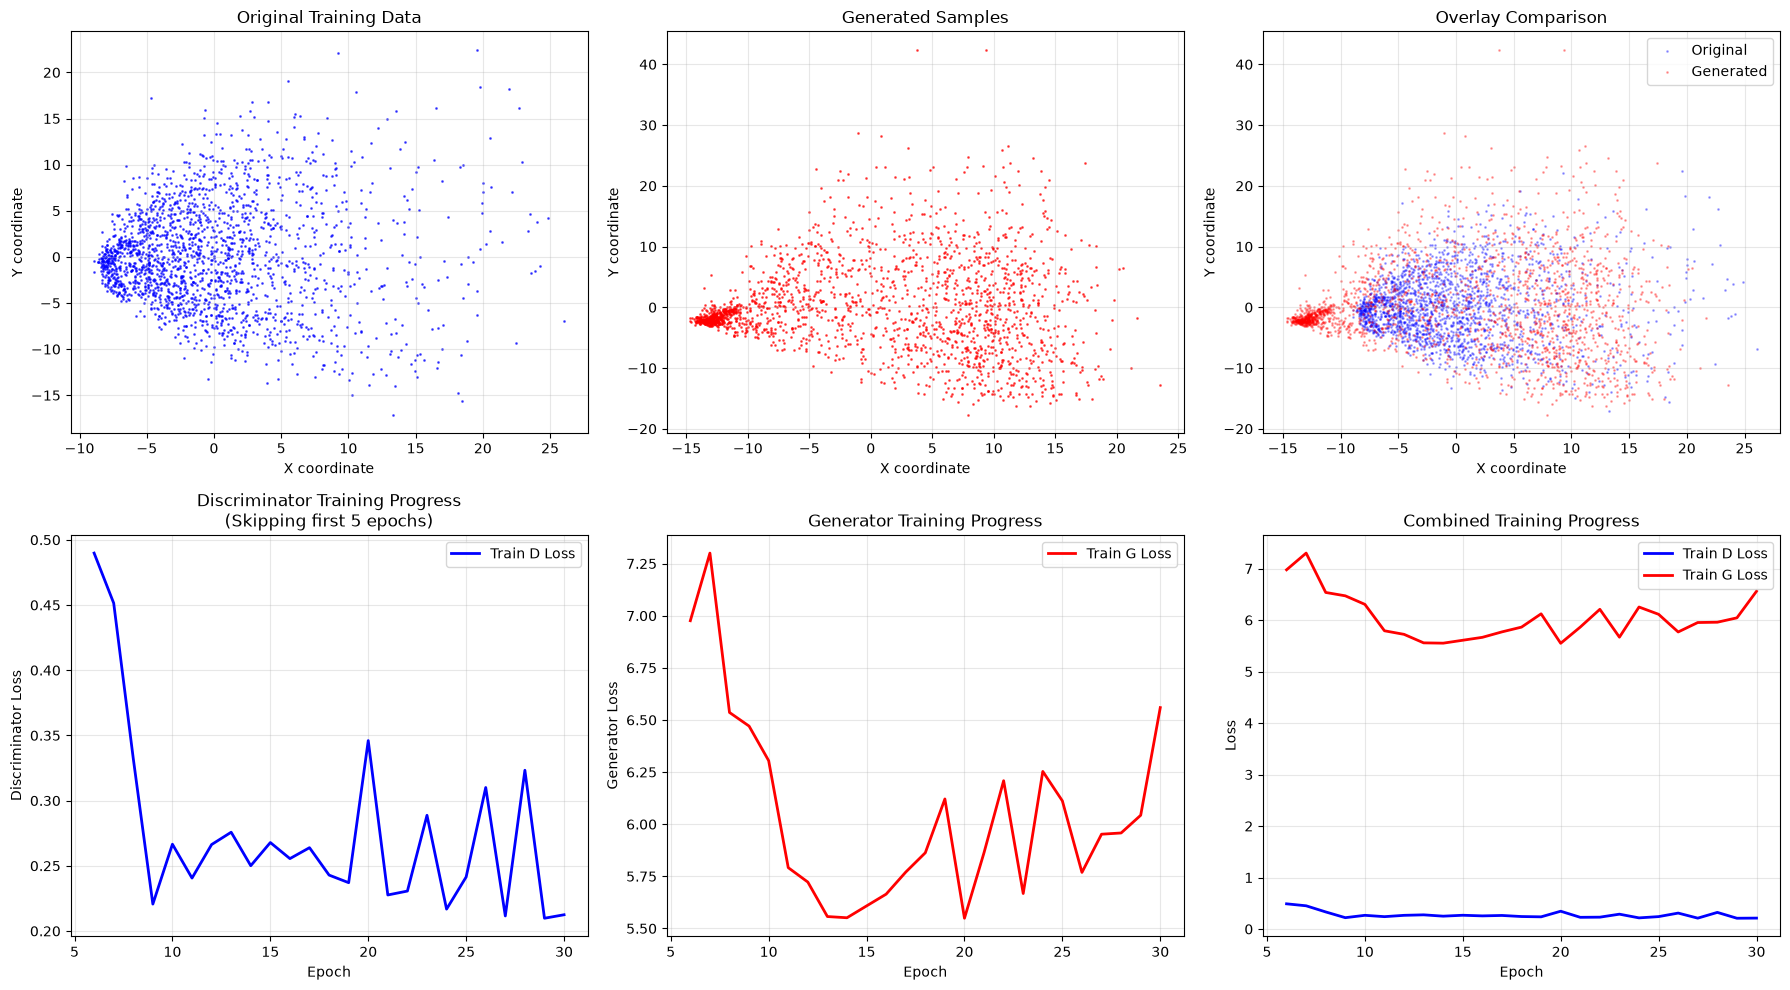

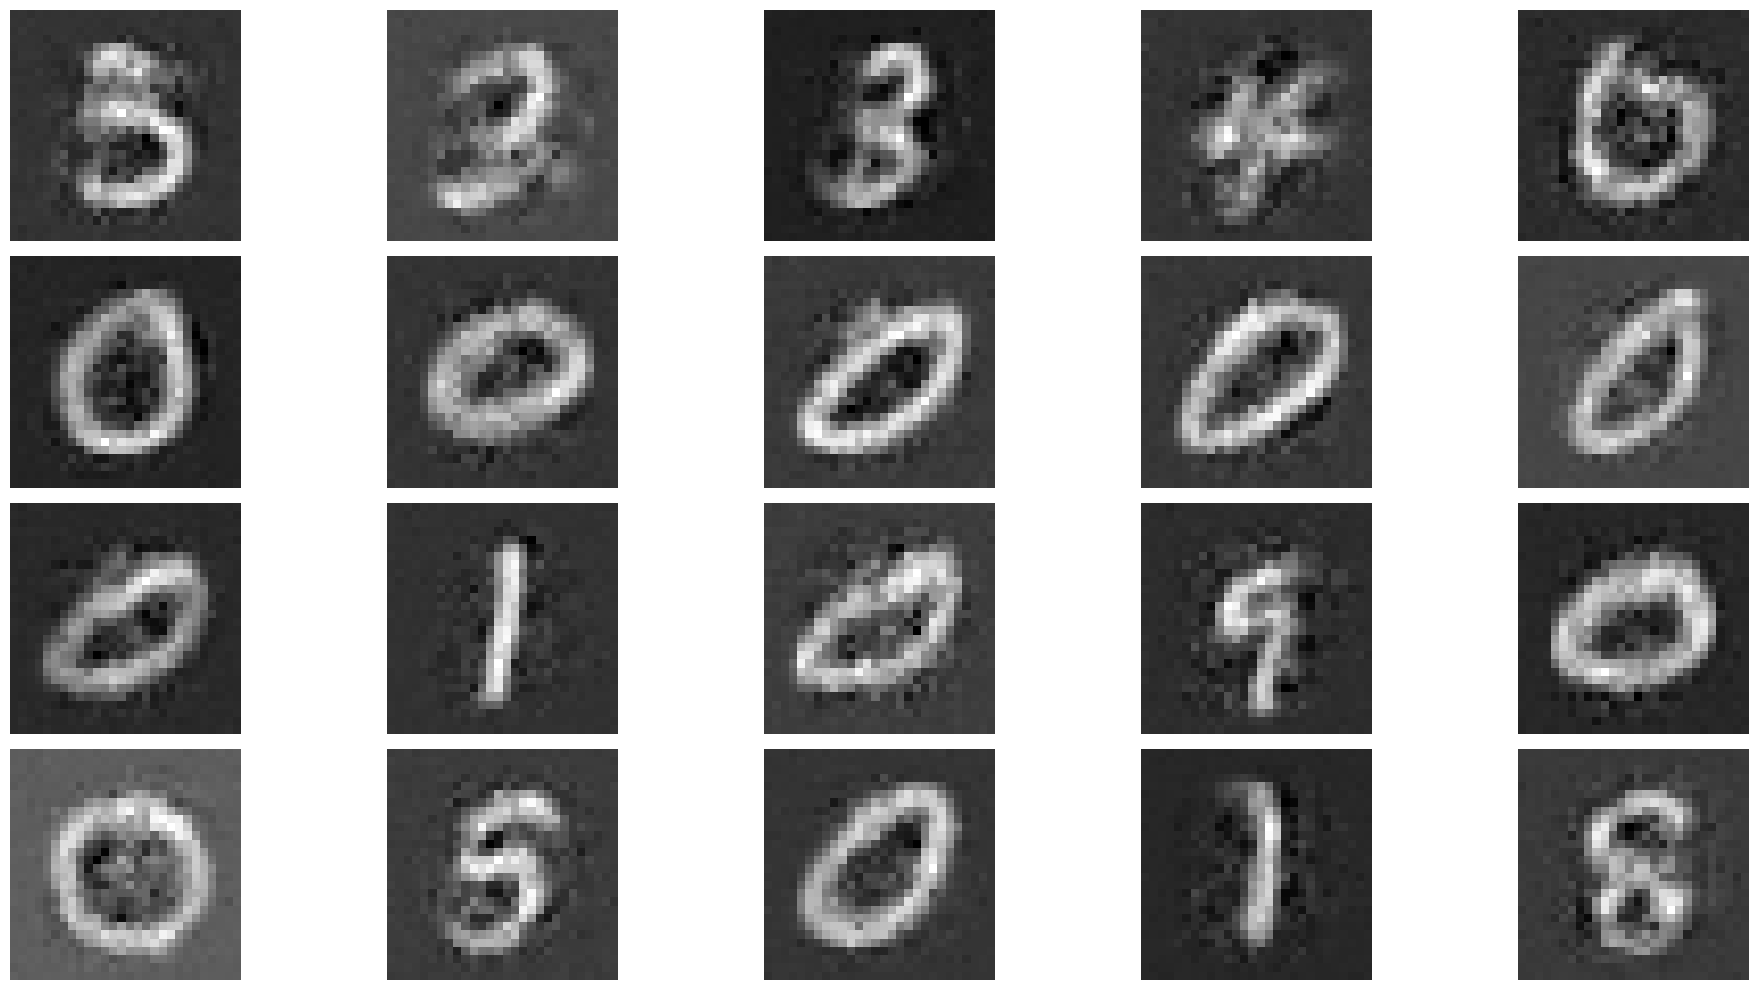

📈 Epoch 30 Summary:
   Train D Loss: 0.2125, Val D Loss: 0.4014
   Train G Loss: 6.5592, Val G Loss: 4.5075

📊 Epoch 31/100
----------------------------------------
Epoch: 31 [0/60000 (0%)]	D_loss: 0.427204	G_loss: 8.764217
Epoch: 31 [6400/60000 (11%)]	D_loss: 0.116206	G_loss: 6.348030
Epoch: 31 [12800/60000 (21%)]	D_loss: 0.137624	G_loss: 5.420457
Epoch: 31 [19200/60000 (32%)]	D_loss: 0.062070	G_loss: 8.375628
Epoch: 31 [25600/60000 (43%)]	D_loss: 0.305221	G_loss: 9.398025
Epoch: 31 [32000/60000 (53%)]	D_loss: 0.057322	G_loss: 6.354582
Epoch: 31 [38400/60000 (64%)]	D_loss: 0.896652	G_loss: 8.713675
Epoch: 31 [44800/60000 (75%)]	D_loss: 0.087948	G_loss: 4.764198
Epoch: 31 [51200/60000 (85%)]	D_loss: 0.313042	G_loss: 6.786198
Epoch: 31 [57600/60000 (96%)]	D_loss: 0.145970	G_loss: 8.467882
====> Epoch: 31 Train D_loss: 0.1948, Train G_loss: 6.6468
====> Epoch: 31 Val D_loss: 0.3661, Val G_loss: 4.8646
📈 Epoch 31 Summary:
   Train D Loss: 0.1948, Val D Loss: 0.3661
   Train G Loss: 6.6468

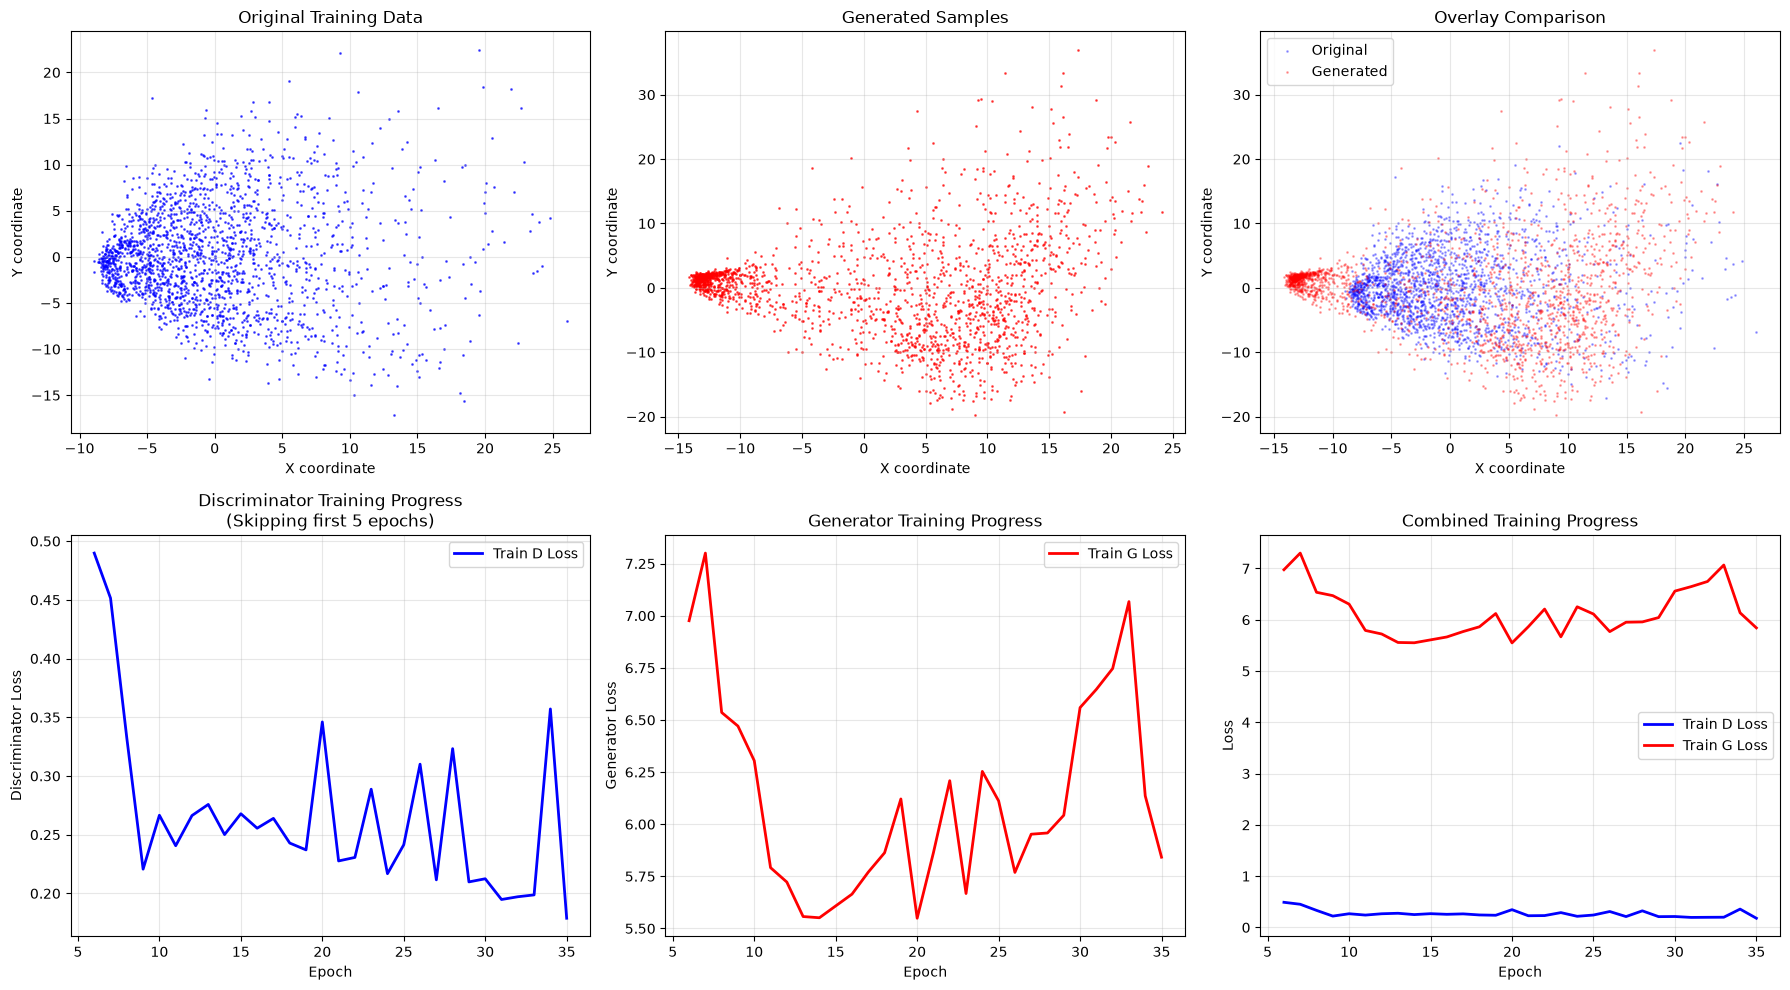

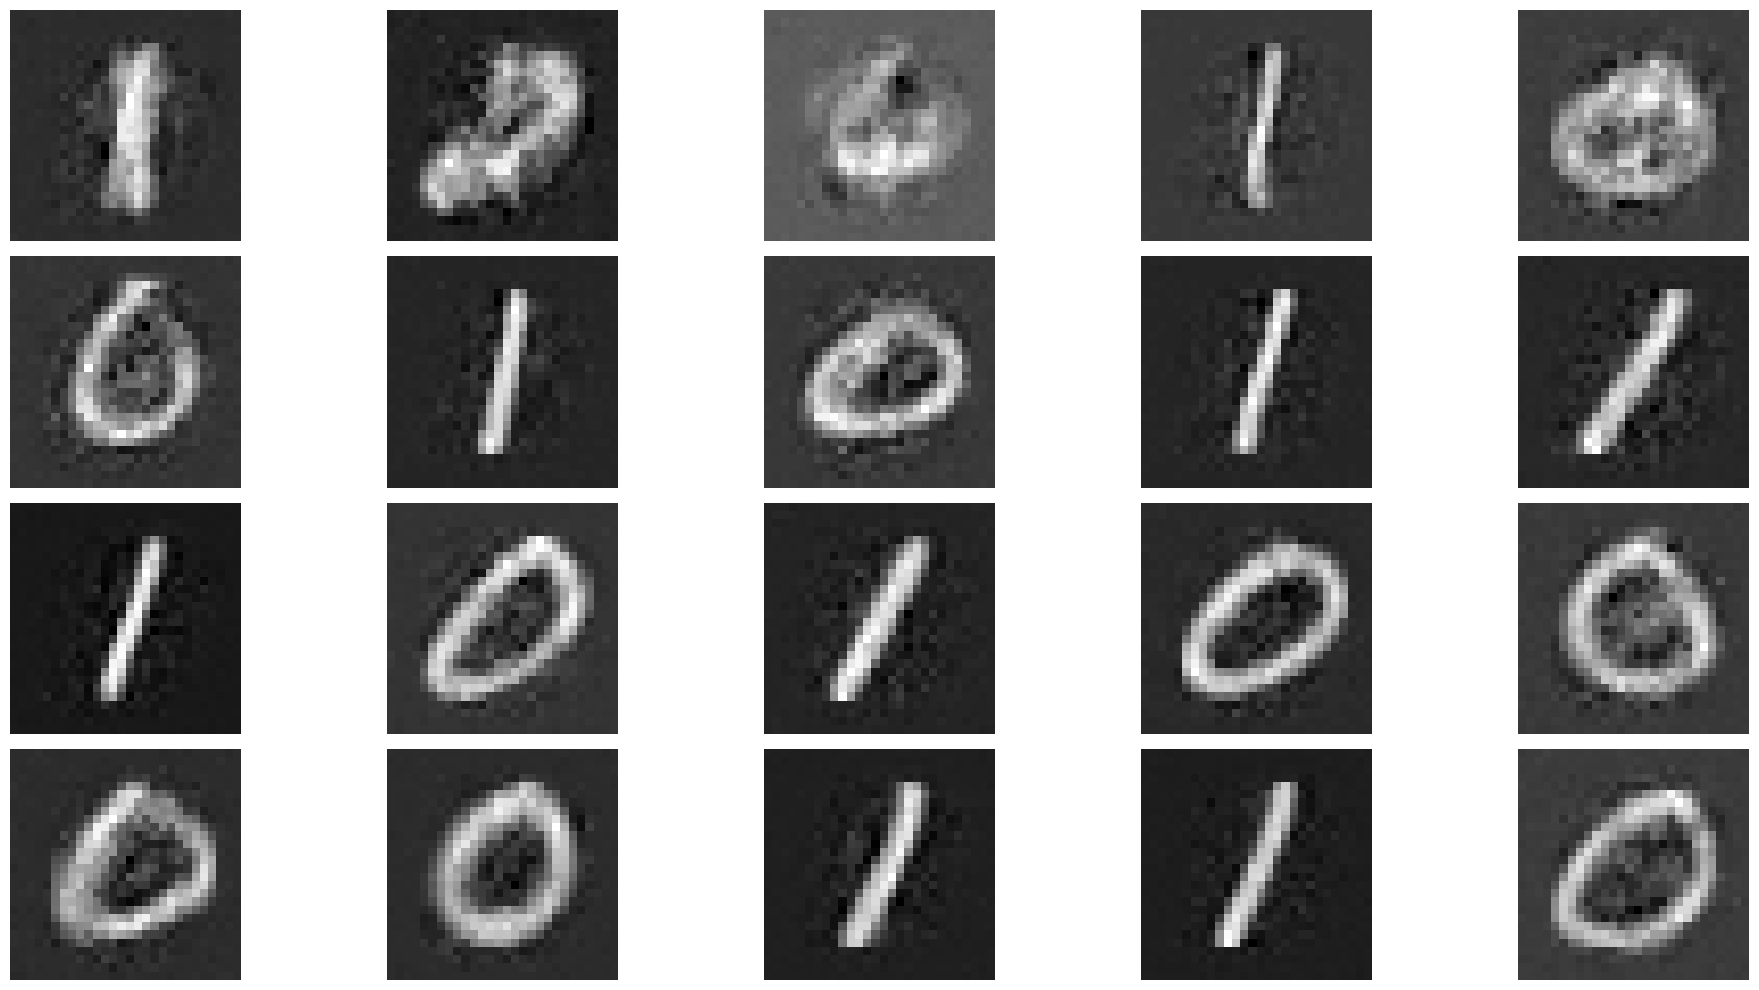

📈 Epoch 35 Summary:
   Train D Loss: 0.1788, Val D Loss: 0.2541
   Train G Loss: 5.8418, Val G Loss: 7.7417

📊 Epoch 36/100
----------------------------------------
Epoch: 36 [0/60000 (0%)]	D_loss: 0.165139	G_loss: 6.081304
Epoch: 36 [6400/60000 (11%)]	D_loss: 0.189330	G_loss: 4.865379
Epoch: 36 [12800/60000 (21%)]	D_loss: 0.135721	G_loss: 7.757751
Epoch: 36 [19200/60000 (32%)]	D_loss: 0.257780	G_loss: 6.043591
Epoch: 36 [25600/60000 (43%)]	D_loss: 0.249957	G_loss: 5.594131
Epoch: 36 [32000/60000 (53%)]	D_loss: 0.120063	G_loss: 5.613599
Epoch: 36 [38400/60000 (64%)]	D_loss: 0.118845	G_loss: 6.808582
Epoch: 36 [44800/60000 (75%)]	D_loss: 0.361246	G_loss: 4.717969
Epoch: 36 [51200/60000 (85%)]	D_loss: 0.207670	G_loss: 7.988723
Epoch: 36 [57600/60000 (96%)]	D_loss: 0.150182	G_loss: 5.626147
====> Epoch: 36 Train D_loss: 0.2053, Train G_loss: 6.7042
====> Epoch: 36 Val D_loss: 0.1997, Val G_loss: 4.4804
📈 Epoch 36 Summary:
   Train D Loss: 0.2053, Val D Loss: 0.1997
   Train G Loss: 6.7042

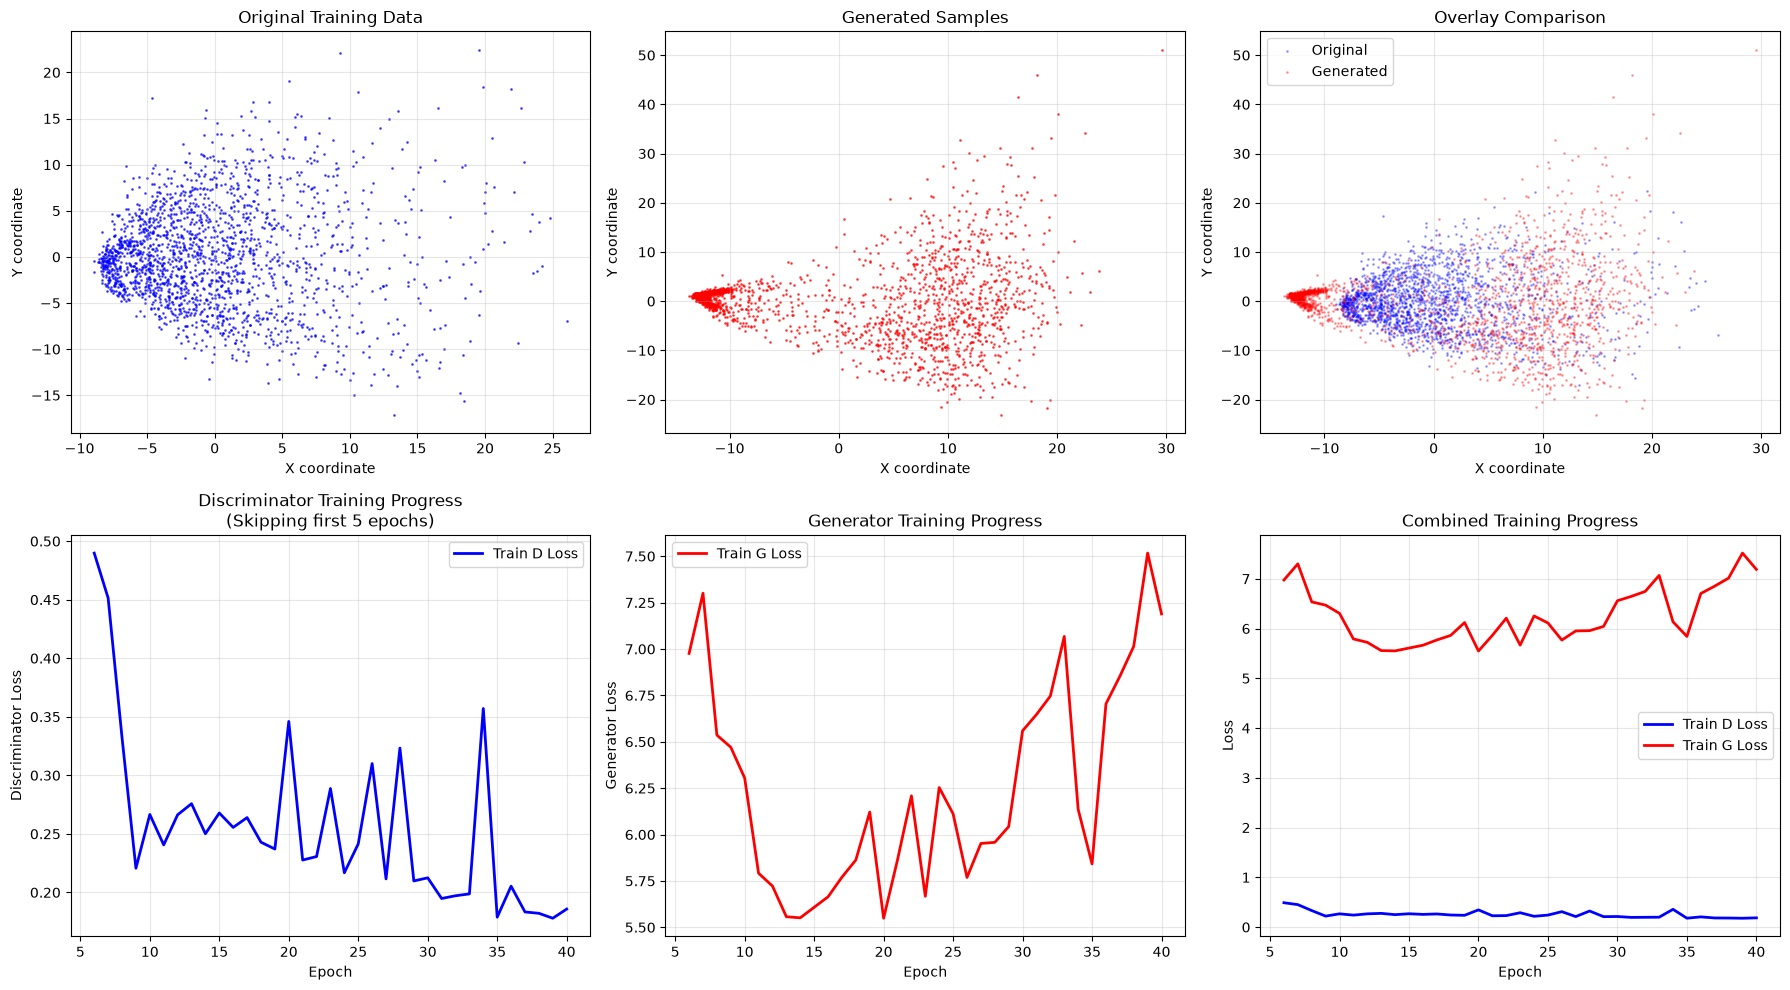

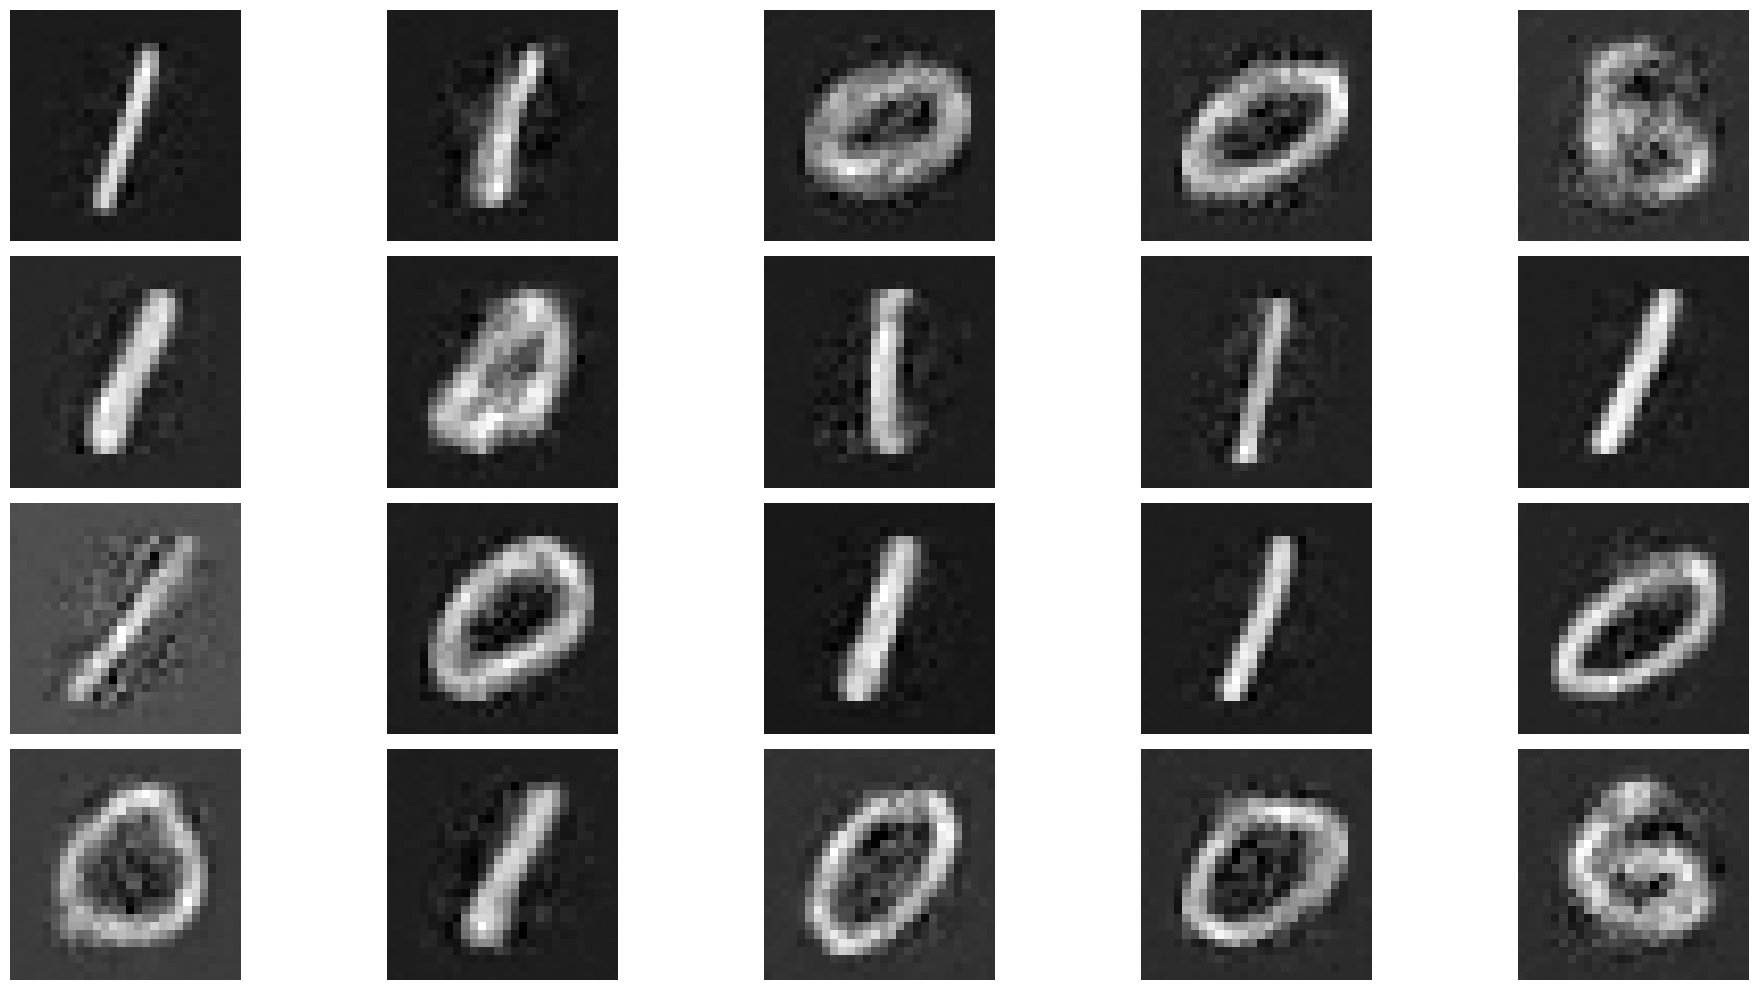

📈 Epoch 40 Summary:
   Train D Loss: 0.1858, Val D Loss: 0.2162
   Train G Loss: 7.1890, Val G Loss: 7.4749

📊 Epoch 41/100
----------------------------------------
Epoch: 41 [0/60000 (0%)]	D_loss: 0.128153	G_loss: 7.971963
Epoch: 41 [6400/60000 (11%)]	D_loss: 0.174976	G_loss: 6.275019
Epoch: 41 [12800/60000 (21%)]	D_loss: 0.153179	G_loss: 6.309481
Epoch: 41 [19200/60000 (32%)]	D_loss: 0.209625	G_loss: 10.507143
Epoch: 41 [25600/60000 (43%)]	D_loss: 0.411856	G_loss: 4.508785
Epoch: 41 [32000/60000 (53%)]	D_loss: 0.379055	G_loss: 5.066157
Epoch: 41 [38400/60000 (64%)]	D_loss: 0.342939	G_loss: 7.024242
Epoch: 41 [44800/60000 (75%)]	D_loss: 0.167495	G_loss: 4.594739
Epoch: 41 [51200/60000 (85%)]	D_loss: 0.199956	G_loss: 5.415206
Epoch: 41 [57600/60000 (96%)]	D_loss: 0.091039	G_loss: 6.205804
====> Epoch: 41 Train D_loss: 0.3877, Train G_loss: 6.4086
====> Epoch: 41 Val D_loss: 0.2024, Val G_loss: 3.7139
📈 Epoch 41 Summary:
   Train D Loss: 0.3877, Val D Loss: 0.2024
   Train G Loss: 6.408

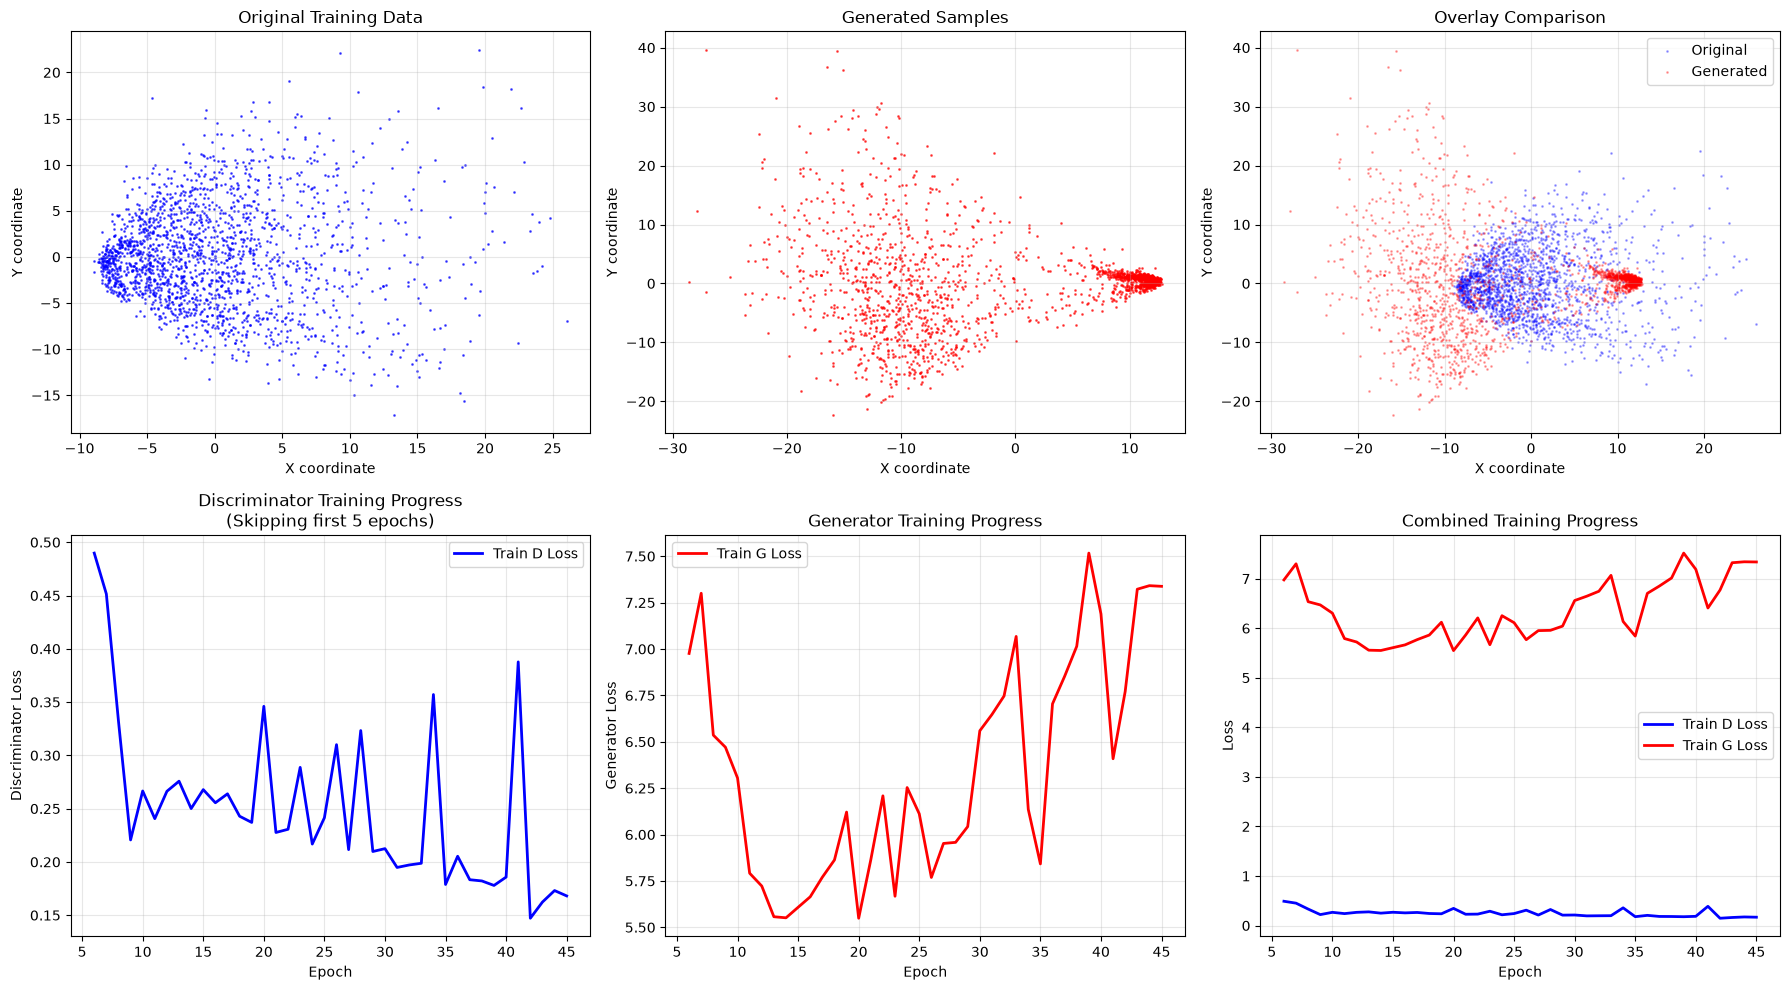

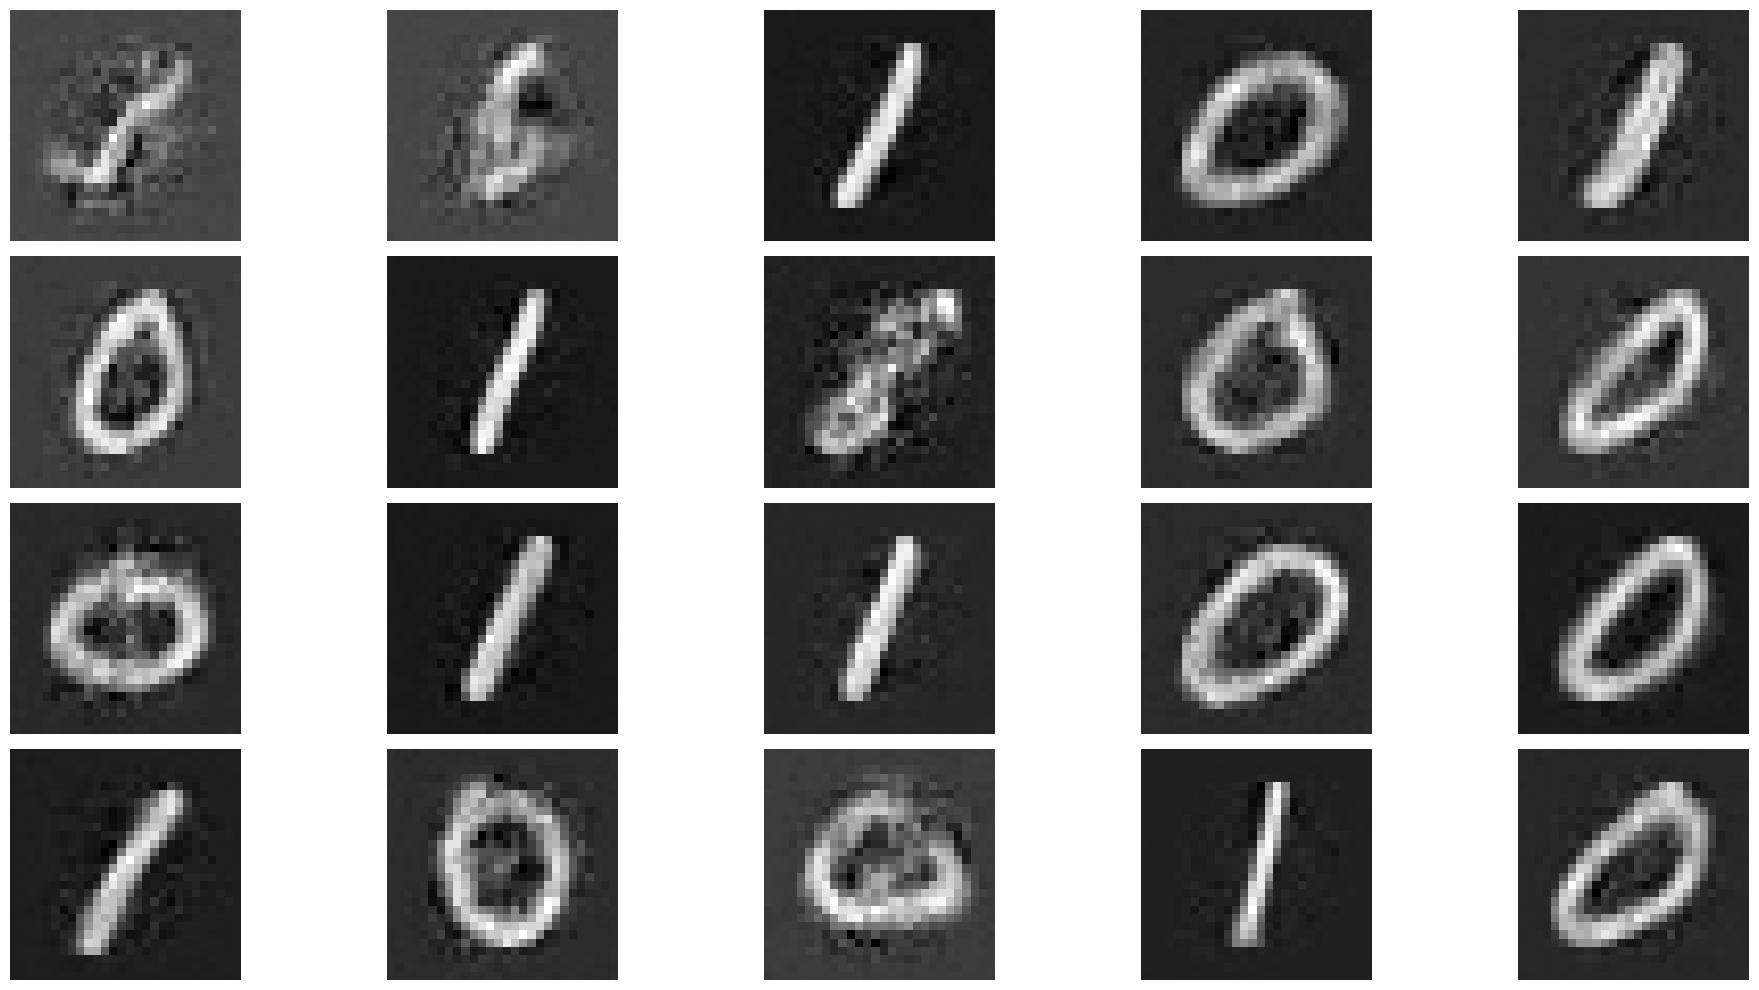

📈 Epoch 45 Summary:
   Train D Loss: 0.1681, Val D Loss: 0.2327
   Train G Loss: 7.3377, Val G Loss: 12.4535

📊 Epoch 46/100
----------------------------------------
Epoch: 46 [0/60000 (0%)]	D_loss: 0.212983	G_loss: 13.810601
Epoch: 46 [6400/60000 (11%)]	D_loss: 0.063512	G_loss: 10.366062
Epoch: 46 [12800/60000 (21%)]	D_loss: 0.152455	G_loss: 6.572109
Epoch: 46 [19200/60000 (32%)]	D_loss: 0.151809	G_loss: 7.176922
Epoch: 46 [25600/60000 (43%)]	D_loss: 0.200691	G_loss: 5.393481
Epoch: 46 [32000/60000 (53%)]	D_loss: 0.364019	G_loss: 6.789853
Epoch: 46 [38400/60000 (64%)]	D_loss: 0.101607	G_loss: 8.642098
Epoch: 46 [44800/60000 (75%)]	D_loss: 0.204958	G_loss: 5.108356
Epoch: 46 [51200/60000 (85%)]	D_loss: 0.354595	G_loss: 11.297195
Epoch: 46 [57600/60000 (96%)]	D_loss: 0.072058	G_loss: 6.239349
====> Epoch: 46 Train D_loss: 0.1604, Train G_loss: 7.5255
====> Epoch: 46 Val D_loss: 0.1049, Val G_loss: 13.5283
📈 Epoch 46 Summary:
   Train D Loss: 0.1604, Val D Loss: 0.1049
   Train G Loss: 7

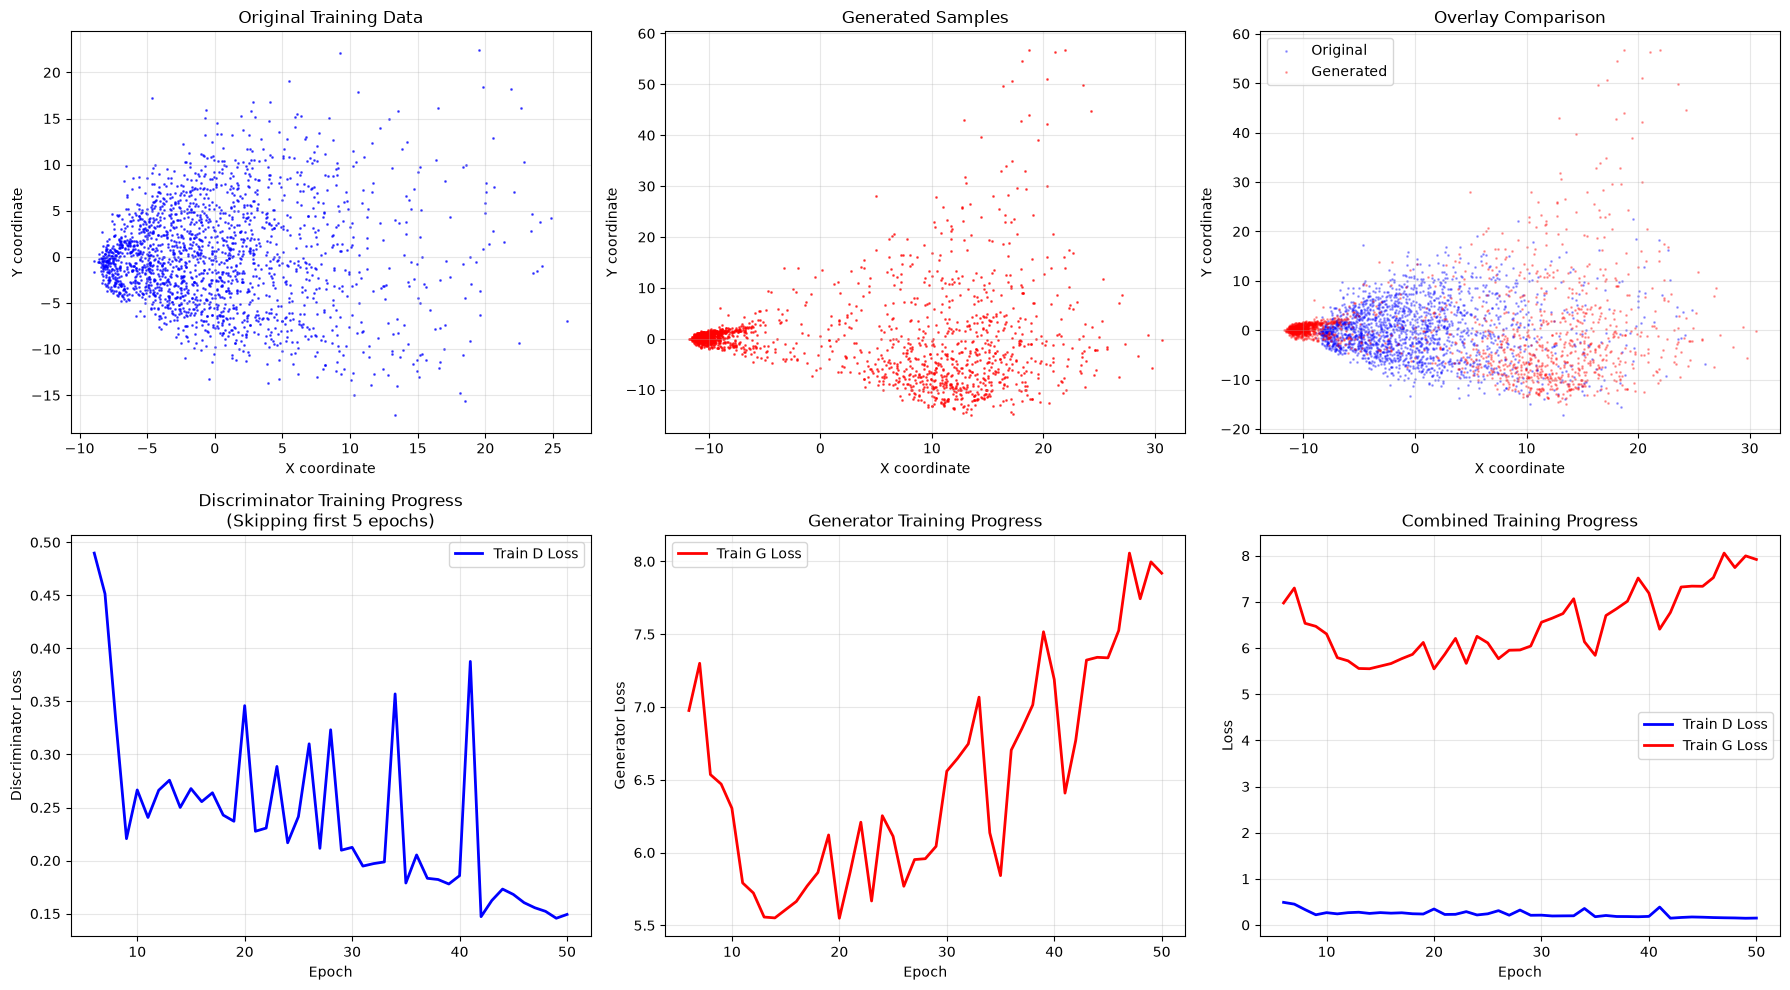

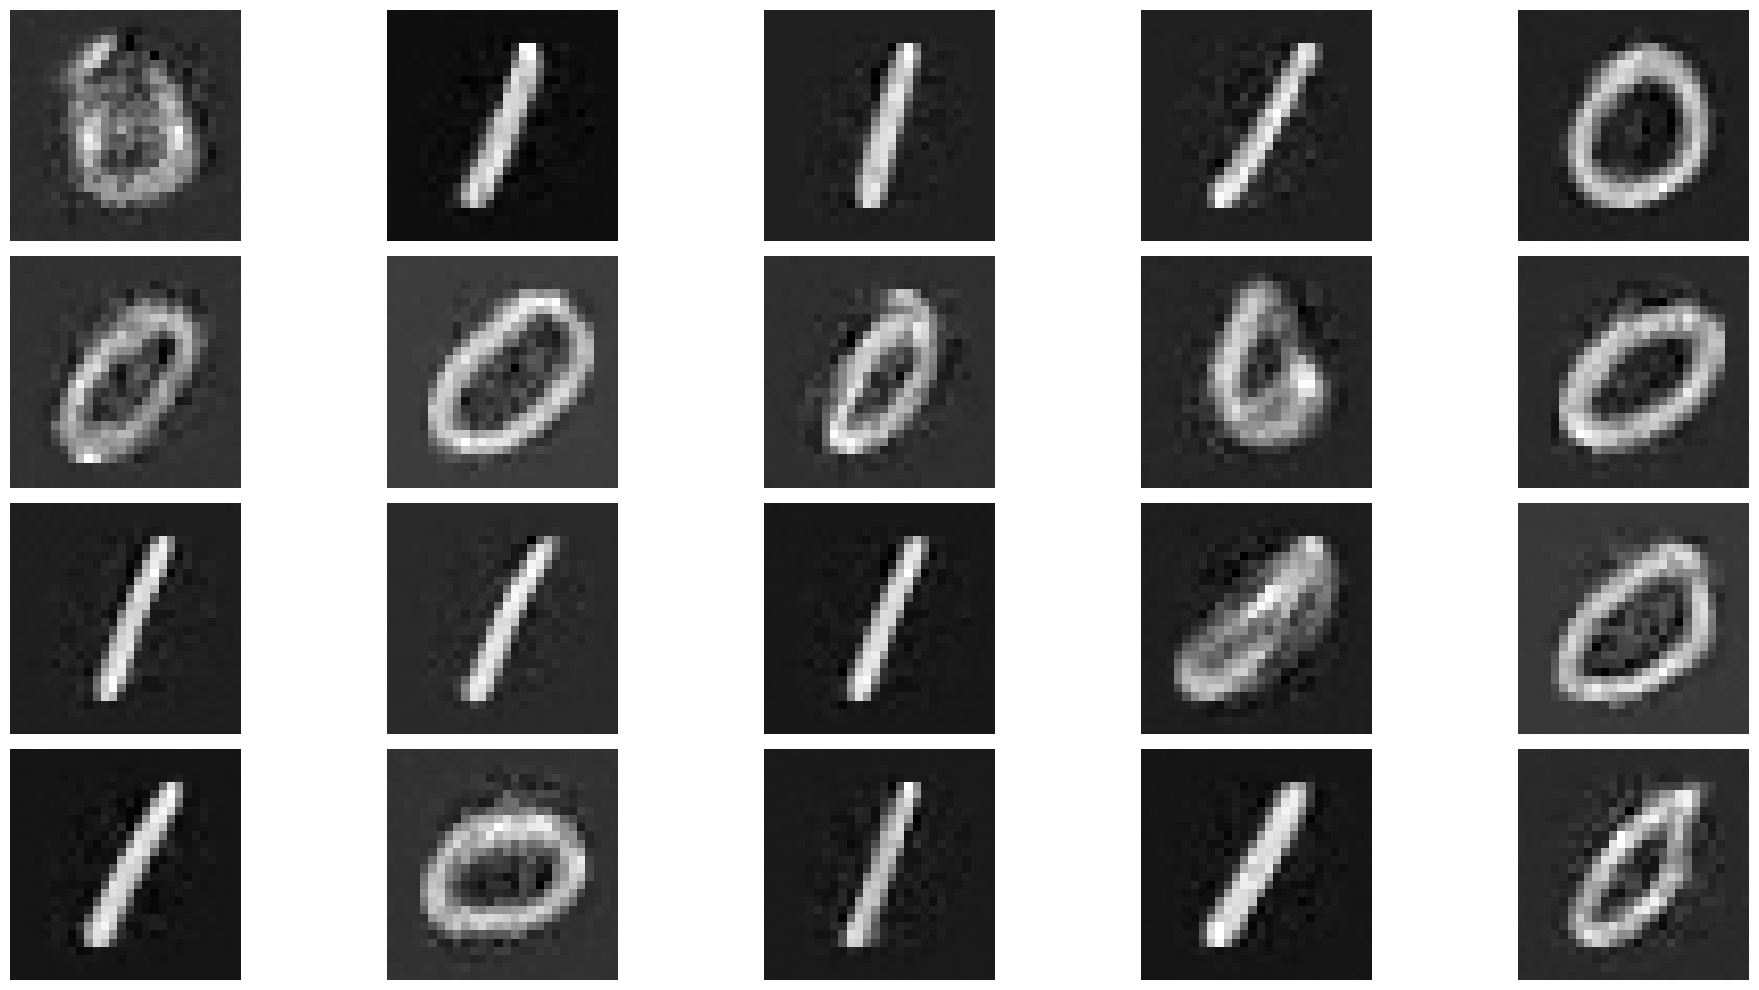

📈 Epoch 50 Summary:
   Train D Loss: 0.1492, Val D Loss: 0.1143
   Train G Loss: 7.9191, Val G Loss: 8.8098

📊 Epoch 51/100
----------------------------------------
Epoch: 51 [0/60000 (0%)]	D_loss: 0.043806	G_loss: 8.721392
Epoch: 51 [6400/60000 (11%)]	D_loss: 0.212319	G_loss: 10.533025
Epoch: 51 [12800/60000 (21%)]	D_loss: 0.087598	G_loss: 7.611114
Epoch: 51 [19200/60000 (32%)]	D_loss: 0.055014	G_loss: 10.368471
Epoch: 51 [25600/60000 (43%)]	D_loss: 0.270330	G_loss: 9.994264
Epoch: 51 [32000/60000 (53%)]	D_loss: 0.047660	G_loss: 9.244541
Epoch: 51 [38400/60000 (64%)]	D_loss: 0.374434	G_loss: 8.607380
Epoch: 51 [44800/60000 (75%)]	D_loss: 0.181801	G_loss: 9.367099
Epoch: 51 [51200/60000 (85%)]	D_loss: 0.105255	G_loss: 8.653435
Epoch: 51 [57600/60000 (96%)]	D_loss: 0.384191	G_loss: 9.505323
====> Epoch: 51 Train D_loss: 0.1358, Train G_loss: 8.3969
====> Epoch: 51 Val D_loss: 0.2614, Val G_loss: 10.6291
📈 Epoch 51 Summary:
   Train D Loss: 0.1358, Val D Loss: 0.2614
   Train G Loss: 8.3

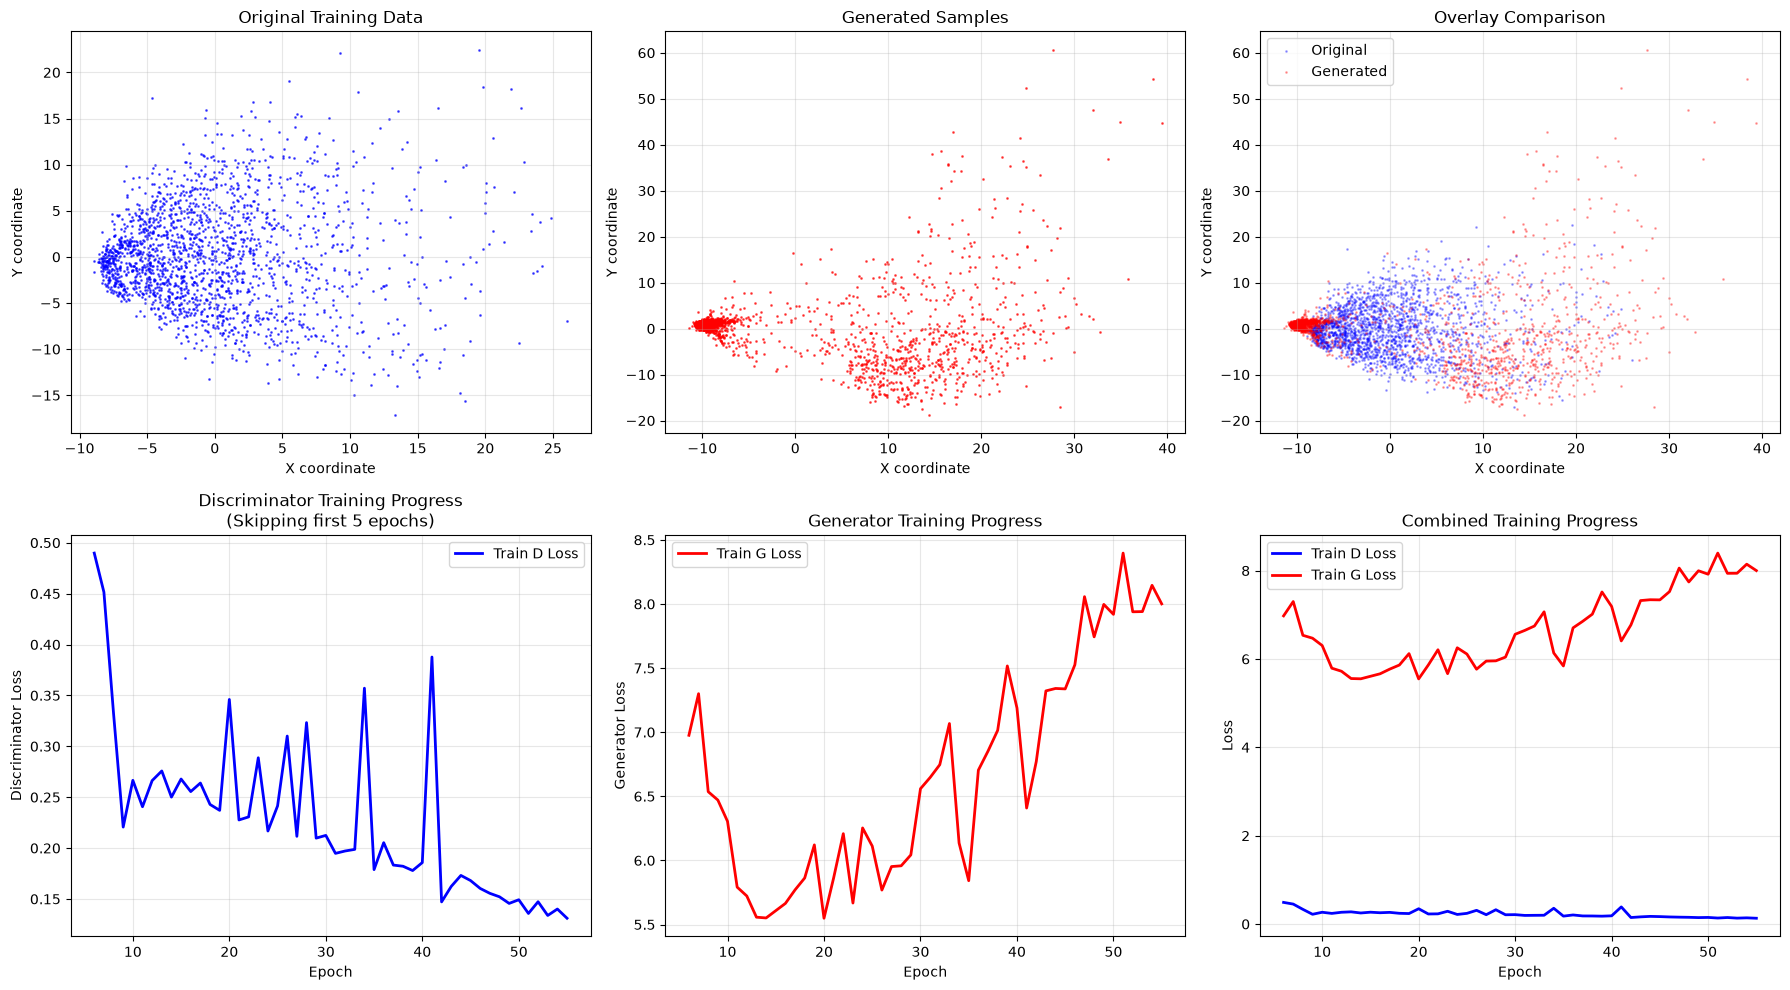

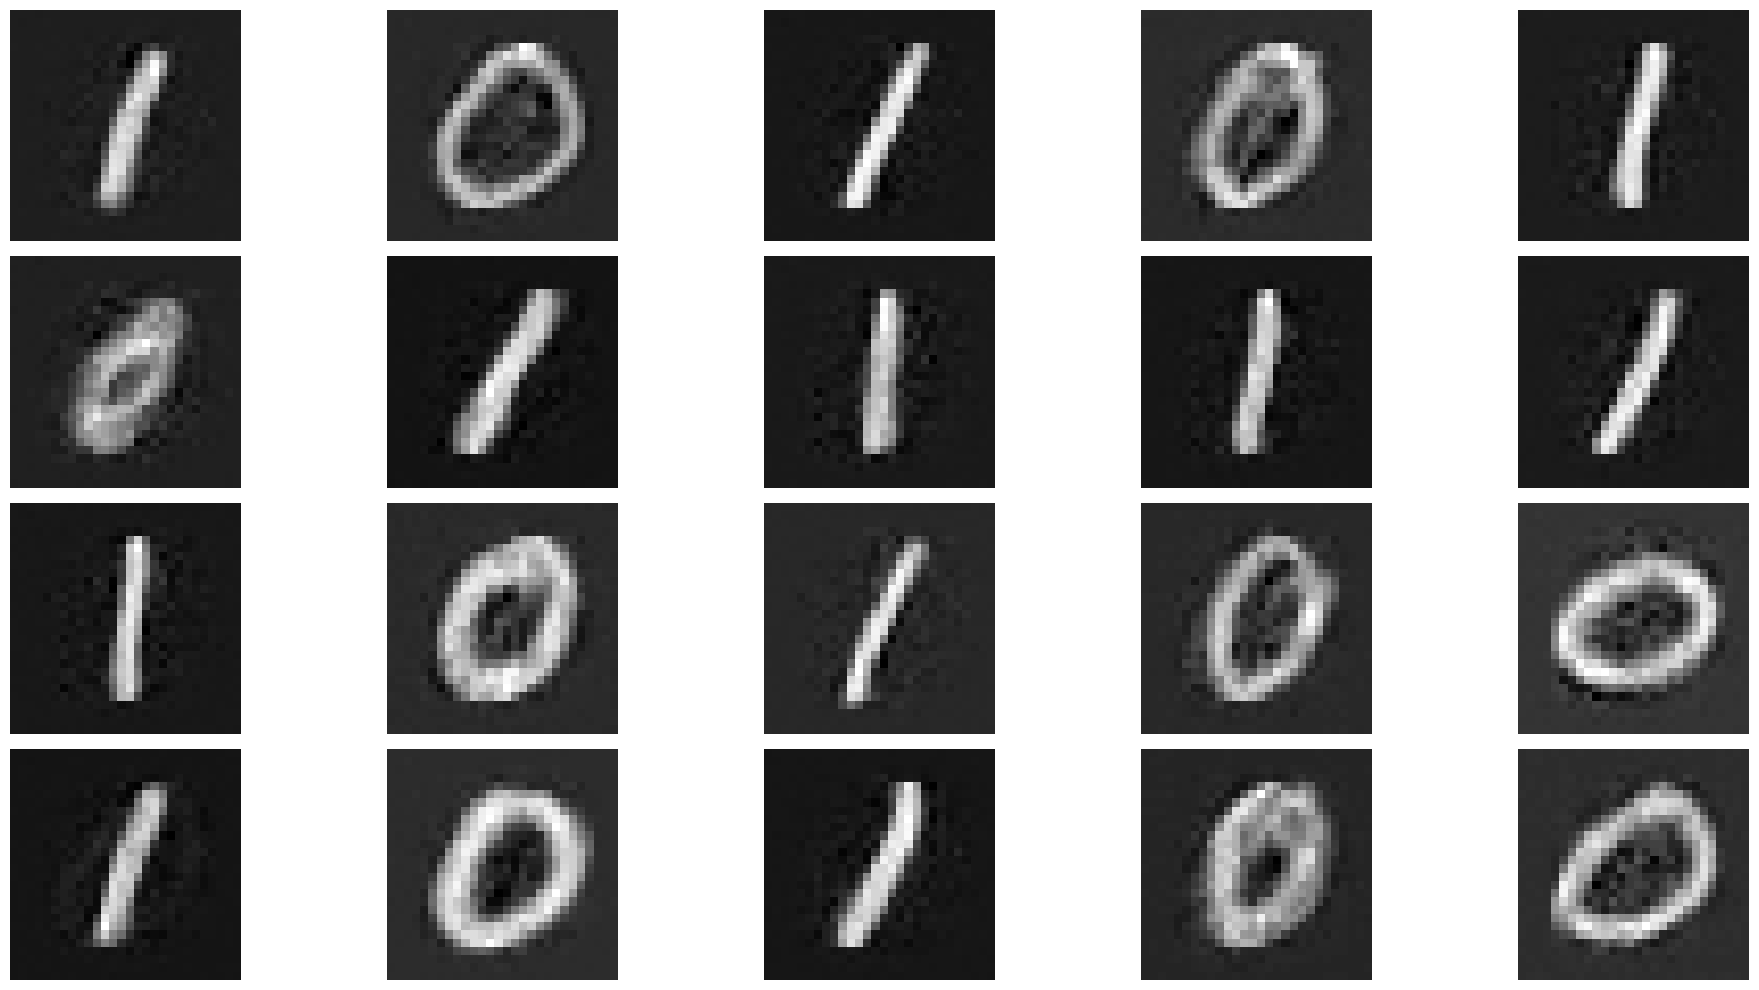

📈 Epoch 55 Summary:
   Train D Loss: 0.1311, Val D Loss: 0.1263
   Train G Loss: 8.0008, Val G Loss: 7.5430

📊 Epoch 56/100
----------------------------------------
Epoch: 56 [0/60000 (0%)]	D_loss: 0.092015	G_loss: 8.218065
Epoch: 56 [6400/60000 (11%)]	D_loss: 0.111911	G_loss: 5.830117
Epoch: 56 [12800/60000 (21%)]	D_loss: 0.088124	G_loss: 7.292870
Epoch: 56 [19200/60000 (32%)]	D_loss: 0.053876	G_loss: 9.899587
Epoch: 56 [25600/60000 (43%)]	D_loss: 0.072741	G_loss: 9.807974
Epoch: 56 [32000/60000 (53%)]	D_loss: 0.130961	G_loss: 5.775871
Epoch: 56 [38400/60000 (64%)]	D_loss: 0.073027	G_loss: 6.641155
Epoch: 56 [44800/60000 (75%)]	D_loss: 0.121376	G_loss: 6.819119
Epoch: 56 [51200/60000 (85%)]	D_loss: 0.201127	G_loss: 7.786694
Epoch: 56 [57600/60000 (96%)]	D_loss: 0.082303	G_loss: 8.444948
====> Epoch: 56 Train D_loss: 0.1284, Train G_loss: 8.3638
====> Epoch: 56 Val D_loss: 0.1651, Val G_loss: 6.8254
📈 Epoch 56 Summary:
   Train D Loss: 0.1284, Val D Loss: 0.1651
   Train G Loss: 8.3638

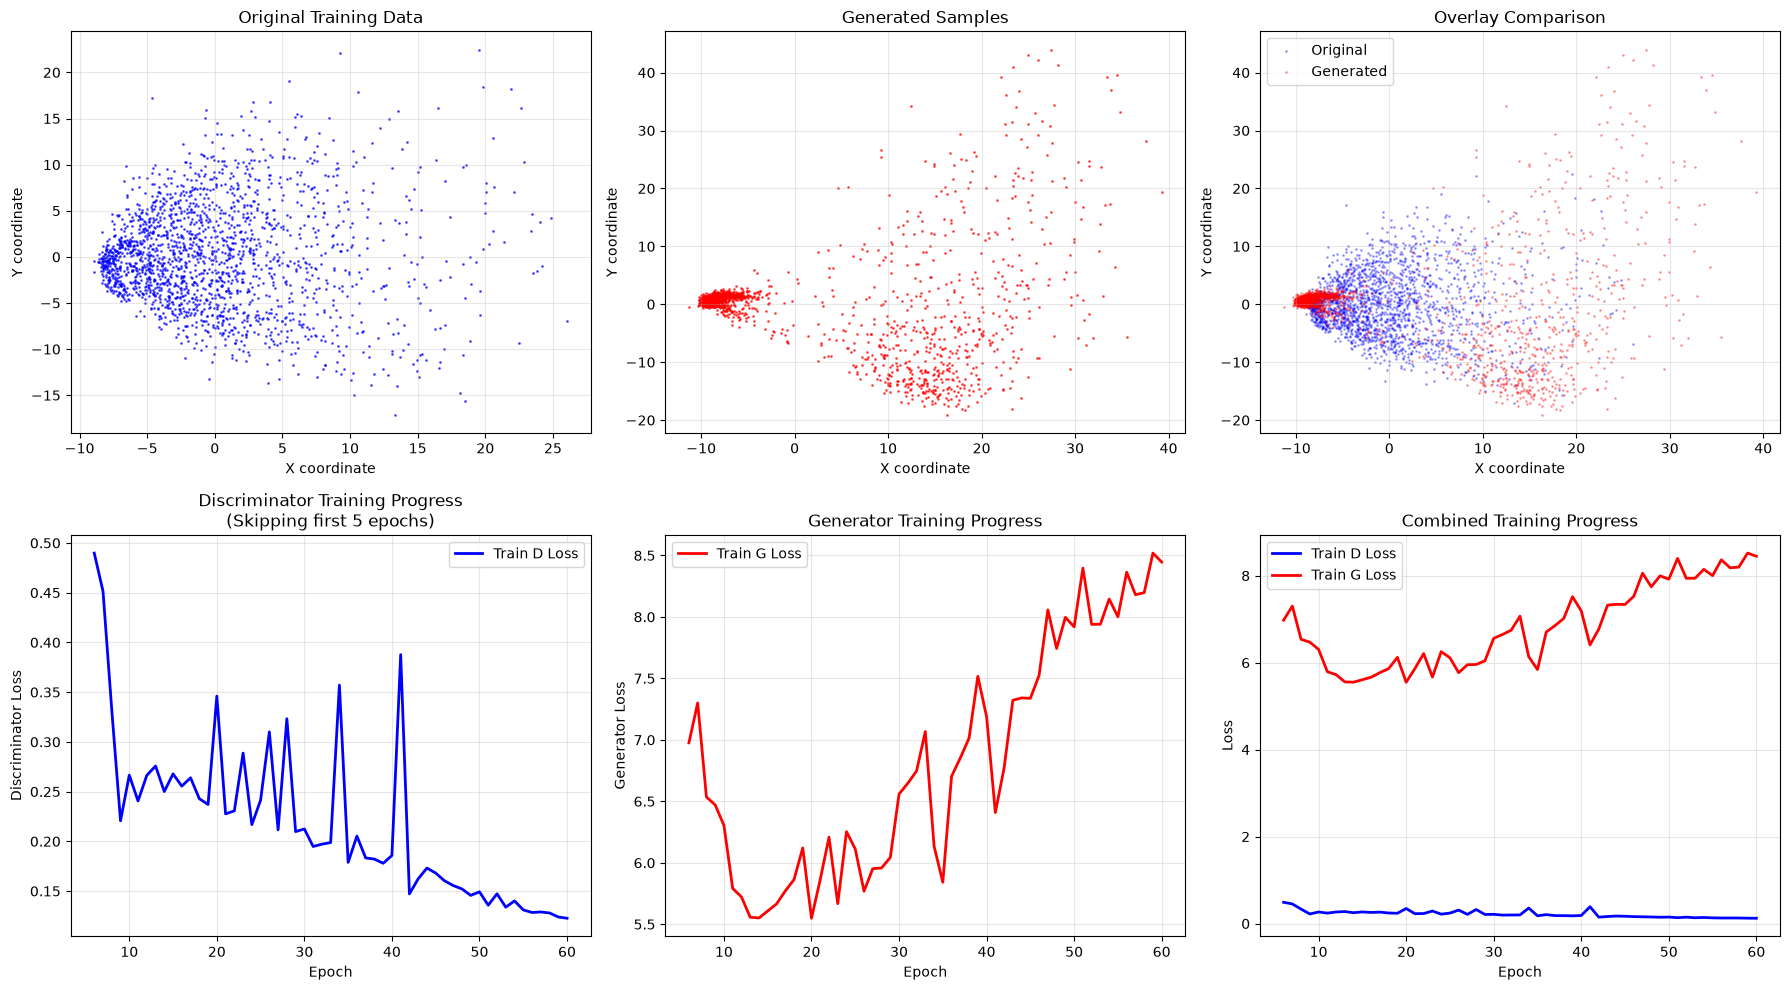

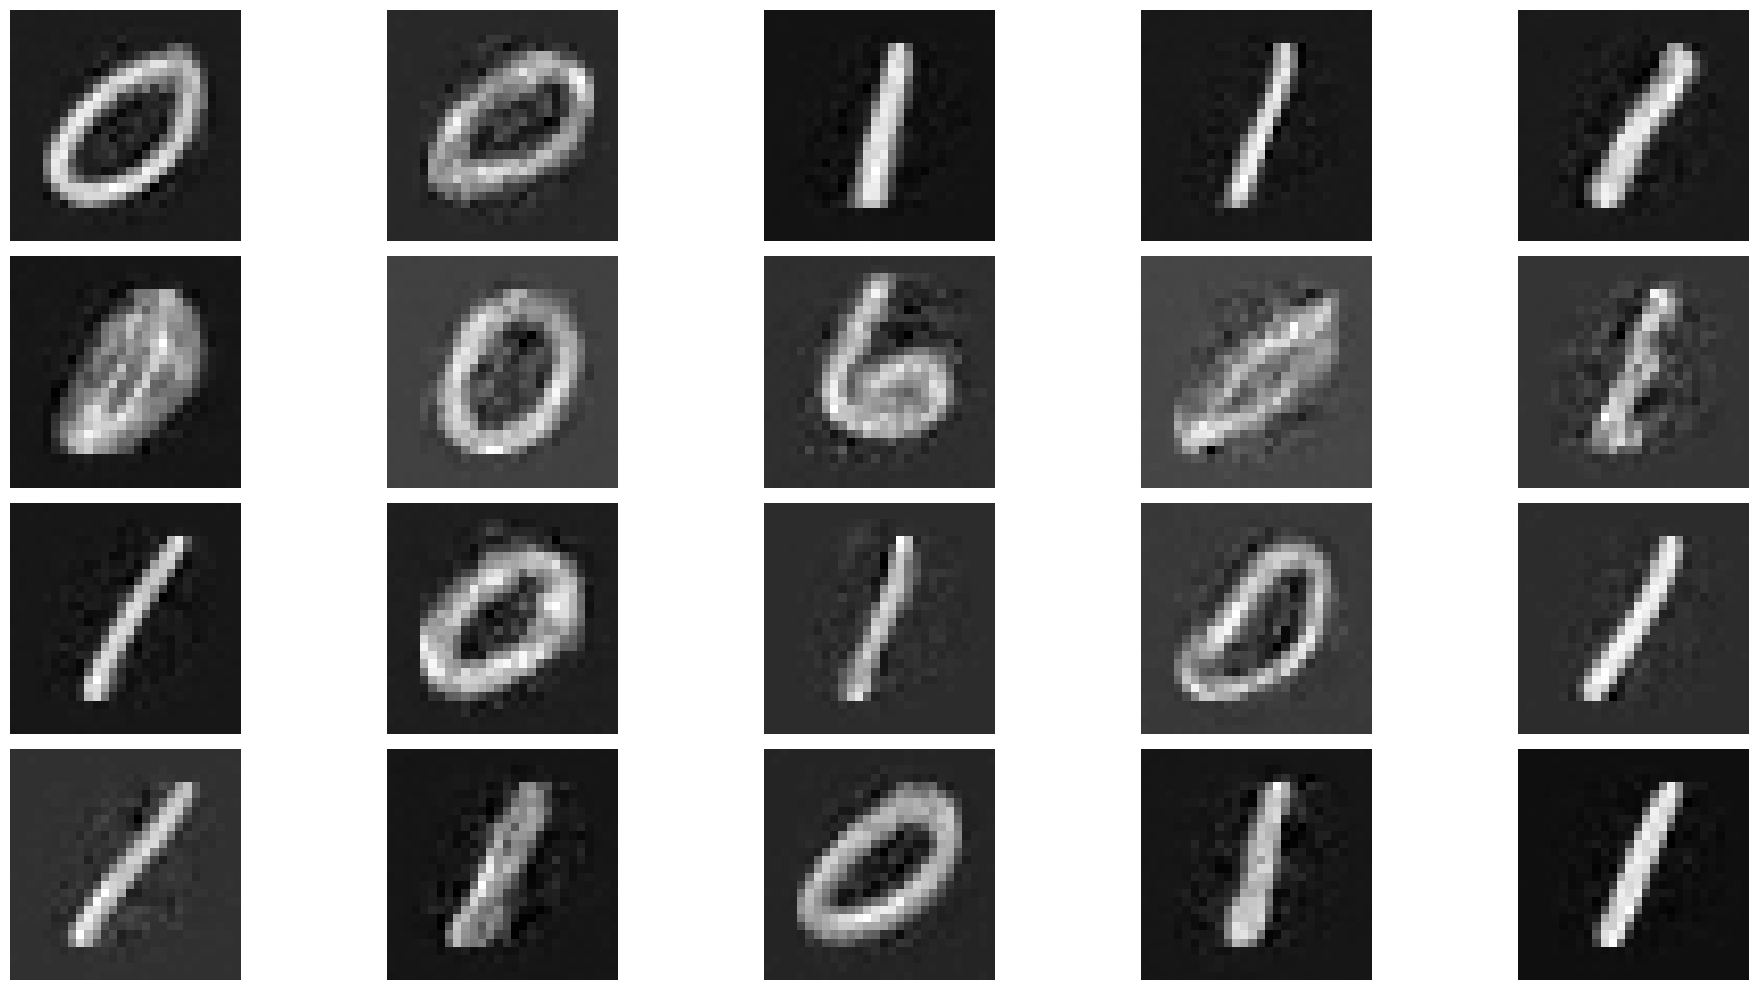

📈 Epoch 60 Summary:
   Train D Loss: 0.1227, Val D Loss: 0.0693
   Train G Loss: 8.4463, Val G Loss: 9.7847

📊 Epoch 61/100
----------------------------------------
Epoch: 61 [0/60000 (0%)]	D_loss: 0.021376	G_loss: 9.730434
Epoch: 61 [6400/60000 (11%)]	D_loss: 0.069012	G_loss: 10.088133
Epoch: 61 [12800/60000 (21%)]	D_loss: 0.238020	G_loss: 12.812387
Epoch: 61 [19200/60000 (32%)]	D_loss: 0.182940	G_loss: 7.480670
Epoch: 61 [25600/60000 (43%)]	D_loss: 0.040283	G_loss: 11.207685
Epoch: 61 [32000/60000 (53%)]	D_loss: 0.073444	G_loss: 9.492690
Epoch: 61 [38400/60000 (64%)]	D_loss: 0.112278	G_loss: 6.097143
Epoch: 61 [44800/60000 (75%)]	D_loss: 0.029531	G_loss: 10.062326
Epoch: 61 [51200/60000 (85%)]	D_loss: 0.148332	G_loss: 11.124926
Epoch: 61 [57600/60000 (96%)]	D_loss: 0.064552	G_loss: 11.460121
====> Epoch: 61 Train D_loss: 0.1043, Train G_loss: 8.9244
====> Epoch: 61 Val D_loss: 0.1628, Val G_loss: 9.8962
📈 Epoch 61 Summary:
   Train D Loss: 0.1043, Val D Loss: 0.1628
   Train G Loss: 

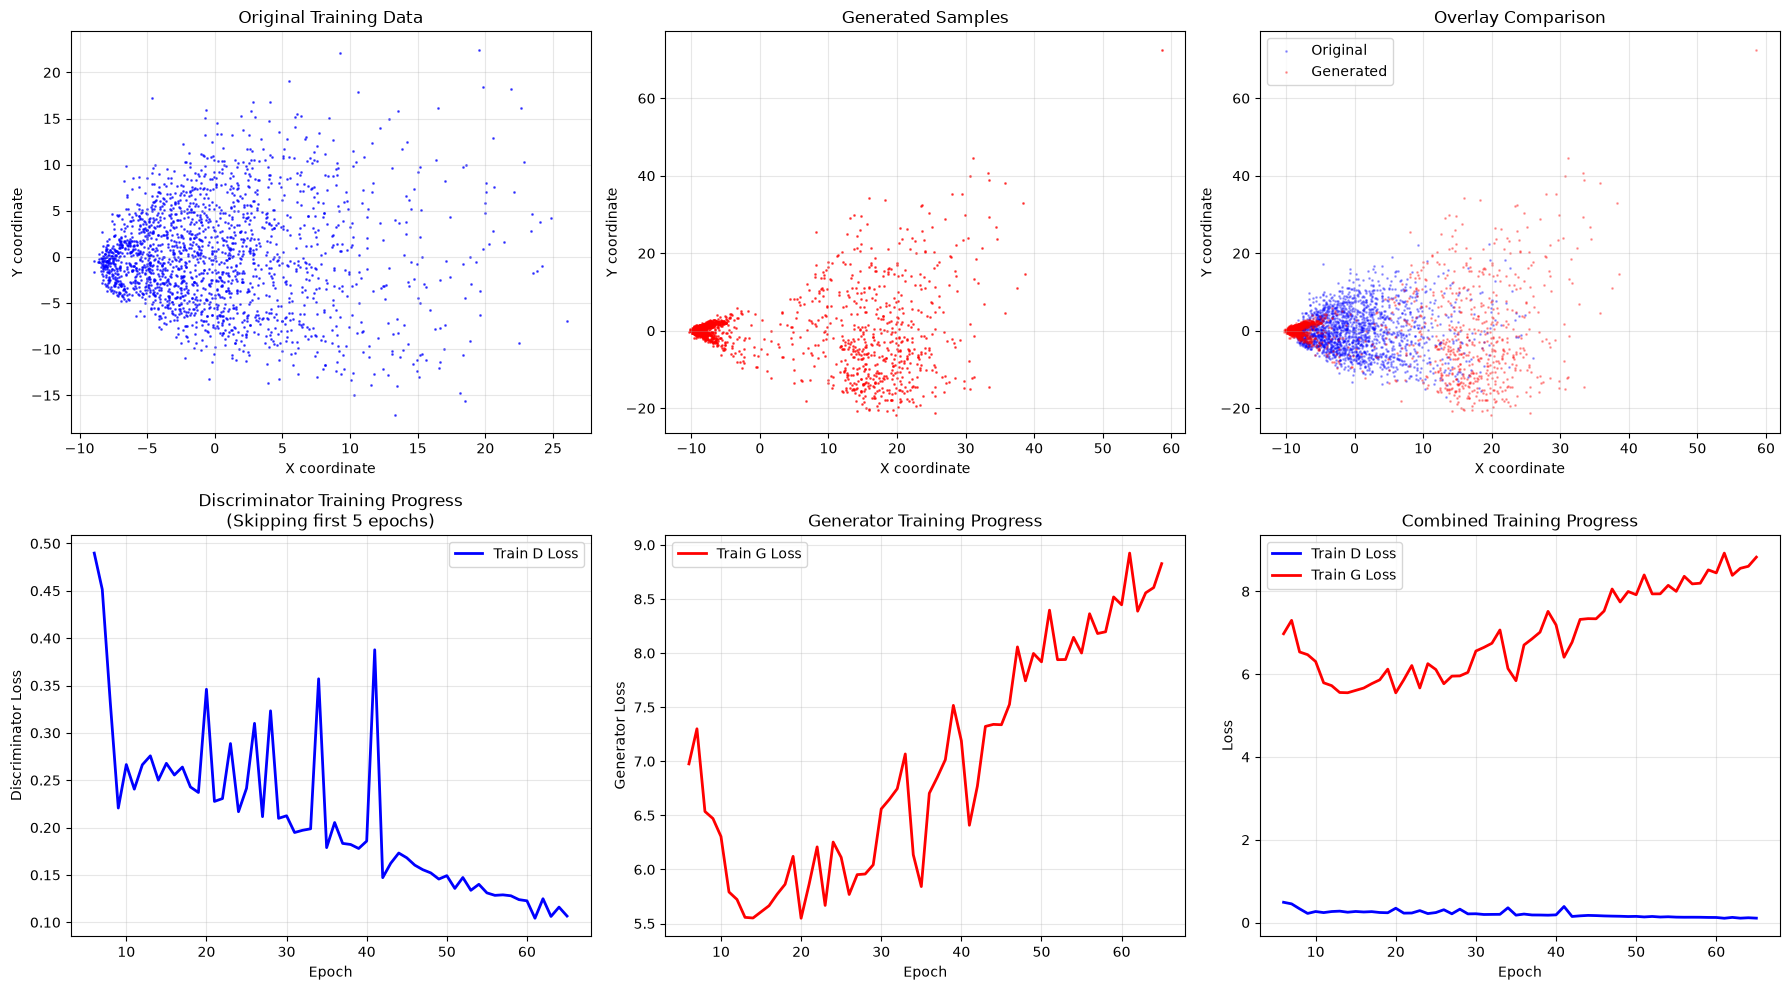

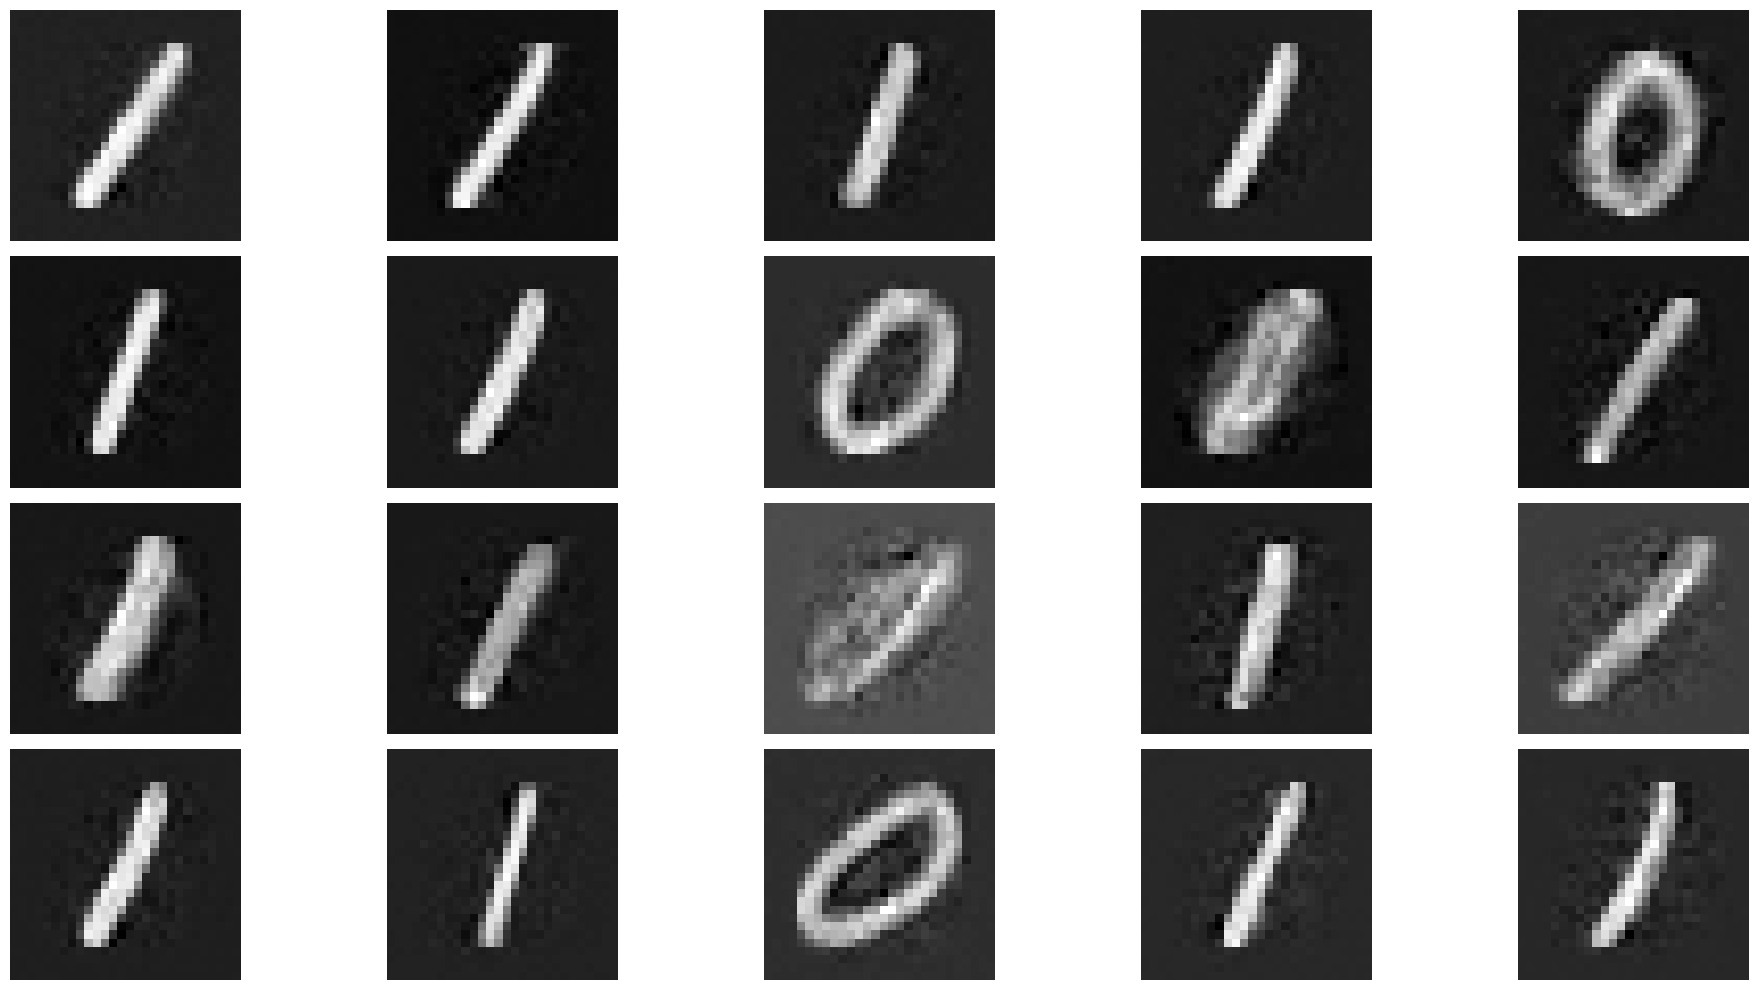

📈 Epoch 65 Summary:
   Train D Loss: 0.1066, Val D Loss: 0.1394
   Train G Loss: 8.8270, Val G Loss: 6.6836

📊 Epoch 66/100
----------------------------------------
Epoch: 66 [0/60000 (0%)]	D_loss: 0.082176	G_loss: 6.965343
Epoch: 66 [6400/60000 (11%)]	D_loss: 0.126908	G_loss: 9.306838
Epoch: 66 [12800/60000 (21%)]	D_loss: 0.049013	G_loss: 7.341331
Epoch: 66 [19200/60000 (32%)]	D_loss: 0.122600	G_loss: 8.817755
Epoch: 66 [25600/60000 (43%)]	D_loss: 0.056561	G_loss: 9.435101
Epoch: 66 [32000/60000 (53%)]	D_loss: 0.054529	G_loss: 6.367559
Epoch: 66 [38400/60000 (64%)]	D_loss: 0.105840	G_loss: 17.000999
Epoch: 66 [44800/60000 (75%)]	D_loss: 0.226957	G_loss: 8.377262
Epoch: 66 [51200/60000 (85%)]	D_loss: 0.060408	G_loss: 6.199035
Epoch: 66 [57600/60000 (96%)]	D_loss: 0.032138	G_loss: 15.039804
====> Epoch: 66 Train D_loss: 0.0994, Train G_loss: 8.9855
====> Epoch: 66 Val D_loss: 0.2036, Val G_loss: 7.3097
📈 Epoch 66 Summary:
   Train D Loss: 0.0994, Val D Loss: 0.2036
   Train G Loss: 8.98

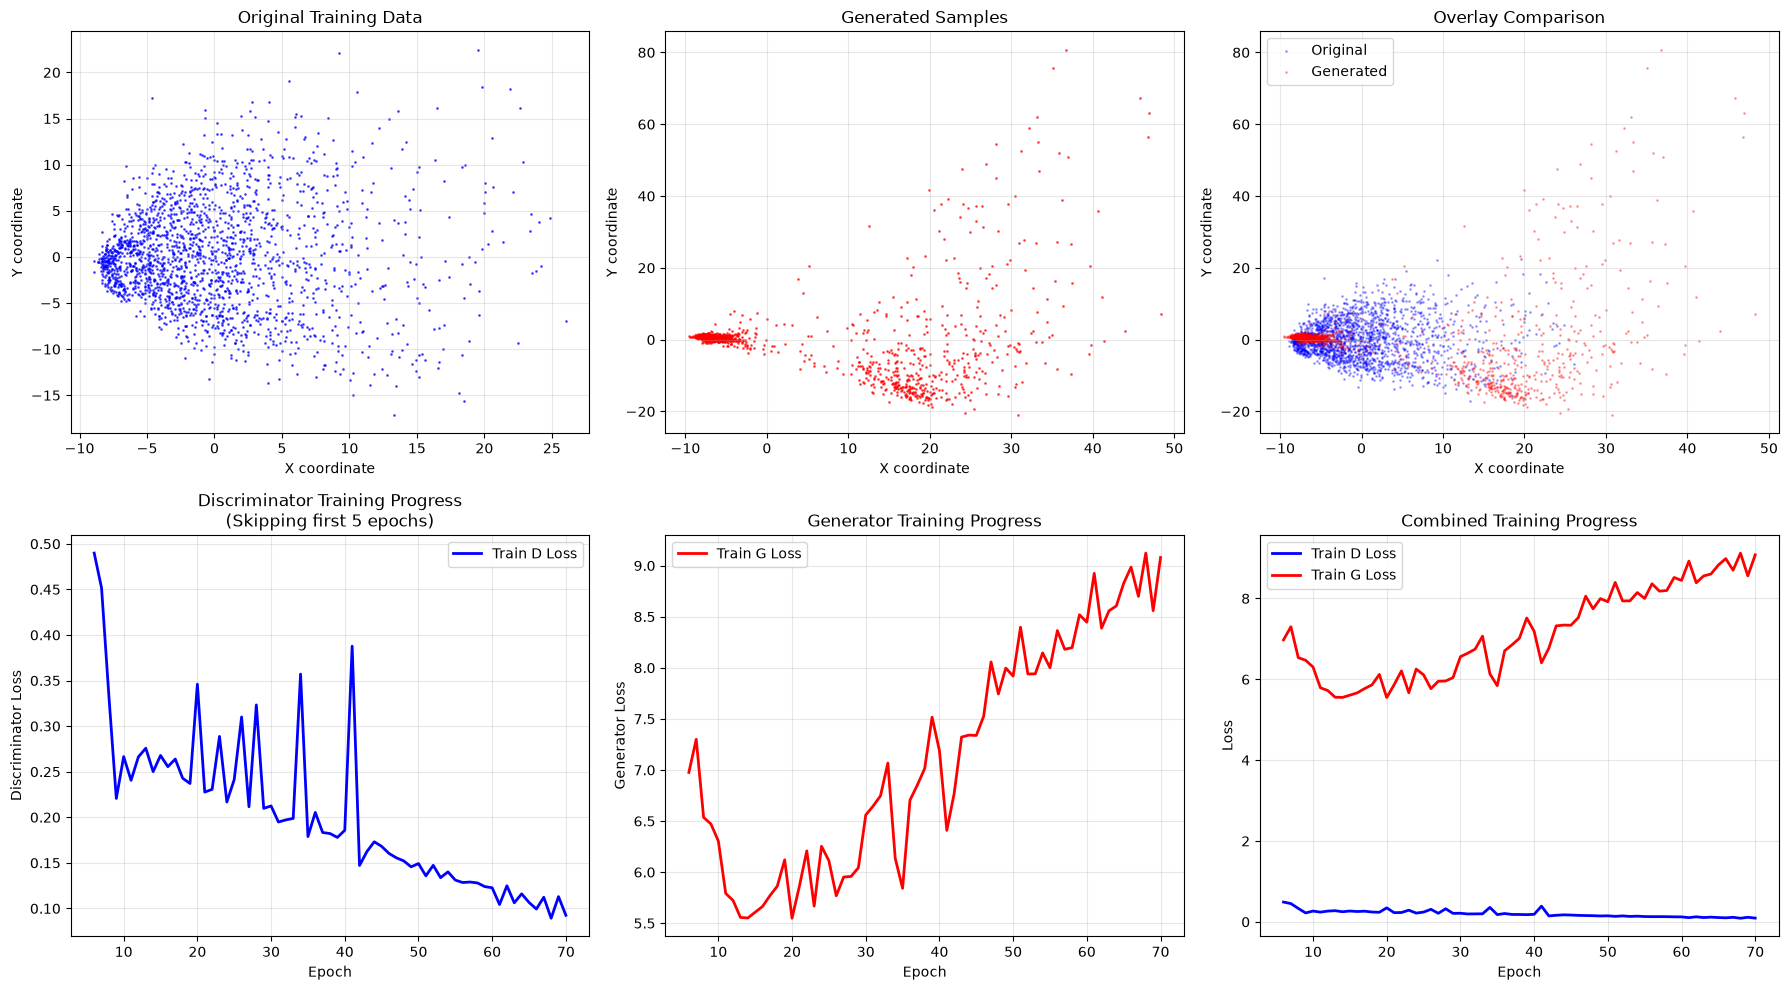

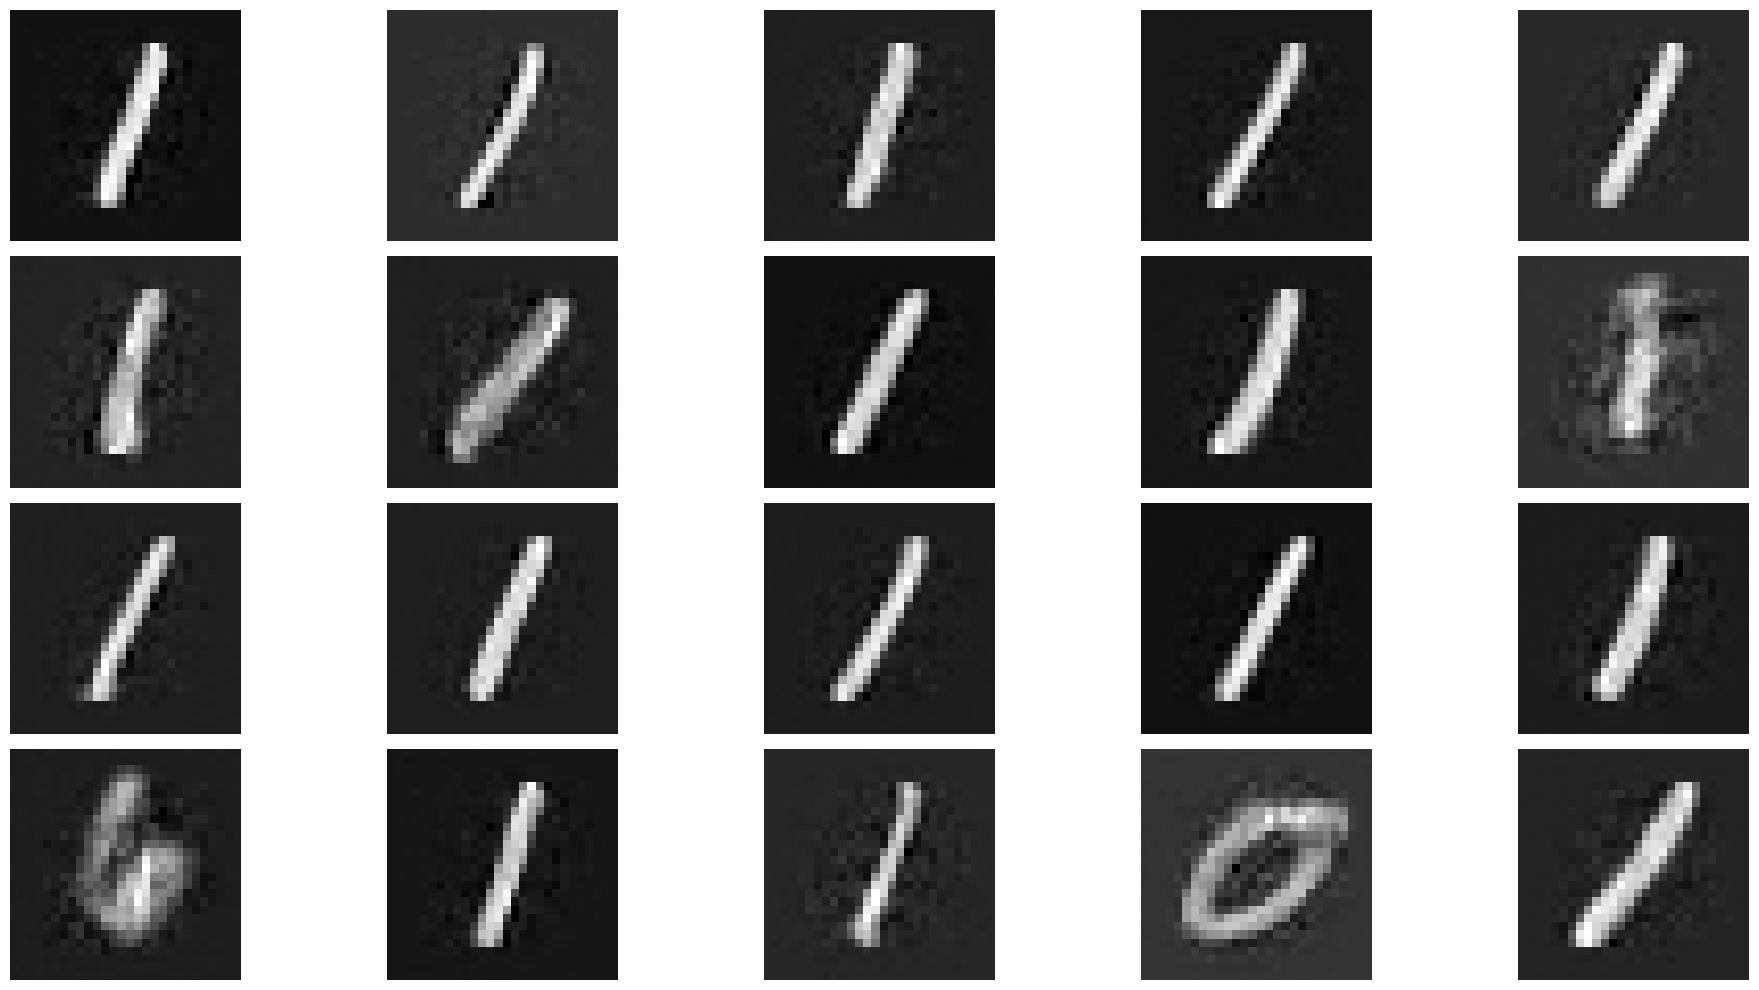

📈 Epoch 70 Summary:
   Train D Loss: 0.0925, Val D Loss: 0.1360
   Train G Loss: 9.0792, Val G Loss: 7.3657

📊 Epoch 71/100
----------------------------------------
Epoch: 71 [0/60000 (0%)]	D_loss: 0.154940	G_loss: 8.553070
Epoch: 71 [6400/60000 (11%)]	D_loss: 0.141555	G_loss: 9.891680
Epoch: 71 [12800/60000 (21%)]	D_loss: 0.047600	G_loss: 13.127953
Epoch: 71 [19200/60000 (32%)]	D_loss: 0.109495	G_loss: 18.019253
Epoch: 71 [25600/60000 (43%)]	D_loss: 0.098484	G_loss: 10.076090
Epoch: 71 [32000/60000 (53%)]	D_loss: 0.179372	G_loss: 10.034038
Epoch: 71 [38400/60000 (64%)]	D_loss: 0.117860	G_loss: 6.699347
Epoch: 71 [44800/60000 (75%)]	D_loss: 0.045918	G_loss: 11.024101
Epoch: 71 [51200/60000 (85%)]	D_loss: 0.025584	G_loss: 11.125631
Epoch: 71 [57600/60000 (96%)]	D_loss: 0.027165	G_loss: 9.950646
====> Epoch: 71 Train D_loss: 0.0994, Train G_loss: 8.9775
====> Epoch: 71 Val D_loss: 0.0957, Val G_loss: 9.2574
📈 Epoch 71 Summary:
   Train D Loss: 0.0994, Val D Loss: 0.0957
   Train G Loss: 

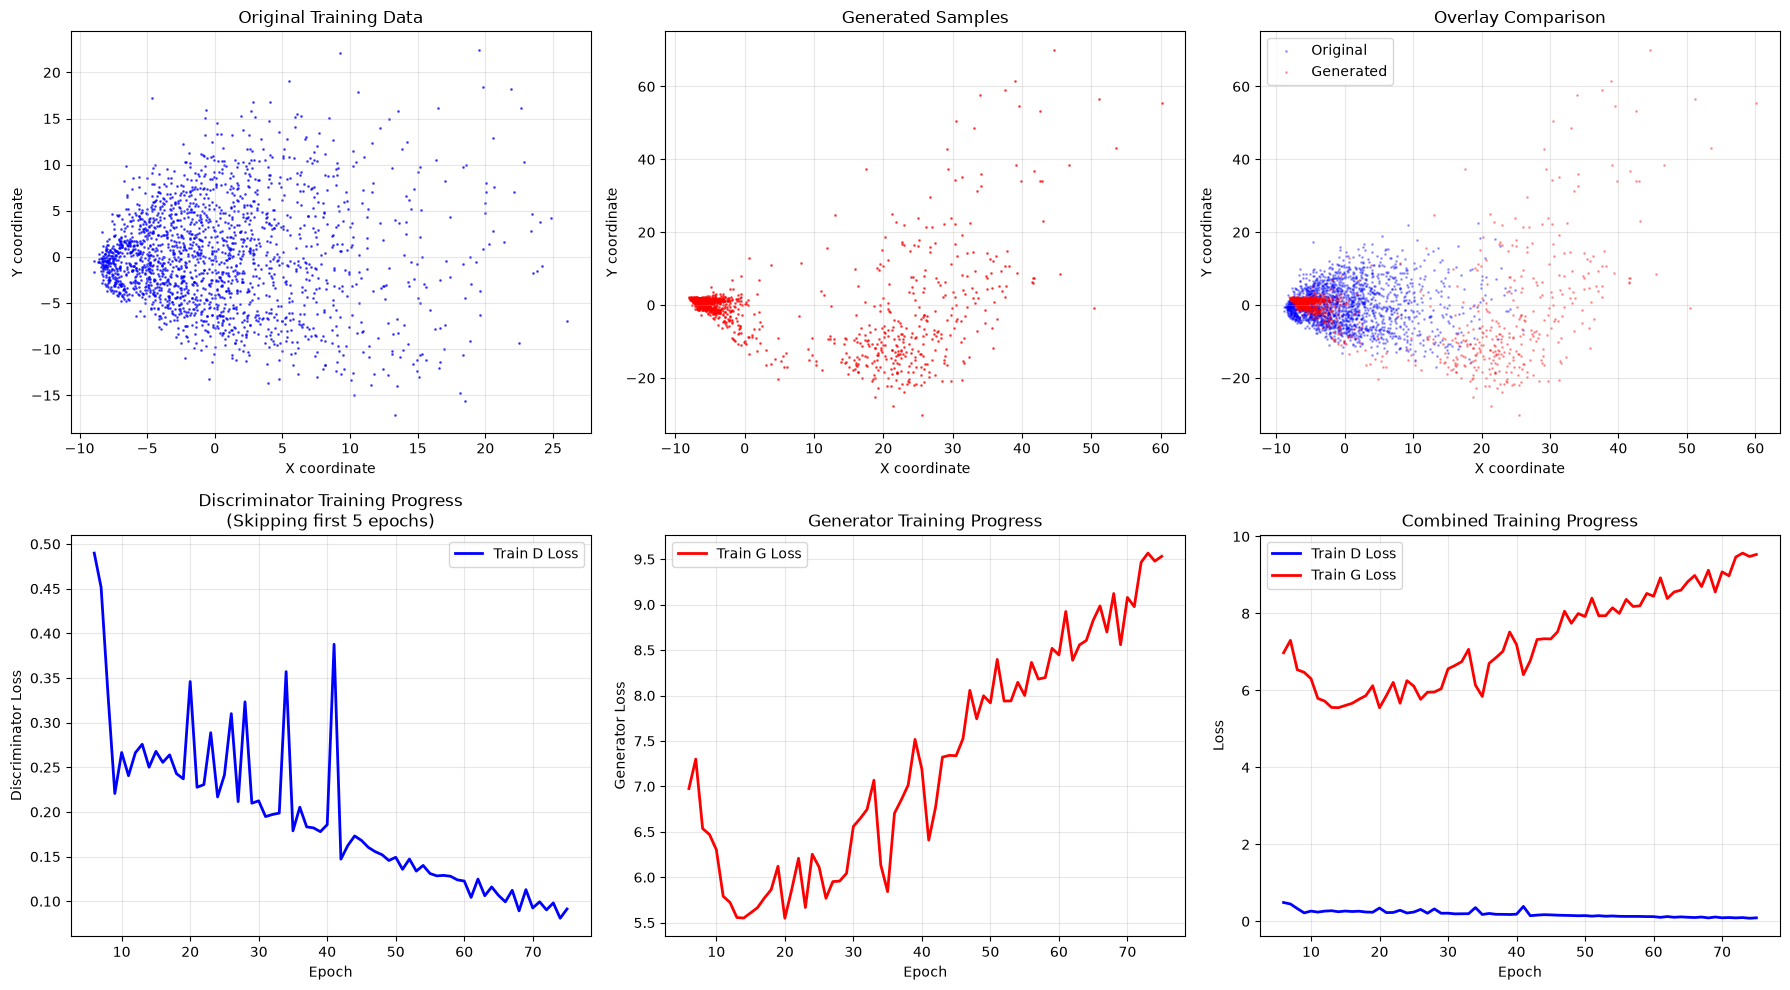

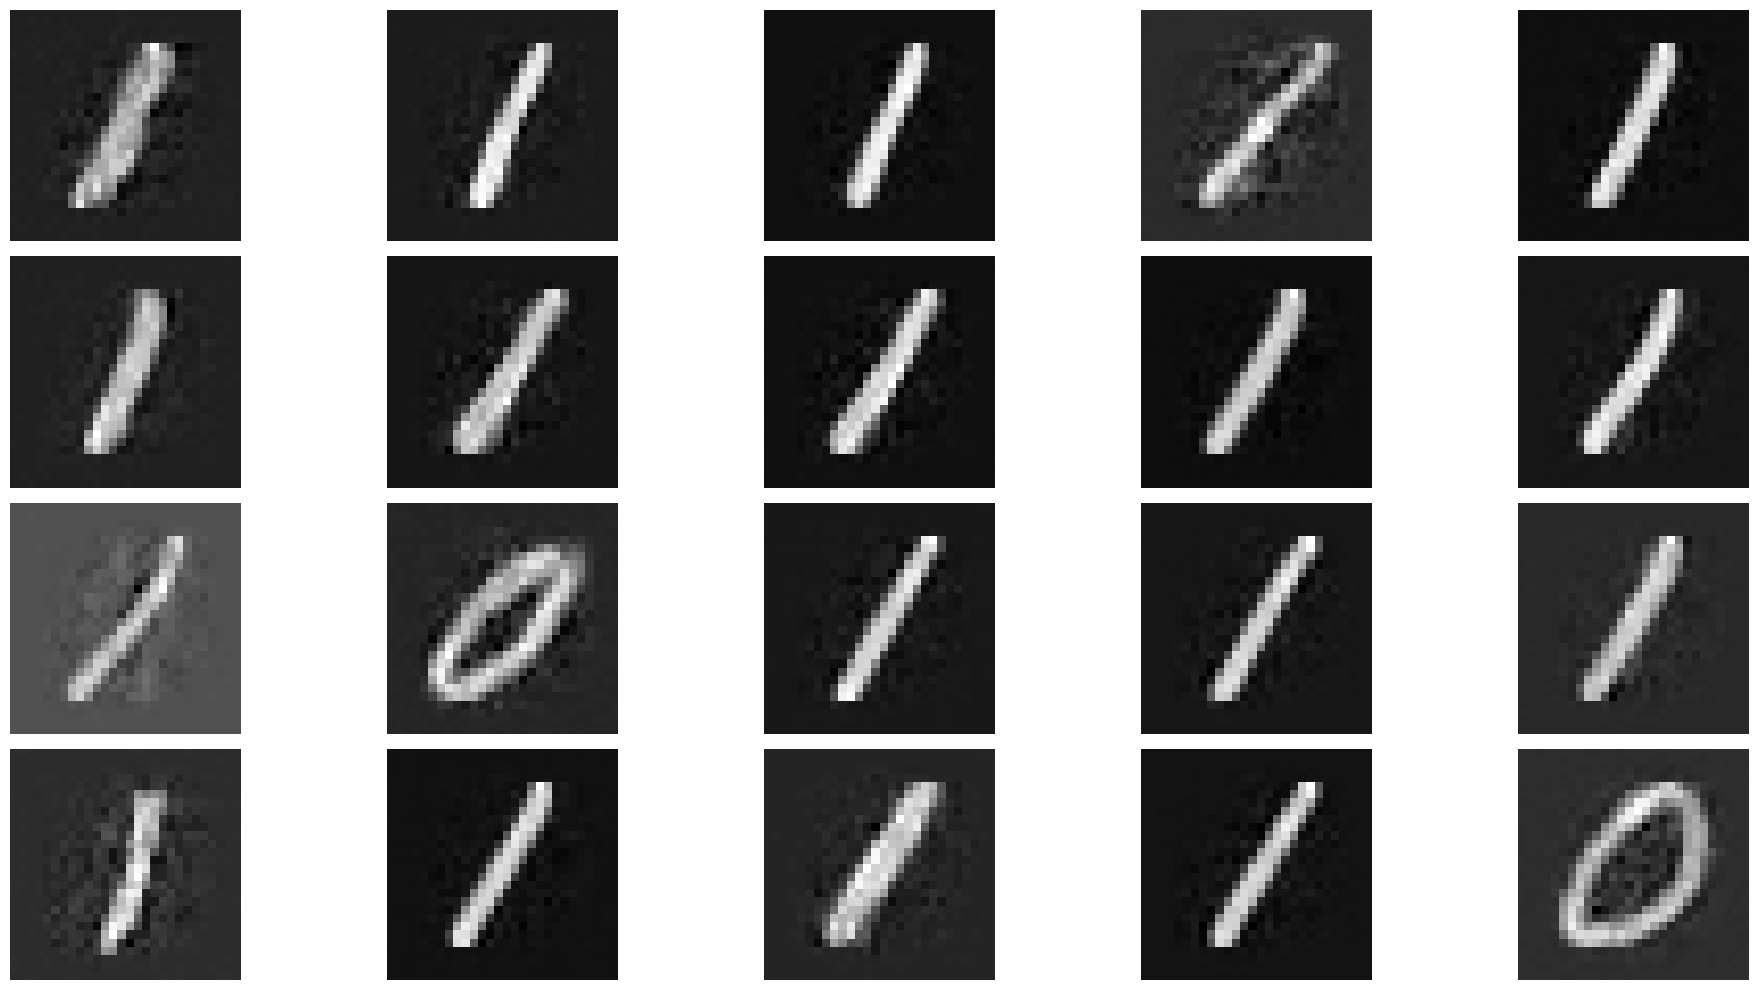

📈 Epoch 75 Summary:
   Train D Loss: 0.0914, Val D Loss: 0.1119
   Train G Loss: 9.5317, Val G Loss: 6.0818

📊 Epoch 76/100
----------------------------------------
Epoch: 76 [0/60000 (0%)]	D_loss: 0.060874	G_loss: 6.750175
Epoch: 76 [6400/60000 (11%)]	D_loss: 0.065796	G_loss: 9.322443
Epoch: 76 [12800/60000 (21%)]	D_loss: 0.016443	G_loss: 9.147388
Epoch: 76 [19200/60000 (32%)]	D_loss: 0.038492	G_loss: 7.884702
Epoch: 76 [25600/60000 (43%)]	D_loss: 0.083992	G_loss: 9.210864
Epoch: 76 [32000/60000 (53%)]	D_loss: 0.042289	G_loss: 11.010979
Epoch: 76 [38400/60000 (64%)]	D_loss: 0.027374	G_loss: 11.702591
Epoch: 76 [44800/60000 (75%)]	D_loss: 0.040111	G_loss: 12.500227
Epoch: 76 [51200/60000 (85%)]	D_loss: 0.061998	G_loss: 13.117674
Epoch: 76 [57600/60000 (96%)]	D_loss: 0.004392	G_loss: 15.639985
====> Epoch: 76 Train D_loss: 0.0870, Train G_loss: 9.6569
====> Epoch: 76 Val D_loss: 0.1760, Val G_loss: 7.9497
📈 Epoch 76 Summary:
   Train D Loss: 0.0870, Val D Loss: 0.1760
   Train G Loss: 9

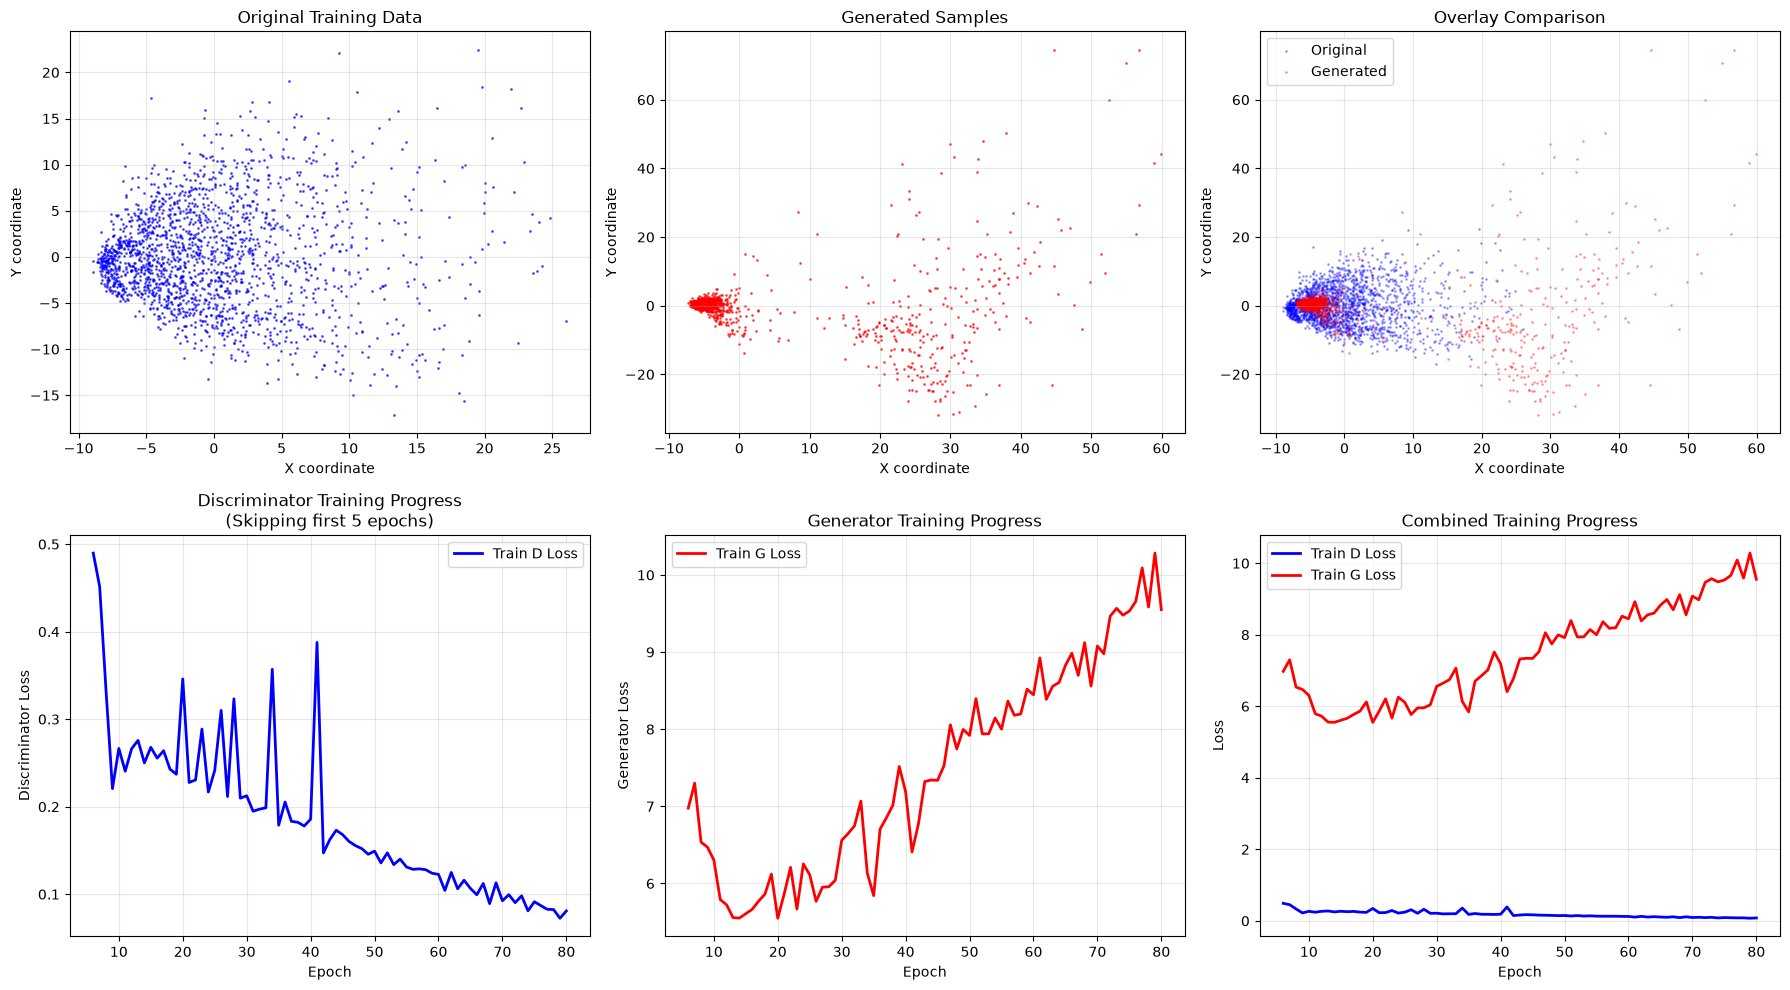

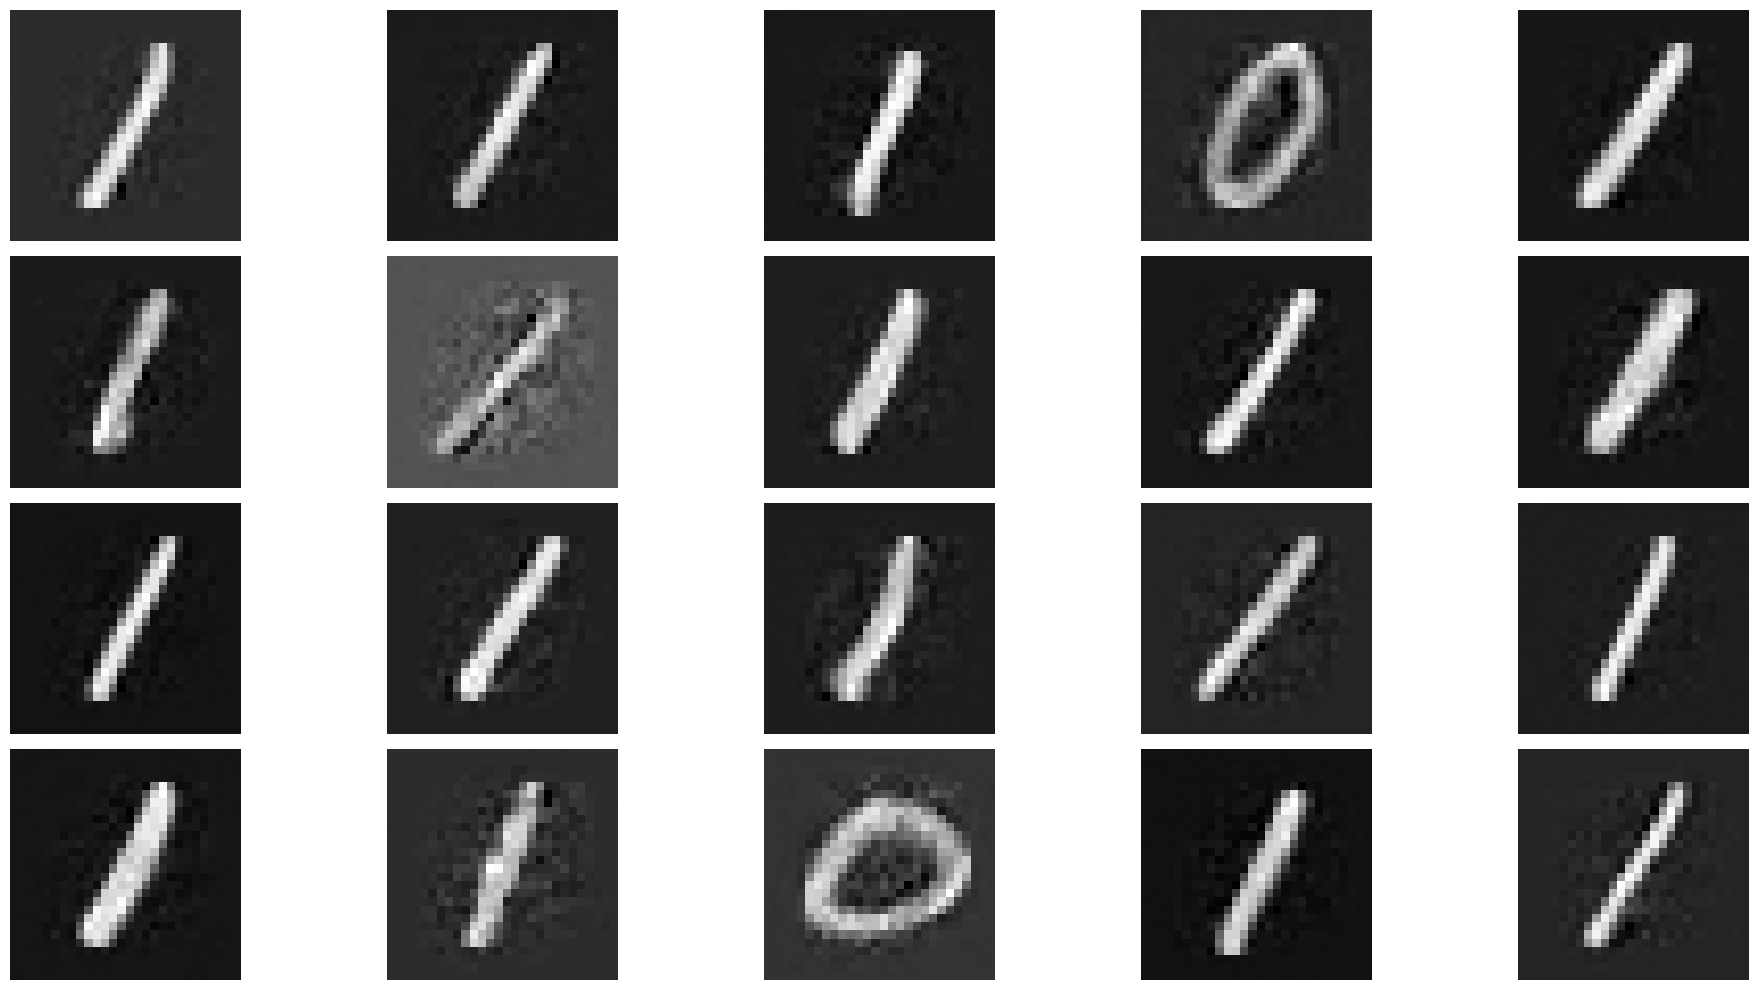

📈 Epoch 80 Summary:
   Train D Loss: 0.0808, Val D Loss: 0.1060
   Train G Loss: 9.5515, Val G Loss: 9.3474

📊 Epoch 81/100
----------------------------------------
Epoch: 81 [0/60000 (0%)]	D_loss: 0.063310	G_loss: 9.744905
Epoch: 81 [6400/60000 (11%)]	D_loss: 0.082298	G_loss: 6.352903
Epoch: 81 [12800/60000 (21%)]	D_loss: 0.127978	G_loss: 6.848639
Epoch: 81 [19200/60000 (32%)]	D_loss: 0.030377	G_loss: 14.154196
Epoch: 81 [25600/60000 (43%)]	D_loss: 0.127185	G_loss: 13.896095
Epoch: 81 [32000/60000 (53%)]	D_loss: 0.043041	G_loss: 7.043593
Epoch: 81 [38400/60000 (64%)]	D_loss: 0.057925	G_loss: 9.098536
Epoch: 81 [44800/60000 (75%)]	D_loss: 0.097380	G_loss: 7.139940
Epoch: 81 [51200/60000 (85%)]	D_loss: 0.190714	G_loss: 8.181700
Epoch: 81 [57600/60000 (96%)]	D_loss: 0.068520	G_loss: 12.518383
====> Epoch: 81 Train D_loss: 0.0818, Train G_loss: 10.1641
====> Epoch: 81 Val D_loss: 0.1488, Val G_loss: 5.3601
📈 Epoch 81 Summary:
   Train D Loss: 0.0818, Val D Loss: 0.1488
   Train G Loss: 10

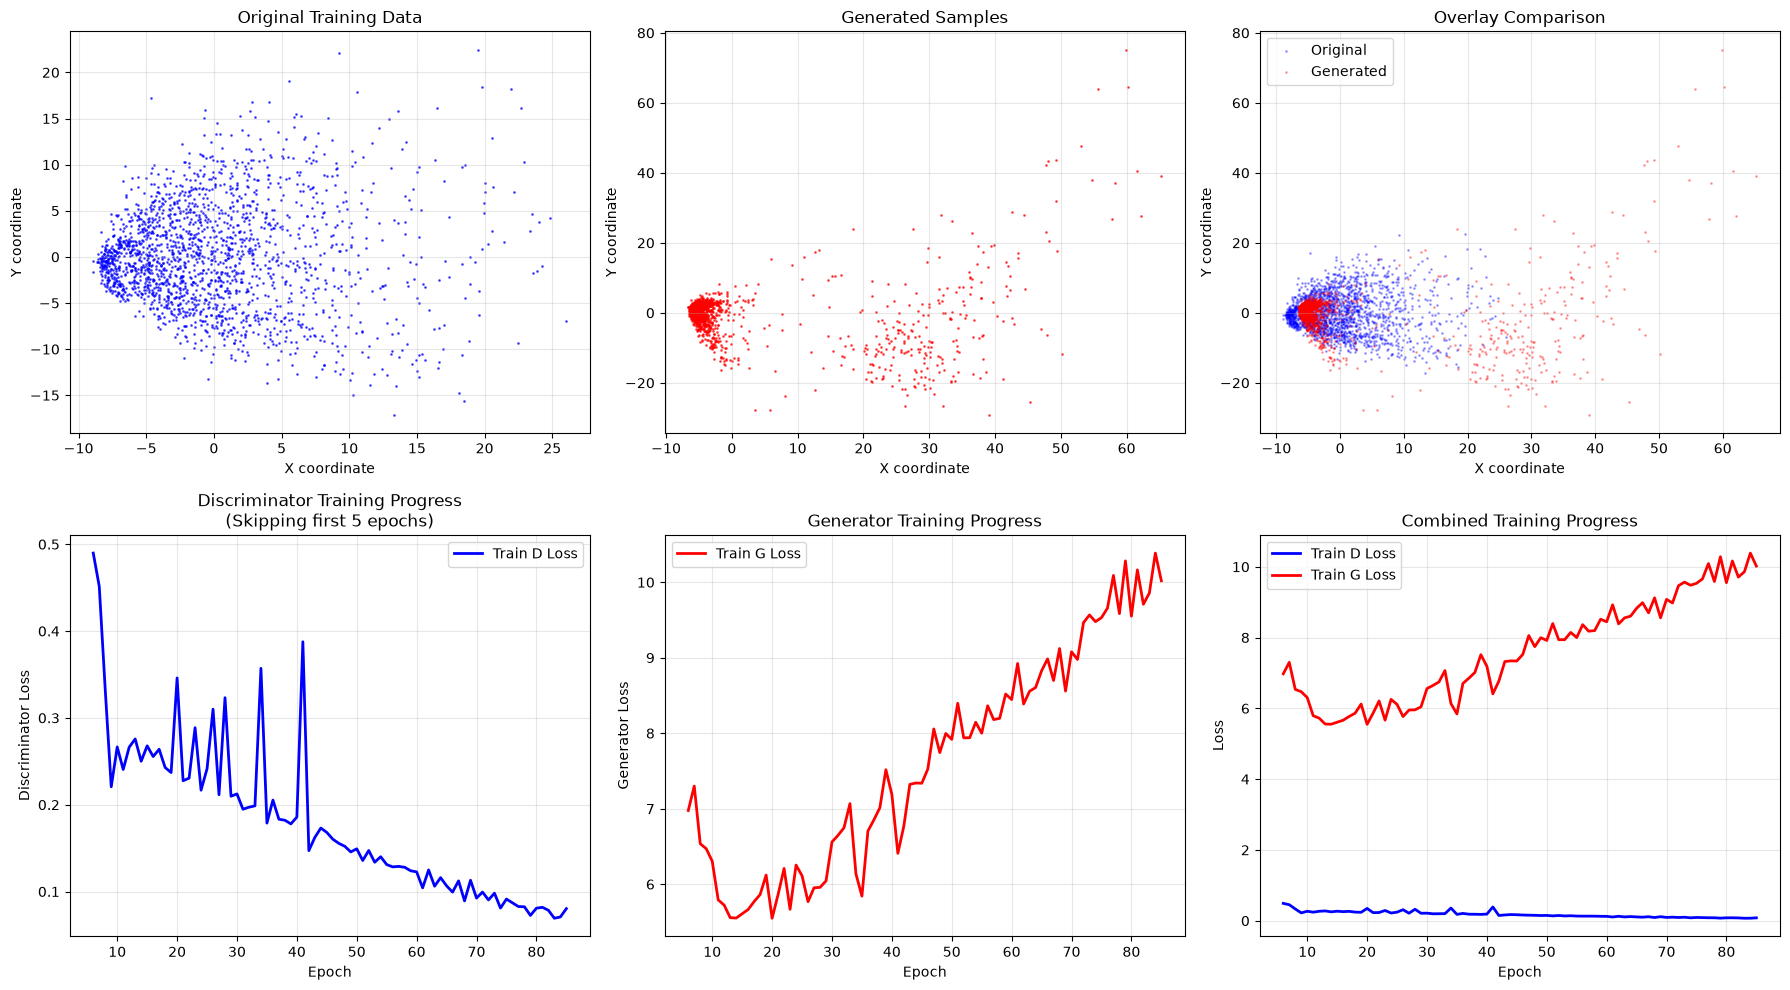

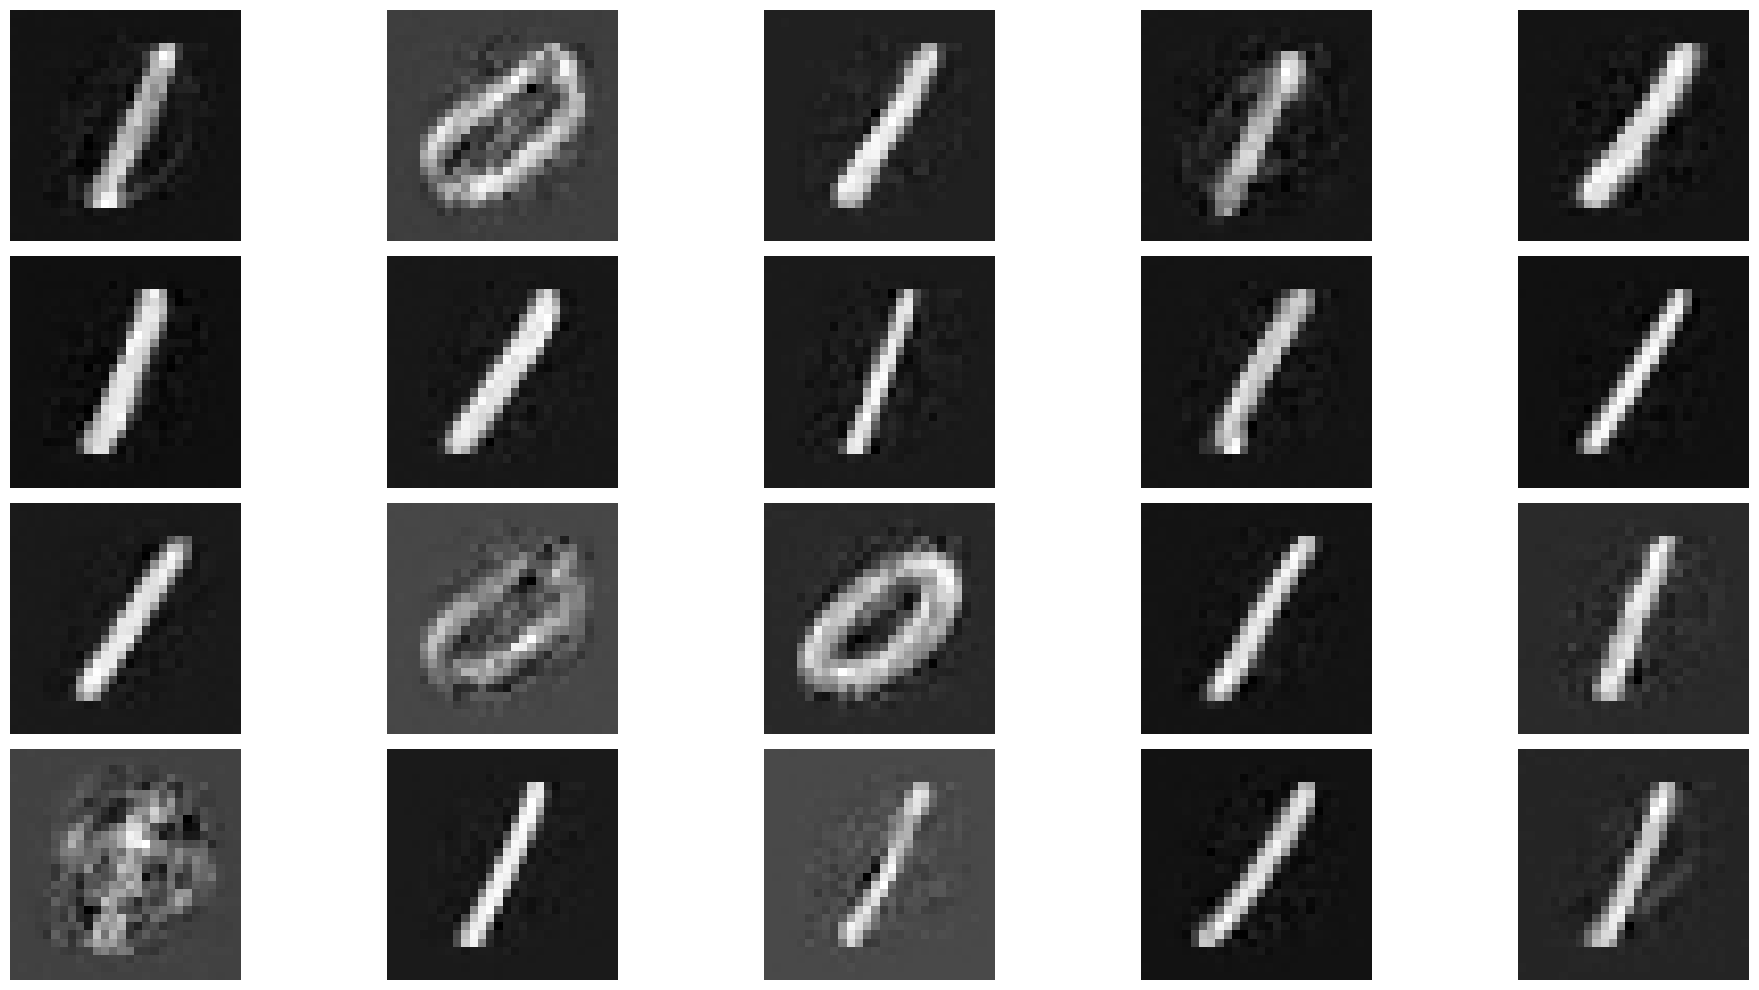

📈 Epoch 85 Summary:
   Train D Loss: 0.0803, Val D Loss: 0.1485
   Train G Loss: 10.0202, Val G Loss: 14.0255

📊 Epoch 86/100
----------------------------------------
Epoch: 86 [0/60000 (0%)]	D_loss: 0.163023	G_loss: 14.583325
Epoch: 86 [6400/60000 (11%)]	D_loss: 0.021142	G_loss: 7.800651
Epoch: 86 [12800/60000 (21%)]	D_loss: 0.018022	G_loss: 8.340003
Epoch: 86 [19200/60000 (32%)]	D_loss: 0.044079	G_loss: 10.115882
Epoch: 86 [25600/60000 (43%)]	D_loss: 0.140102	G_loss: 8.710905
Epoch: 86 [32000/60000 (53%)]	D_loss: 0.013829	G_loss: 12.790422
Epoch: 86 [38400/60000 (64%)]	D_loss: 0.133063	G_loss: 6.837531
Epoch: 86 [44800/60000 (75%)]	D_loss: 0.049730	G_loss: 11.836856
Epoch: 86 [51200/60000 (85%)]	D_loss: 0.139217	G_loss: 9.295227
Epoch: 86 [57600/60000 (96%)]	D_loss: 0.025329	G_loss: 18.328918
====> Epoch: 86 Train D_loss: 0.0680, Train G_loss: 10.3611
====> Epoch: 86 Val D_loss: 0.0685, Val G_loss: 7.8343
📈 Epoch 86 Summary:
   Train D Loss: 0.0680, Val D Loss: 0.0685
   Train G Loss

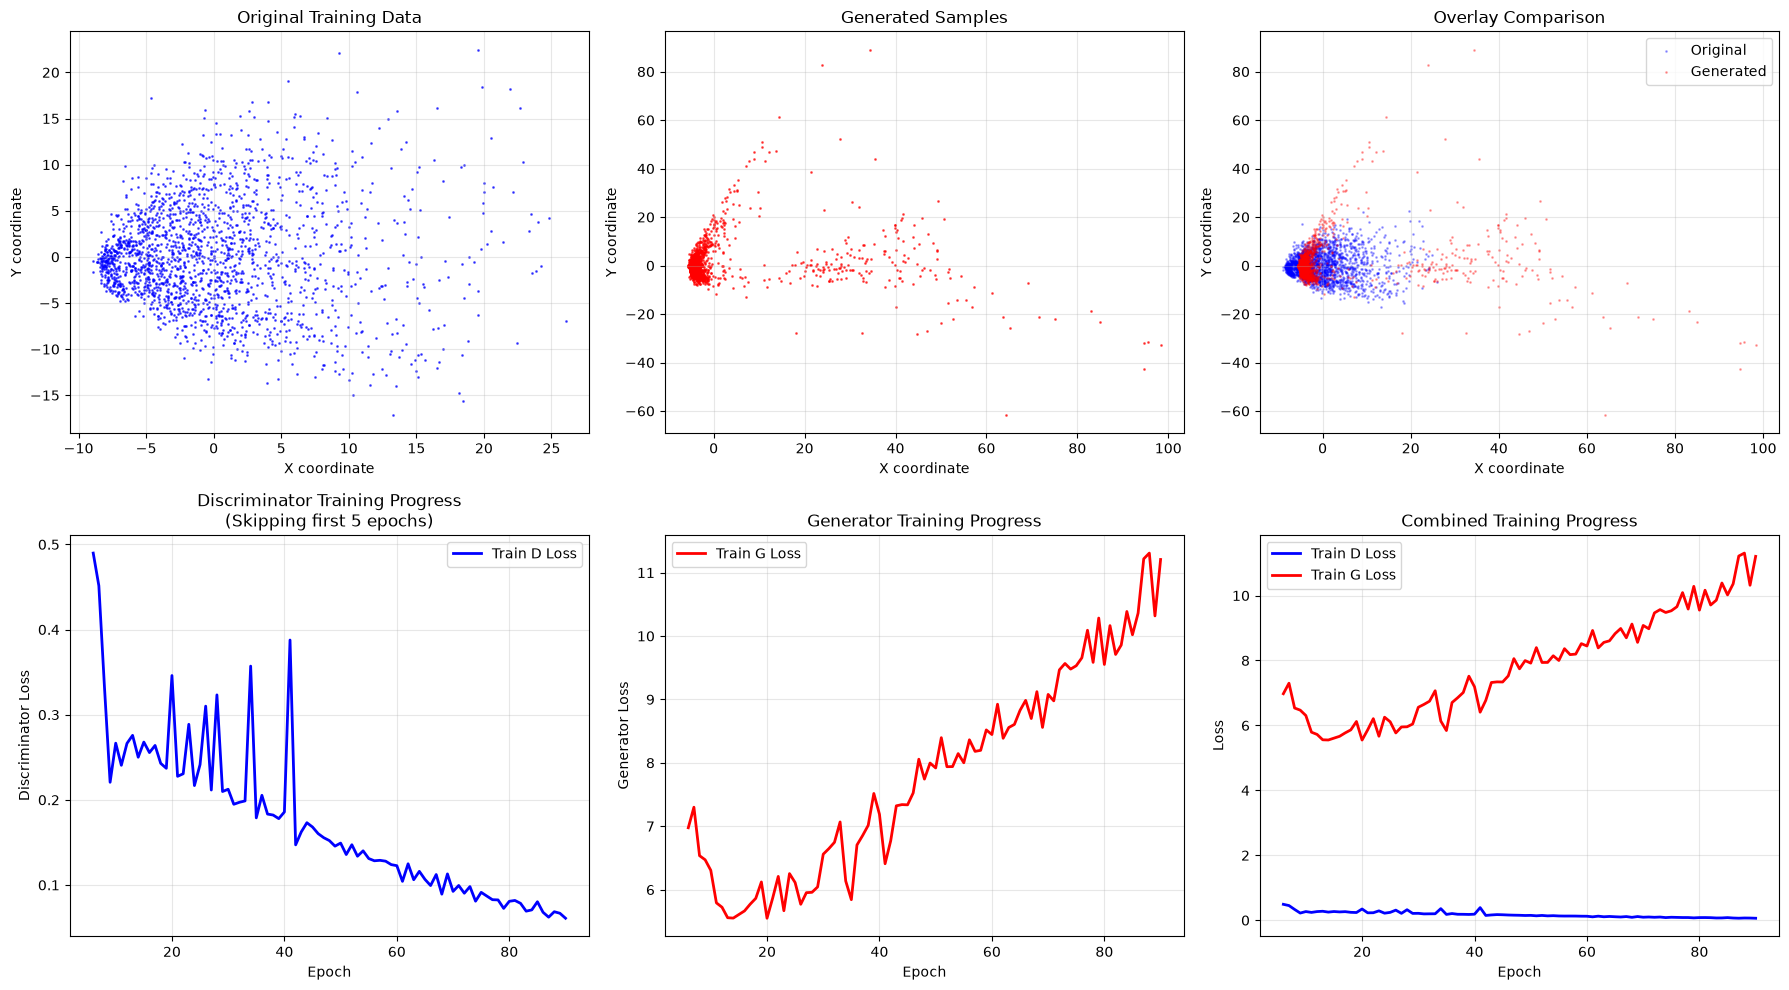

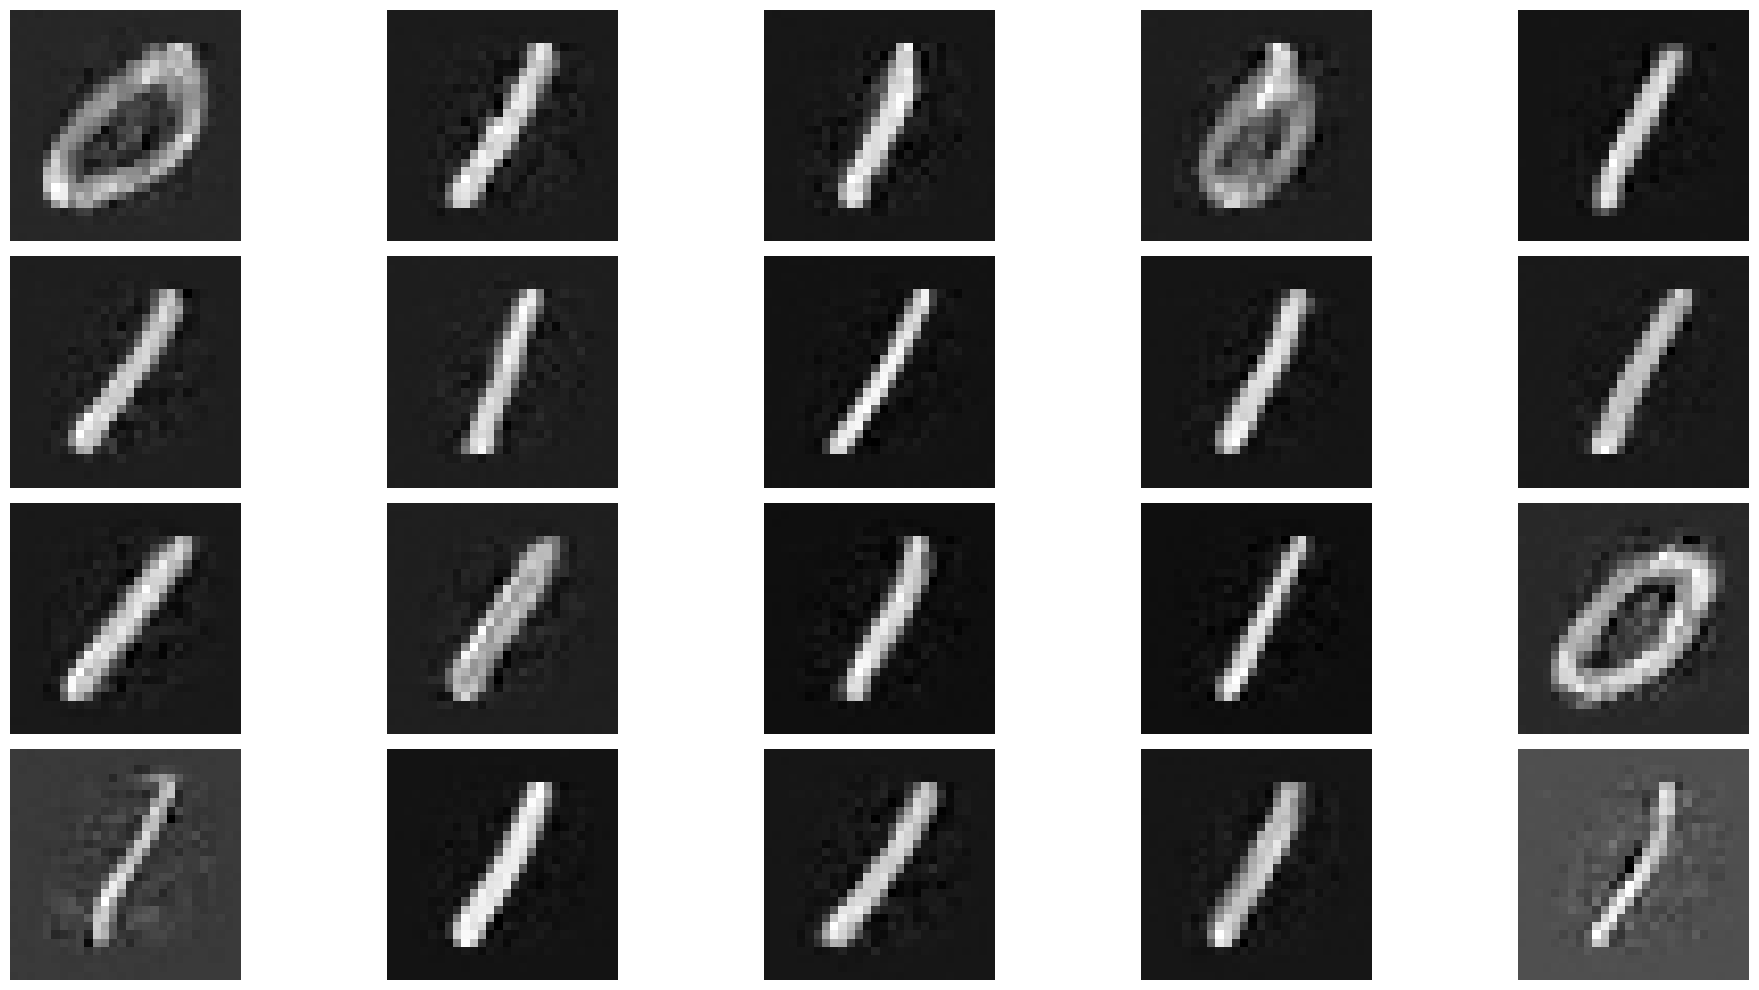

📈 Epoch 90 Summary:
   Train D Loss: 0.0610, Val D Loss: 0.0770
   Train G Loss: 11.2073, Val G Loss: 9.7559

📊 Epoch 91/100
----------------------------------------
Epoch: 91 [0/60000 (0%)]	D_loss: 0.017835	G_loss: 10.123328
Epoch: 91 [6400/60000 (11%)]	D_loss: 0.017743	G_loss: 8.522006
Epoch: 91 [12800/60000 (21%)]	D_loss: 0.011227	G_loss: 12.405403
Epoch: 91 [19200/60000 (32%)]	D_loss: 0.036260	G_loss: 12.187869
Epoch: 91 [25600/60000 (43%)]	D_loss: 0.150052	G_loss: 4.237947
Epoch: 91 [32000/60000 (53%)]	D_loss: 0.083917	G_loss: 5.870354
Epoch: 91 [38400/60000 (64%)]	D_loss: 0.056753	G_loss: 7.313226
Epoch: 91 [44800/60000 (75%)]	D_loss: 0.001582	G_loss: 20.564445
Epoch: 91 [51200/60000 (85%)]	D_loss: 0.036756	G_loss: 6.019301
Epoch: 91 [57600/60000 (96%)]	D_loss: 0.022466	G_loss: 18.330505
====> Epoch: 91 Train D_loss: 0.0597, Train G_loss: 11.2765
====> Epoch: 91 Val D_loss: 0.0539, Val G_loss: 12.8571
📈 Epoch 91 Summary:
   Train D Loss: 0.0597, Val D Loss: 0.0539
   Train G Loss

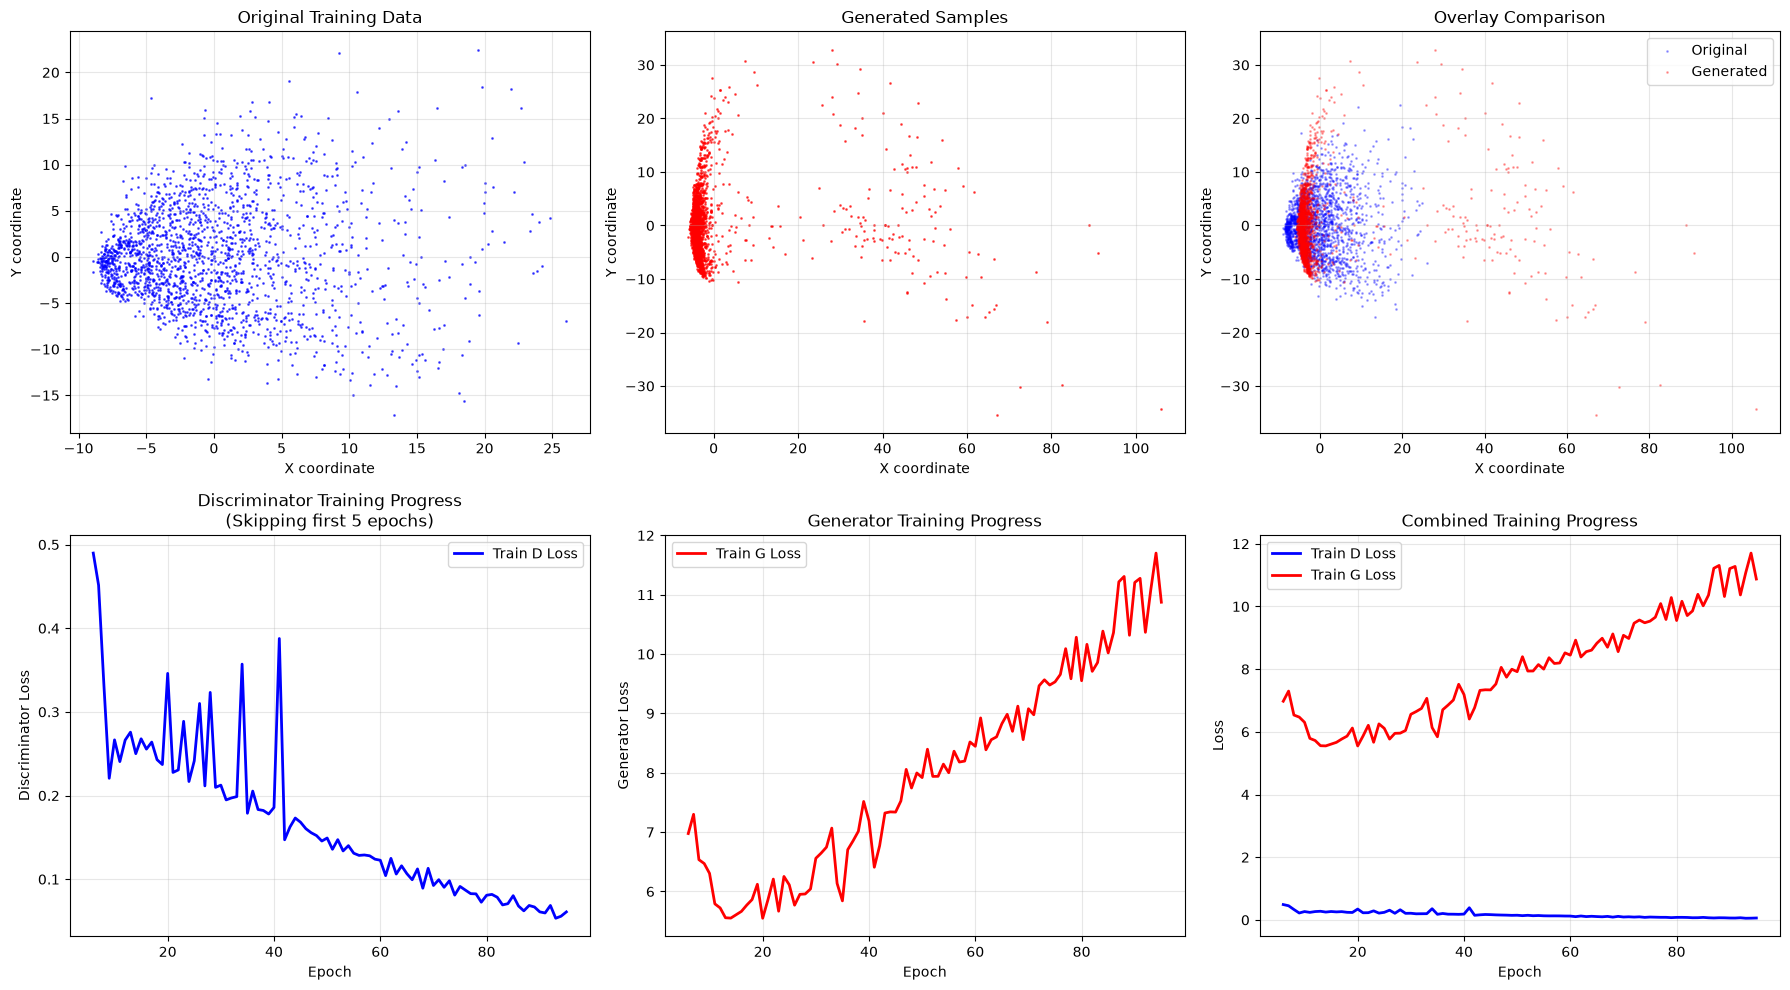

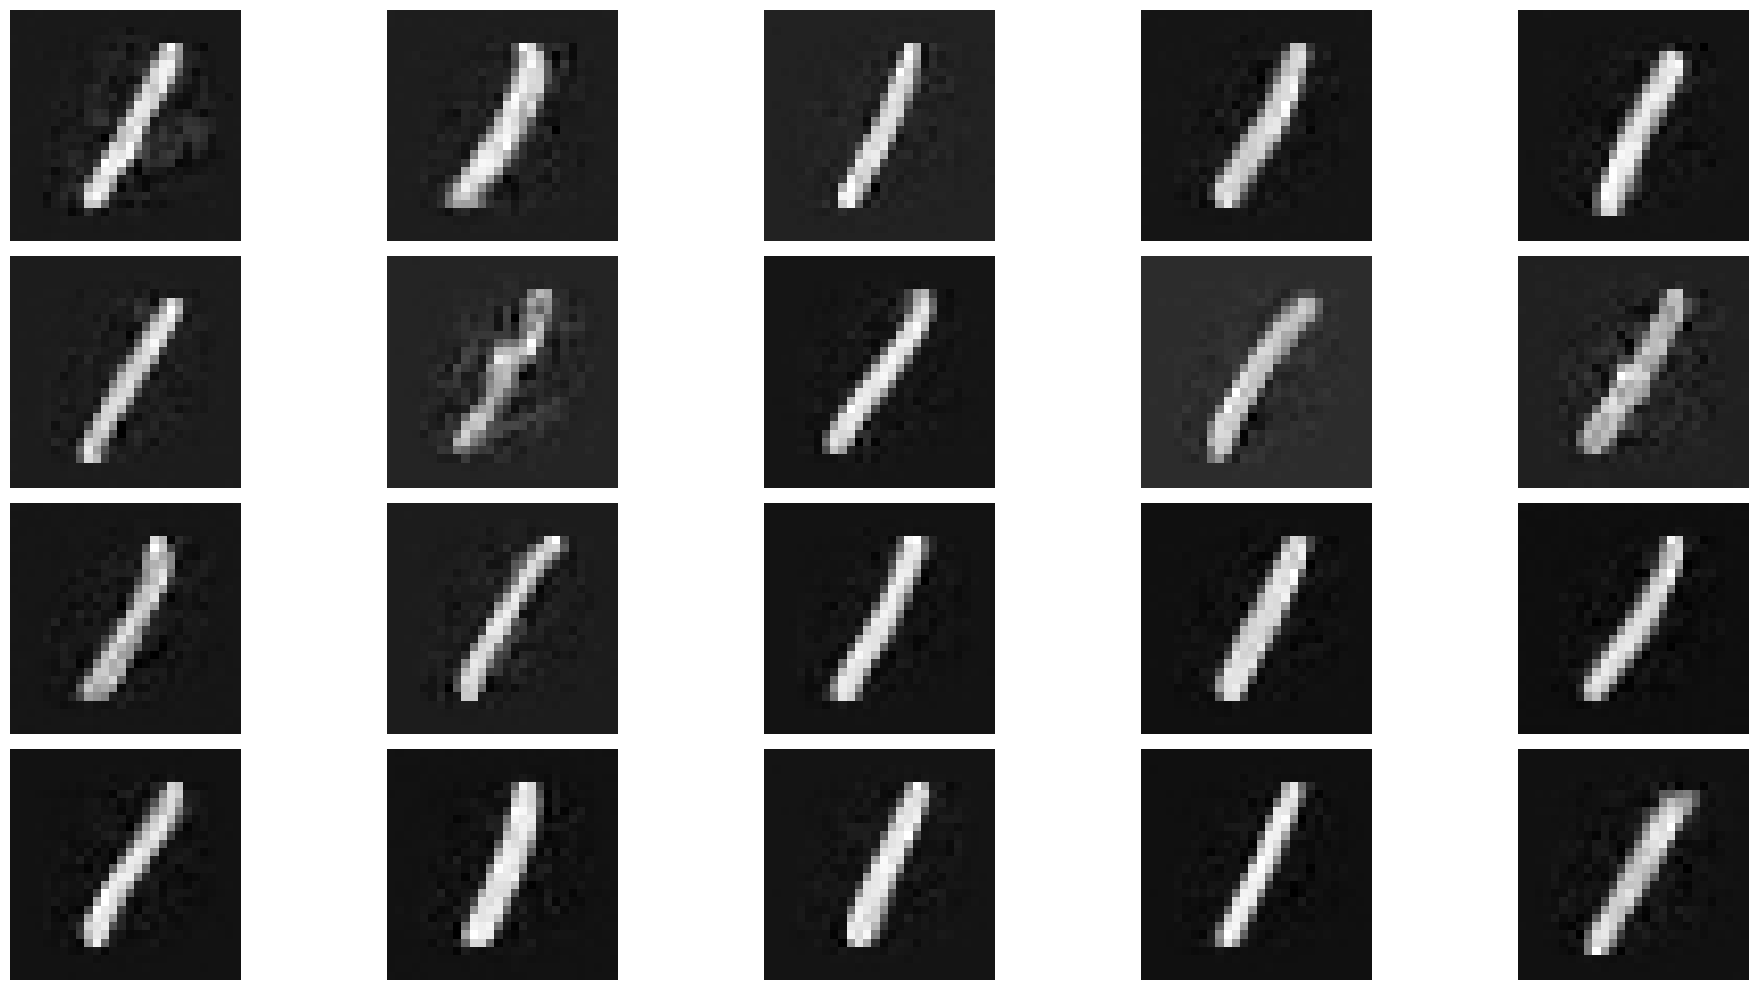

📈 Epoch 95 Summary:
   Train D Loss: 0.0609, Val D Loss: 0.0960
   Train G Loss: 10.8744, Val G Loss: 6.4467

📊 Epoch 96/100
----------------------------------------
Epoch: 96 [0/60000 (0%)]	D_loss: 0.049213	G_loss: 8.627498
Epoch: 96 [6400/60000 (11%)]	D_loss: 0.037544	G_loss: 6.359439
Epoch: 96 [12800/60000 (21%)]	D_loss: 0.087788	G_loss: 9.874199
Epoch: 96 [19200/60000 (32%)]	D_loss: 0.058931	G_loss: 11.796297
Epoch: 96 [25600/60000 (43%)]	D_loss: 0.019791	G_loss: 10.937696
Epoch: 96 [32000/60000 (53%)]	D_loss: 0.080873	G_loss: 9.451109
Epoch: 96 [38400/60000 (64%)]	D_loss: 0.115878	G_loss: 6.391189
Epoch: 96 [44800/60000 (75%)]	D_loss: 0.042446	G_loss: 8.768656
Epoch: 96 [51200/60000 (85%)]	D_loss: 0.070732	G_loss: 8.847646
Epoch: 96 [57600/60000 (96%)]	D_loss: 0.035169	G_loss: 11.143579
====> Epoch: 96 Train D_loss: 0.0491, Train G_loss: 11.4153
====> Epoch: 96 Val D_loss: 0.0576, Val G_loss: 6.7797
📈 Epoch 96 Summary:
   Train D Loss: 0.0491, Val D Loss: 0.0576
   Train G Loss: 1

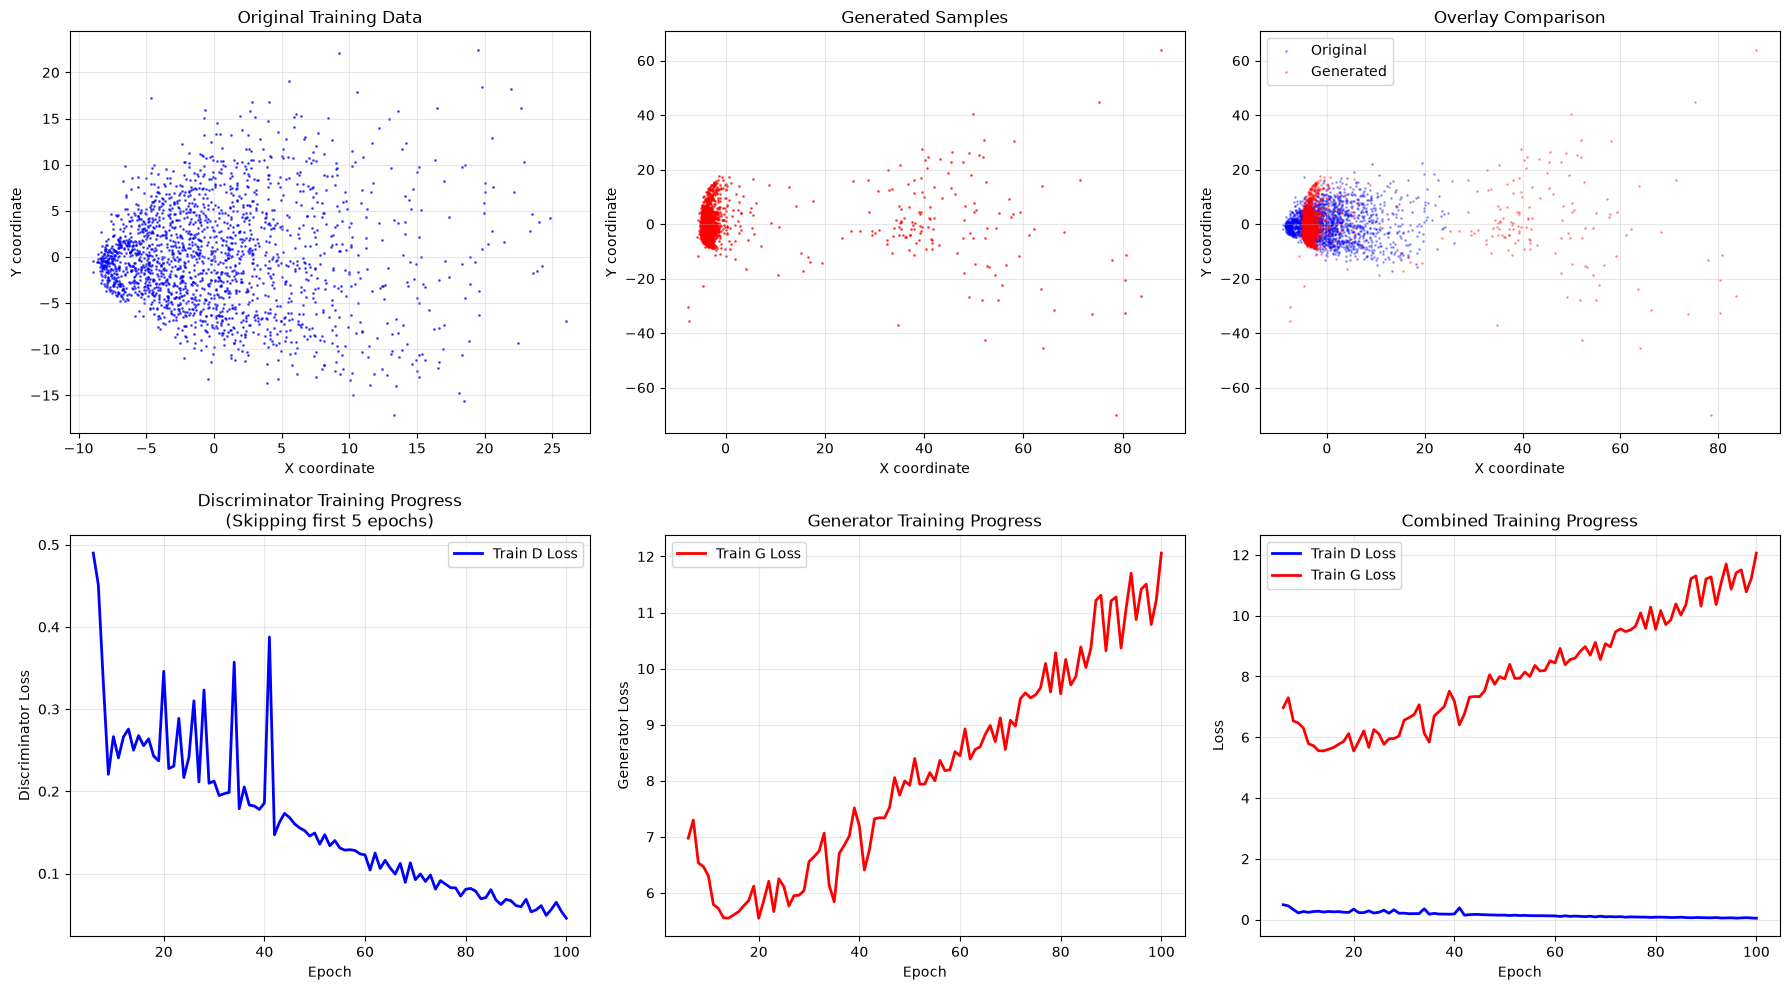

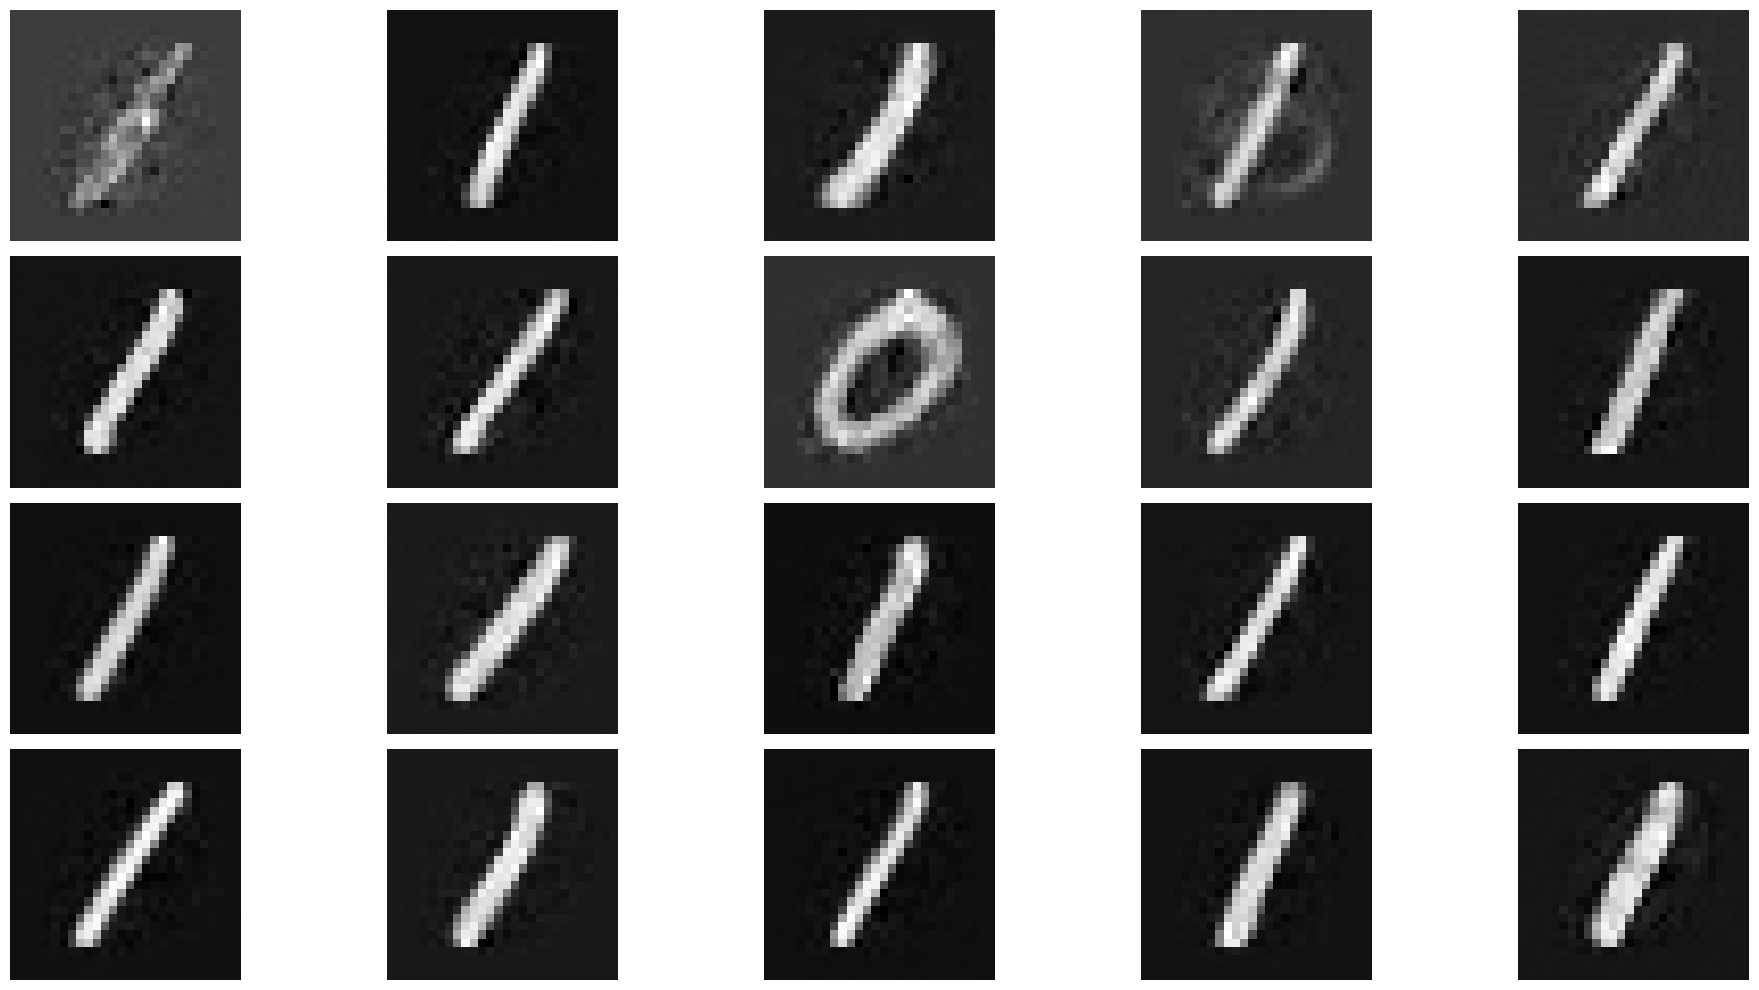

📈 Epoch 100 Summary:
   Train D Loss: 0.0456, Val D Loss: 0.0686
   Train G Loss: 12.0601, Val G Loss: 22.1262

🎉 Training completed!

🎨 Final comprehensive visualization:


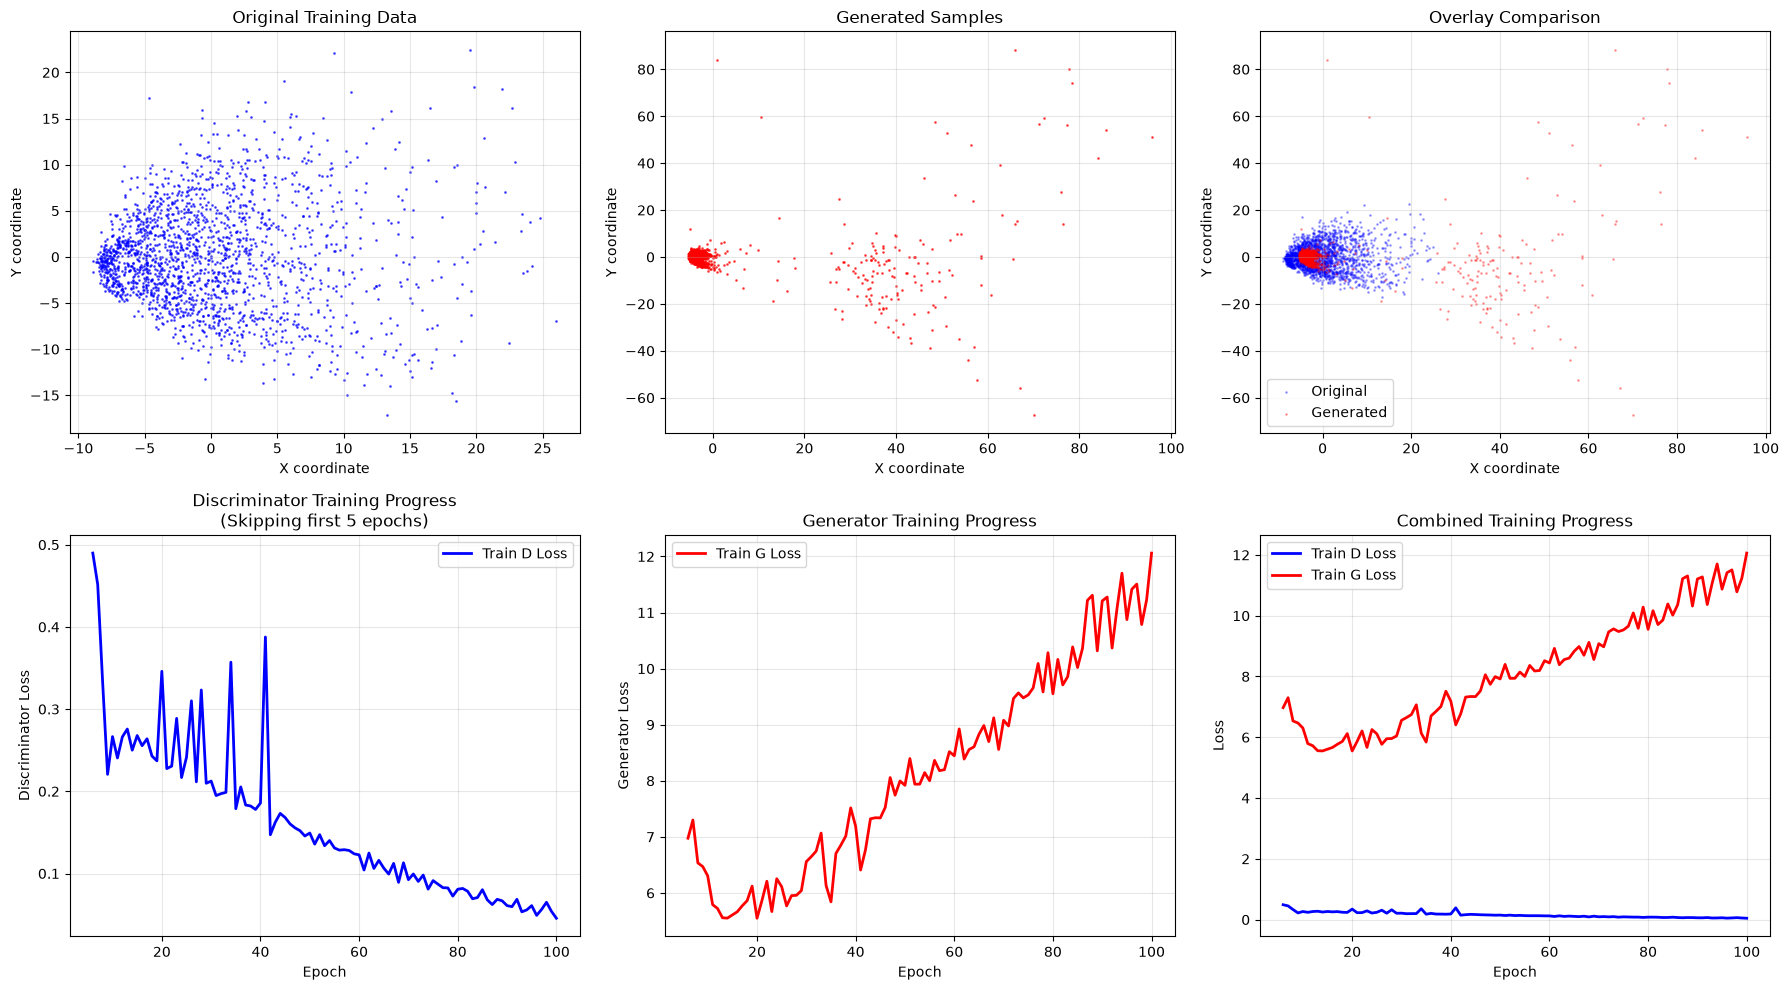

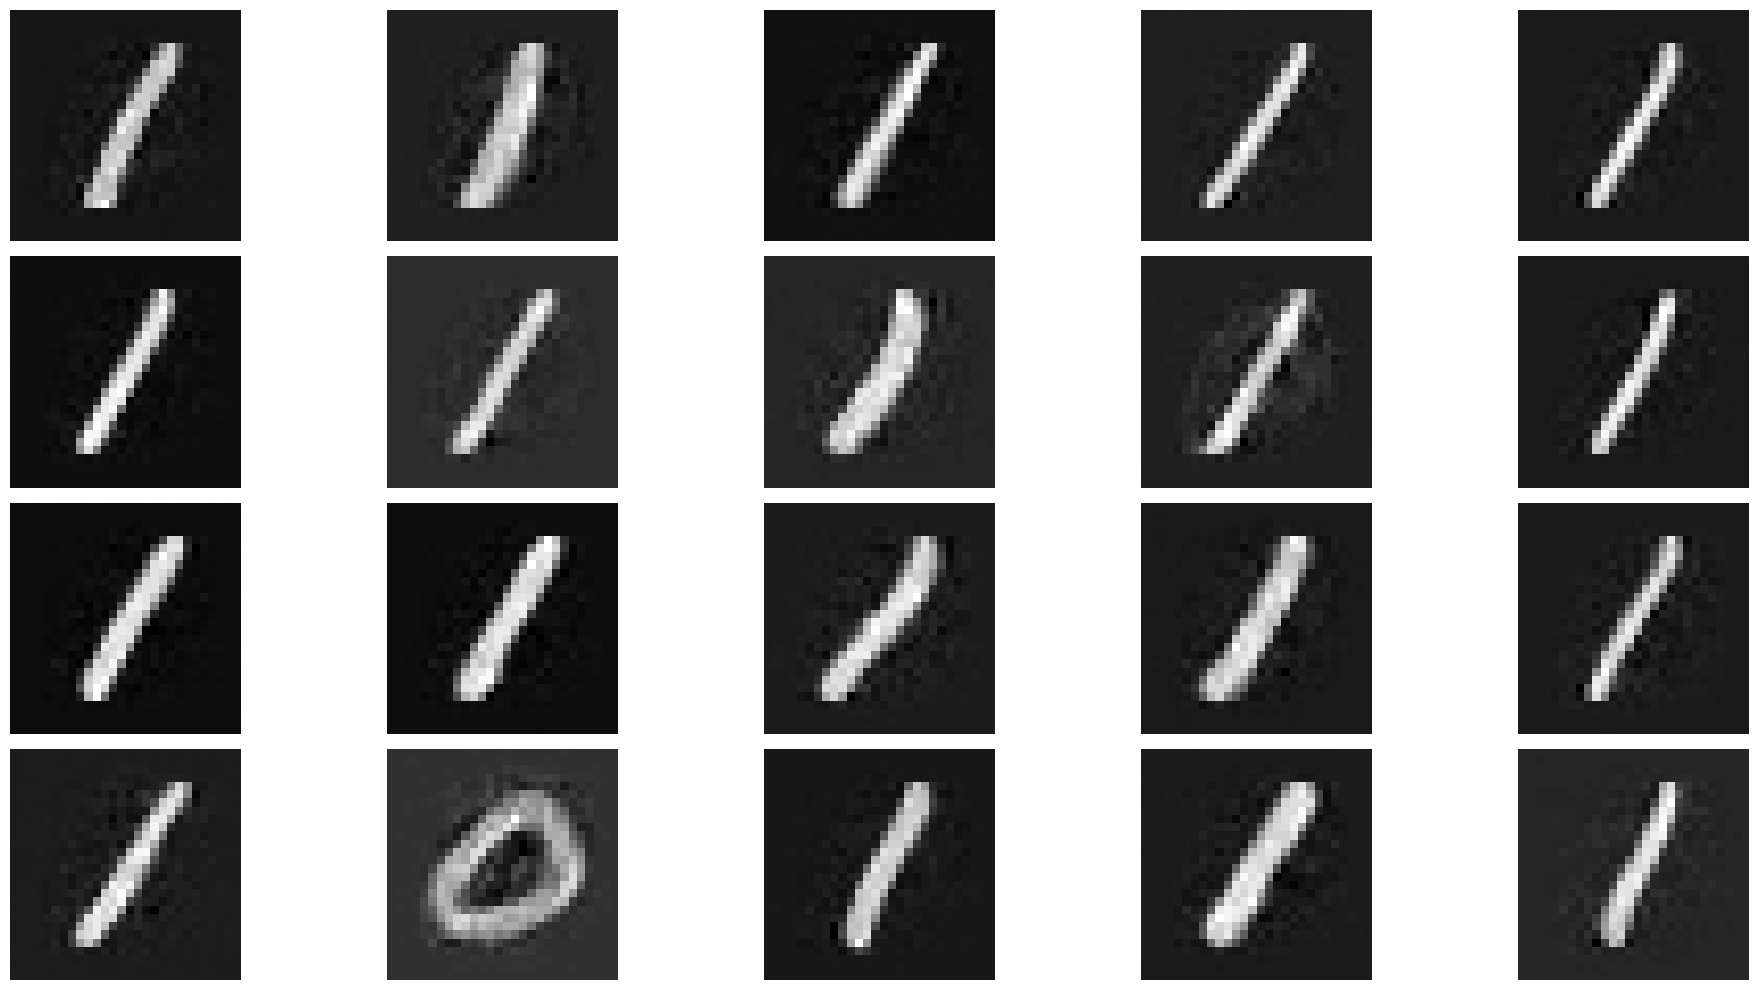

In [14]:
# Training loop
print("🎯 Starting GAN training...")
print("=" * 60)

# Lists to track training progress
train_d_losses = []
train_g_losses = []
val_d_losses = []
val_g_losses = []

# Show initial state (before training)
print("📊 Initial state (before training):")

for epoch in range(1, EPOCHS + 1):
    print(f"\n📊 Epoch {epoch}/{EPOCHS}")
    print("-" * 40)
    
    # Train for one epoch with validation
    train_d_loss, train_g_loss, val_d_loss, val_g_loss = train_epoch_with_validation(epoch)
    
    # Track losses
    train_d_losses.append(train_d_loss)
    train_g_losses.append(train_g_loss)
    val_d_losses.append(val_d_loss)
    val_g_losses.append(val_g_loss)
    
    # Visualize progress every 5 epochs
    if epoch % SAVE_PLT_INTERVAL == 0:
        print(f"\n🎨 Visualizing progress at epoch {epoch}...")
        visualize_training_progress(epoch, train_d_losses, train_g_losses, val_d_losses, val_g_losses)
    
    print(f"📈 Epoch {epoch} Summary:")
    print(f"   Train D Loss: {train_d_loss:.4f}, Val D Loss: {val_d_loss:.4f}")
    print(f"   Train G Loss: {train_g_loss:.4f}, Val G Loss: {val_g_loss:.4f}")

print("\n🎉 Training completed!")
print("=" * 60)

# Save the trained models
# torch.save(generator.state_dict(), 'generator.pth')
# torch.save(discriminator.state_dict(), 'discriminator.pth')
# print("💾 Models saved as 'generator.pth' and 'discriminator.pth'")

# Final comprehensive visualization
print("\n🎨 Final comprehensive visualization:")
visualize_training_progress(EPOCHS, train_d_losses, train_g_losses, val_d_losses, val_g_losses)


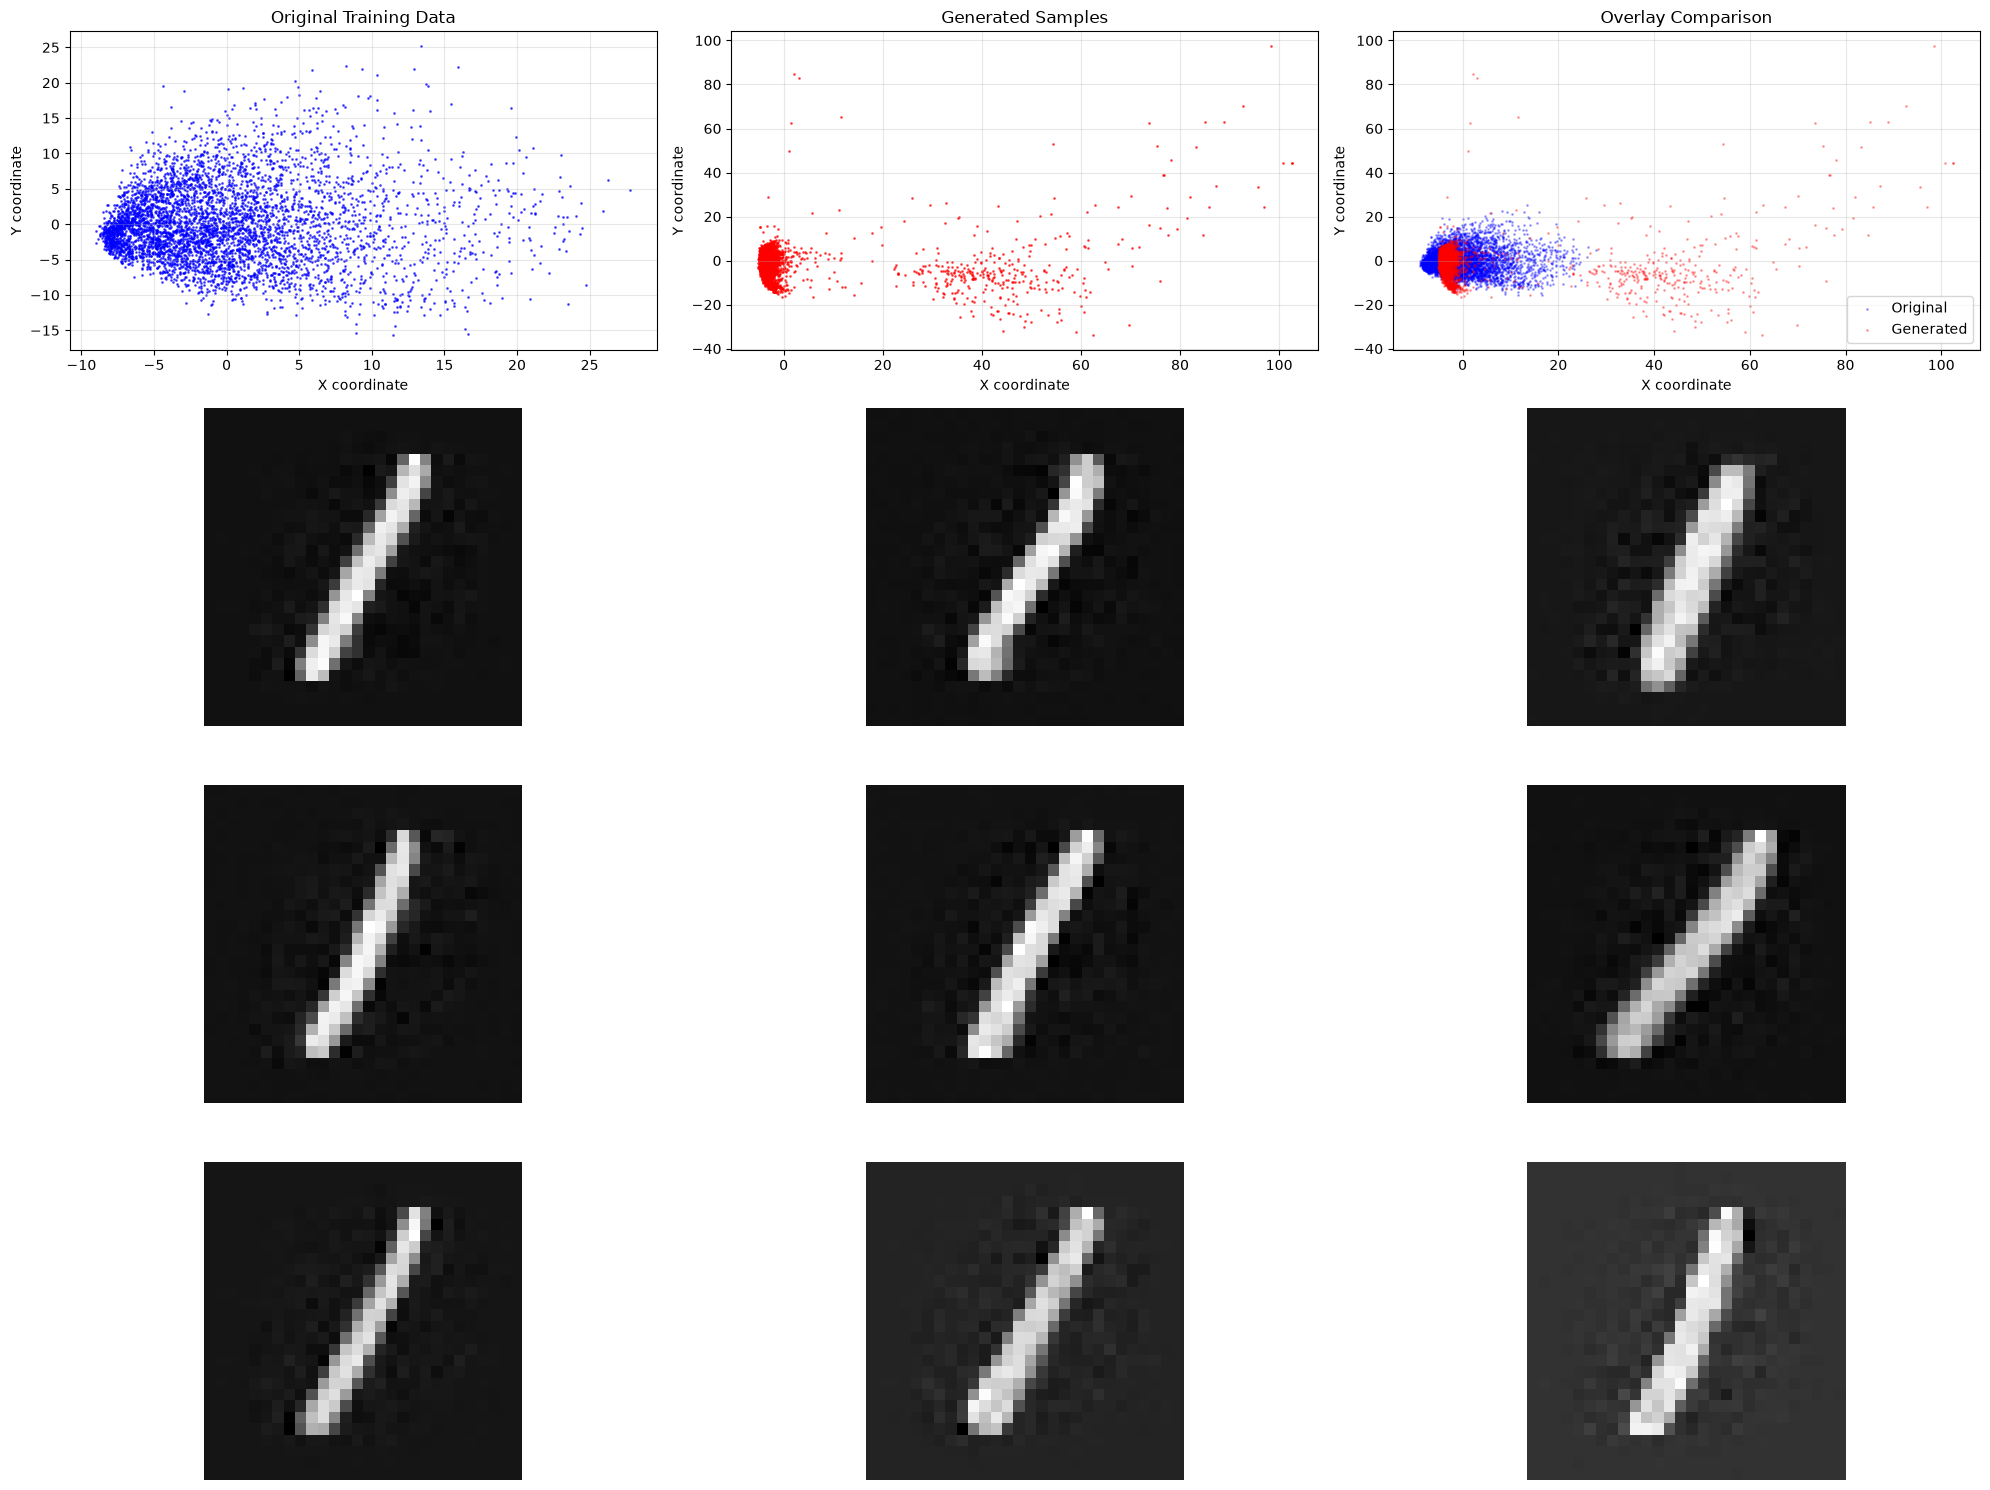

Real data confidence: 0.450
Fake data confidence: 0.000


In [15]:
# Generate a large number of samples
generated_samples = generate_samples(5000)

# Create comprehensive visualization
plt.figure(figsize=(20, 15))

train_data_reshaped = np.reshape(train_data.data[:5000], [5000, INPUT_DIM])
data_transformed = pca_fit(train_data_reshaped).transform(train_data_reshaped)
x_transformed = pca_fit(generated_samples).transform(generated_samples)

# Original training data
plt.subplot(4, 3, 1)
plt.scatter(data_transformed[:, 0], data_transformed[:, 1], c='blue', s=1, alpha=0.6)
plt.title('Original Training Data')
plt.xlabel('X coordinate')
plt.ylabel('Y coordinate')
plt.grid(True, alpha=0.3)

# Generated samples
plt.subplot(4, 3, 2)
plt.scatter(x_transformed[:, 0], x_transformed[:, 1], c='red', s=1, alpha=0.6)
plt.title('Generated Samples')
plt.xlabel('X coordinate')
plt.ylabel('Y coordinate')
plt.grid(True, alpha=0.3)

# Overlay comparison
plt.subplot(4, 3, 3)
plt.scatter(data_transformed[:, 0], data_transformed[:, 1], c='blue', s=1, alpha=0.3, label='Original')
plt.scatter(x_transformed[:, 0], x_transformed[:, 1], c='red', s=1, alpha=0.3, label='Generated')
plt.title('Overlay Comparison')
plt.xlabel('X coordinate')
plt.ylabel('Y coordinate')
plt.legend()
plt.grid(True, alpha=0.3)


for i in range(9):
    plt.subplot(4, 3, 3 + i + 1)
    plt.imshow(np.reshape(generated_samples[i], [28, 28]).squeeze(), cmap="gray")
    plt.axis("off")

plt.tight_layout()
plt.show()


generator.eval()
discriminator.eval()
with torch.no_grad():
    # Test on real data
    real_batch = train_data.data[:100].to(device).float()
    real_batch = real_batch.reshape([100, INPUT_DIM])
    real_pred = discriminator(real_batch).mean().item()

    # Test on fake data
    noise = torch.randn(100, NOISE_DIM).to(device)
    fake_batch = generator(noise)
    fake_pred = discriminator(fake_batch).mean().item()

print(f'Real data confidence: {real_pred:.3f}')
print(f'Fake data confidence: {fake_pred:.3f}')
